# Laboratorio 8 – Análisis de viajes de taxi de Nueva York con DuckDB y Parquet

Este notebook construye un flujo reproducible para descargar, consultar, transformar y visualizar los registros de viajes de taxis amarillos y verdes publicados por la New York City Taxi & Limousine Commission, TLC, en formato Parquet. Todo el trabajo analítico se resuelve con DuckDB dentro del ambiente de Docker Compose del repositorio, sin un servidor de base de datos y sin cargar los datos completos en memoria con Pandas.

El cuaderno sigue el crecimiento progresivo del conjunto de datos. Primero se prepara y verifica el ambiente y se completa el script de descarga para obtener los archivos de 2026. Con esos archivos se exploran directamente los Parquet, se identifican problemas de calidad y se realiza un análisis exploratorio con preguntas propias. Después se incorpora 2024 sin modificar las consultas, se compara el desempeño de consultar Parquet frente a una tabla materializada en DuckDB con distintos volúmenes de datos y se construyen los indicadores del tablero de Metabase. Finalmente se incorpora 2025, se actualizan los indicadores para los tres años, se analiza su evolución y se discuten las ventajas y limitaciones observadas.

Las consultas SQL viven en la carpeta sql, las funciones compartidas en scripts/taxis.py y cada consulta ejecutada se documenta automáticamente en docs/consultas.md con su objetivo, fuentes, resultado y decisión.

## Verificación de entorno

Se comprueba la versión de Python y el ejecutable utilizado, que los paquetes instalados coincidan con las versiones fijadas en requirements.txt, que existan las carpetas y scripts del repositorio y cuántos archivos de datos hay disponibles. Los archivos Parquet pueden no existir en la primera ejecución, porque se descargan en el Ejercicio 2.

In [1]:
import importlib.metadata as metadata
import os
import platform
import sys
from pathlib import Path

# raiz del repositorio, valida dentro del contenedor y en una ejecucion local
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SEPARADOR = "-" * 60

print("VERIFICACION DE ENTORNO")
print(SEPARADOR)
print(f"Python       : {platform.python_version()}")
print(f"Ejecutable   : {sys.executable}")
print(f"Sistema      : {platform.platform()}")
print(f"Contenedor   : {'Docker' if Path('/.dockerenv').exists() else 'no se detecta Docker'}")
print(f"Raiz         : {RAIZ}")
print(SEPARADOR)

# versiones fijadas en requirements.txt frente a las instaladas
fijadas = dict(linea.split("==") for linea in (RAIZ / "requirements.txt").read_text().splitlines() if "==" in linea)
for paquete, version in fijadas.items():
    try:
        instalada = metadata.version(paquete)
    except metadata.PackageNotFoundError:
        instalada = "no instalado"
    estado = "ok" if instalada == version else f"se esperaba {version}"
    print(f"{paquete:<14}{instalada:<16}{estado}")
print(SEPARADOR)

rutas = ["data/raw", "data/processed", "notebooks", "docs", "scripts/download_data.py", "scripts/taxis.py",
         "scripts/benchmark.py", "scripts/construir_tablero.py", "scripts/graficos_tablero.py",
         "sql/01_exploracion_parquet.sql", "sql/02_analisis_exploratorio.sql", "sql/03_incorporacion.sql",
         "sql/04_benchmark.sql", "sql/05_indicadores.sql", "requirements.txt"]
for ruta in rutas:
    print(f"{ruta:<36}{'existe' if (RAIZ / ruta).exists() else 'NO EXISTE'}")
print(SEPARADOR)

parquet_locales = sorted((RAIZ / "data" / "raw").glob("*/*/*.parquet"))
zonas_locales = (RAIZ / "data" / "raw" / "zonas" / "taxi_zone_lookup.csv").exists()
print(f"Archivos Parquet descargados : {len(parquet_locales)}")
print(f"Tabla de zonas descargada    : {'si' if zonas_locales else 'no'}")

VERIFICACION DE ENTORNO
------------------------------------------------------------
Python       : 3.11.14
Ejecutable   : /usr/local/bin/python3.11
Sistema      : Linux-5.15.167.4-microsoft-standard-WSL2-x86_64-with-glibc2.41
Contenedor   : Docker
Raiz         : /workspace
------------------------------------------------------------
duckdb        1.5.5           ok
jupyterlab    4.6.4           ok
pandas        3.0.6           ok
pyarrow       25.0.1          ok
matplotlib    3.11.2          ok
requests      2.34.2          ok
------------------------------------------------------------
data/raw                            existe
data/processed                      existe
notebooks                           existe
docs                                existe
scripts/download_data.py            existe
scripts/taxis.py                    existe
scripts/benchmark.py                existe
scripts/construir_tablero.py        existe
scripts/graficos_tablero.py         existe
sql/01_exploracion

## Configuración del análisis

Las rutas del proyecto se definen una sola vez en esta celda y se reutilizan en todo el cuaderno. Se importan el módulo compartido scripts/taxis.py, que contiene la conexión a DuckDB, la vista normalizada de viajes, el catálogo de consultas SQL y la bitácora que documenta cada consulta, y el módulo scripts/graficos_tablero.py, que dibuja los indicadores. También se definen funciones auxiliares para guardar figuras numeradas, ejecutar los scripts del repositorio y construir las listas de archivos que reciben las consultas.

La conexión principal de DuckDB es en memoria, con un límite de memoria y una carpeta temporal para que las operaciones grandes se desborden a disco en lugar de fallar. Las vistas no copian datos, de modo que cada consulta lee directamente los archivos Parquet.

In [2]:
import subprocess
import time

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import requests
from IPython.display import Image, display

DIR_SCRIPTS = RAIZ / "scripts"
DIR_SQL = RAIZ / "sql"
DIR_DOCS = RAIZ / "docs"
DIR_FIGURAS = DIR_DOCS / "figures"
DIR_BENCHMARK = DIR_DOCS / "benchmark"
DIR_TABLERO = DIR_DOCS / "tablero"
SCRIPT_DESCARGA = DIR_SCRIPTS / "download_data.py"
ARCHIVO_MANIFIESTO = RAIZ / "data" / "processed" / "manifiesto_descargas.csv"
ARCHIVO_CONSULTAS = DIR_DOCS / "consultas.md"
ARCHIVO_VISTA = DIR_SQL / "vista_viajes_generada.sql"
ARCHIVO_INDICE_FIGURAS = DIR_FIGURAS / "indice_figuras.csv"
REPETICIONES_BENCHMARK = 5

sys.path.insert(0, str(DIR_SCRIPTS))
import graficos_tablero
import taxis

for carpeta in (DIR_FIGURAS, DIR_BENCHMARK, DIR_TABLERO):
    carpeta.mkdir(parents=True, exist_ok=True)
# las figuras de una corrida anterior se eliminan para que la numeracion empiece siempre en 1
for figura_anterior in DIR_FIGURAS.glob("Figura*.png"):
    figura_anterior.unlink()

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda valor: f"{valor:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

AMARILLO = graficos_tablero.AMARILLO
VERDE = graficos_tablero.VERDE
COLORES_TIPO = graficos_tablero.COLORES_TIPO
NOMBRES_TIPO = graficos_tablero.NOMBRES_TIPO
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
ETIQUETAS_COLUMNAS = {"tipo_taxi": "Tipo de taxi", "anio": "Año", "mes": "Mes", "volumen": "Volumen",
                      "metodo_pago": "Método de pago", "clasificacion": "Clasificación"}
indice_figuras = []


def guardar_figura(figura, descripcion):
    """Guarda la figura como FiguraN.png, actualiza el indice de figuras y la muestra."""
    numero = len(indice_figuras) + 1
    ruta = DIR_FIGURAS / f"Figura{numero}.png"
    # los nombres de columna que Pandas usa como titulos de ejes y leyendas se reemplazan por textos legibles
    for eje in figura.axes:
        leyenda = eje.get_legend()
        if leyenda is not None and leyenda.get_title().get_text() in ETIQUETAS_COLUMNAS:
            leyenda.set_title(ETIQUETAS_COLUMNAS[leyenda.get_title().get_text()])
        if eje.get_xlabel() in ETIQUETAS_COLUMNAS:
            eje.set_xlabel("")
    figura.savefig(ruta, dpi=150, bbox_inches="tight")
    indice_figuras.append({"numero": numero, "archivo": ruta.name, "descripcion": descripcion})
    pd.DataFrame(indice_figuras).to_csv(ARCHIVO_INDICE_FIGURAS, index=False)
    plt.show()
    print(f"Figura {numero}. {descripcion}")


def ejecutar_script(ruta, *argumentos):
    """Ejecuta un script del repositorio con el mismo interprete y muestra su salida mientras avanza."""
    texto = [str(a) for a in argumentos]
    print("Comando: python " + " ".join([Path(ruta).relative_to(RAIZ).as_posix(), *texto]))
    proceso = subprocess.Popen([sys.executable, str(ruta), *texto], cwd=RAIZ, text=True,
                               stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               env={**os.environ, "PYTHONUNBUFFERED": "1"})
    lineas = []
    for linea in proceso.stdout:
        print(linea, end="")
        lineas.append(linea)
    proceso.wait()
    print(f"Codigo de salida: {proceso.returncode}")
    return "".join(lineas)


def contar_descargas(salida):
    """Cuenta en la salida del script los archivos omitidos y los descargados."""
    return {"omitidos por existir": salida.count("ya existe, se omite"),
            "descargados": salida.count("descargando..."),
            "no publicados": salida.count("aun no publicado"),
            "errores de red": salida.count("no se pudo consultar")}


def parametros_fuentes(anios):
    """Listas SQL de patrones glob por tipo de taxi para las consultas directas sobre Parquet."""
    amarillos = taxis.patrones("yellow", anios)
    verdes = taxis.patrones("green", anios)
    return {"todos": taxis.lista_sql(amarillos + verdes), "amarillos": taxis.lista_sql(amarillos),
            "verdes": taxis.lista_sql(verdes)}


def describir_fuentes(anios):
    """Descripcion legible de los archivos usados como fuente."""
    return ", ".join(f"data/raw/{tipo}/{anio}/*.parquet" for tipo in taxis.TIPOS_TAXI for anio in anios)


def resumen_manifiesto():
    """Resume el manifiesto de verificacion por anio, tipo de taxi y diagnostico."""
    manifiesto = pd.read_csv(ARCHIVO_MANIFIESTO)
    resumen = (manifiesto.groupby(["anio", "tipo", "diagnostico"], as_index=False)
               .agg(meses=("mes", "count"), registros=("registros", "sum"), mb_locales=("tamanio_local", "sum")))
    resumen["registros"] = resumen["registros"].astype("int64")
    resumen["mb_locales"] = resumen["mb_locales"] / 1e6
    return manifiesto, resumen


con = taxis.conectar()
bitacora = taxis.Bitacora(con)
print(f"DuckDB {duckdb.__version__}, consultas en el catalogo: {len(bitacora.catalogo)}")
limite_memoria = con.execute("SELECT current_setting('memory_limit')").fetchone()[0]
print(f"Limite de memoria: {limite_memoria}")

DuckDB 1.5.5, consultas en el catalogo: 52
Limite de memoria: 2.7 GiB


## Ejercicio 1 – Preparación del ambiente reproducible con Docker Compose

El objetivo es levantar el ambiente proporcionado por el repositorio, comprobar que sus servicios funcionan e identificar las herramientas disponibles antes de trabajar con los datos. El ambiente tiene dos servicios definidos en docker-compose.yml: lab, con Python, JupyterLab y DuckDB, y metabase, con Metabase y el controlador de DuckDB. La verificación se hace desde este mismo notebook, que se ejecuta dentro del servicio lab.

### 1.1 – Fork, clonación y levantamiento del ambiente

El repositorio del docente se bifurca en GitHub y se trabaja sobre el fork propio. El ambiente se levanta desde la raíz del repositorio clonado con los siguientes comandos:

```bash
git clone https://github.com/<usuario>/duckdb.git
cd duckdb
docker compose up --build -d
docker compose ps
```

La primera construcción descarga las imágenes base, instala los paquetes de requirements.txt y descarga Metabase junto con el controlador de DuckDB. Al terminar, JupyterLab queda disponible en http://localhost:8888 y Metabase en http://localhost:3001. Ambos puertos se publican solo en 127.0.0.1, por lo que los servicios no quedan expuestos a la red local. El procedimiento completo queda documentado en el README del repositorio.

### 1.2 – Verificación de los servicios

Se consulta la API de cada servicio. Dentro de la red de Docker Compose, el contenedor lab alcanza a Metabase por el nombre del servicio. También se comprueba que DuckDB responde y que su versión coincide con la del controlador instalado en Metabase, requisito para que ambos lean el mismo archivo .duckdb.

In [3]:
import re

servicios = {
    "JupyterLab, servicio lab": "http://localhost:8888/api",
    "Metabase, servicio metabase": "http://metabase:3000/api/health",
}
# Metabase puede tardar uno o dos minutos en iniciar, por eso se reintenta durante un tiempo limitado
INTENTOS_SERVICIO = 12
ESPERA_SERVICIO = 10


def consultar_servicio(url):
    """Devuelve la respuesta del servicio o el nombre del error tras agotar los intentos."""
    for intento in range(1, INTENTOS_SERVICIO + 1):
        try:
            return requests.get(url, timeout=5, proxies={"http": None, "https": None})
        except requests.RequestException as error:
            ultimo_error = type(error).__name__
            if intento < INTENTOS_SERVICIO:
                time.sleep(ESPERA_SERVICIO)
    return ultimo_error


print("SERVICIOS DEL AMBIENTE")
print(SEPARADOR)
for nombre, url in servicios.items():
    respuesta = consultar_servicio(url)
    if isinstance(respuesta, str):
        print(f"{nombre:<30}sin respuesta, {respuesta}")
    else:
        print(f"{nombre:<30}HTTP {respuesta.status_code}  {respuesta.text.strip()[:60]}")

# version de Metabase informada por el propio servicio
try:
    propiedades = requests.get("http://metabase:3000/api/session/properties", timeout=5,
                               proxies={"http": None, "https": None}).json()
    version_metabase = propiedades.get("version", {}).get("tag", "no informada")
except (requests.RequestException, ValueError):
    version_metabase = "sin respuesta del servicio"

# metabase.Dockerfile no esta montado dentro del contenedor lab, solo existe al ejecutar desde la raiz del repositorio
archivo_metabase = RAIZ / "metabase.Dockerfile"
if archivo_metabase.exists():
    version_driver = re.search(r"DUCKDB_DRIVER_VERSION=(\S+)", archivo_metabase.read_text()).group(1)
else:
    version_driver = "1.5.5.0, valor fijado en metabase.Dockerfile"

print(SEPARADOR)
print(f"DuckDB en el servicio lab        : {con.execute('SELECT version()').fetchone()[0]}")
print(f"Metabase                         : {version_metabase}")
print(f"Controlador DuckDB de Metabase   : {version_driver}")
print(f"Versiones alineadas              : {'si' if version_driver.startswith(duckdb.__version__) else 'no'}")

SERVICIOS DEL AMBIENTE
------------------------------------------------------------
JupyterLab, servicio lab      HTTP 200  {"version": "2.21.1"}


Metabase, servicio metabase   HTTP 200  {"status":"ok"}


------------------------------------------------------------
DuckDB en el servicio lab        : v1.5.5
Metabase                         : v0.63.19
Controlador DuckDB de Metabase   : 1.5.5.0, valor fijado en metabase.Dockerfile
Versiones alineadas              : si


### 1.3 – Herramientas disponibles en el ambiente

Se listan los paquetes de Python instalados en el servicio lab, las herramientas de línea de comandos y las extensiones de DuckDB disponibles.

In [4]:
import shutil

paquetes = sorted((d.metadata["Name"], d.version) for d in metadata.distributions())
principales = {"duckdb", "pandas", "pyarrow", "matplotlib", "requests", "jupyterlab", "numpy", "ipykernel"}
display(pd.DataFrame([p for p in paquetes if p[0].lower() in principales], columns=["paquete", "version"]))
print(f"Paquetes de Python instalados en total: {len(paquetes)}")
print(SEPARADOR)
for herramienta in ("python", "pip", "jupyter", "curl", "git", "java"):
    print(f"{herramienta:<10}{shutil.which(herramienta) or 'no disponible en el servicio lab'}")
print(SEPARADOR)
display(con.execute("""
    SELECT extension_name, loaded, installed, description
    FROM duckdb_extensions()
    WHERE loaded OR installed
    ORDER BY extension_name
""").df())

,paquete,version
0,duckdb,1.5.5
1,ipykernel,7.4.0
2,jupyterlab,4.6.4
3,matplotlib,3.11.2
4,numpy,2.4.6
5,pandas,3.0.6
6,pyarrow,25.0.1
7,requests,2.34.2


Paquetes de Python instalados en total: 105
------------------------------------------------------------
python    /usr/local/bin/python
pip       /usr/local/bin/pip
jupyter   /usr/local/bin/jupyter
curl      /usr/bin/curl
git       no disponible en el servicio lab
java      no disponible en el servicio lab
------------------------------------------------------------


,extension_name,loaded,installed,description
0,core_functions,True,True,Core function library
1,icu,True,True,Adds support for time zones and collations using the ICU library
2,json,True,True,Adds support for JSON operations
3,parquet,True,True,Adds support for reading and writing parquet files


El servicio lab ofrece Python 3.11 con DuckDB 1.5.5 como motor de consultas, PyArrow para leer metadatos Parquet, Pandas para manejar resultados pequeños, Matplotlib para las figuras, Requests para las descargas y JupyterLab como interfaz de trabajo; también incluye curl. La lectura de Parquet y CSV viene integrada en DuckDB, por lo que no es necesario instalar extensiones adicionales. El servicio metabase ofrece Metabase sobre Java 21 con el controlador oficial de DuckDB, que es la herramienta de visualización del Ejercicio 7. Java y Metabase no están en el servicio lab, por eso aparecen como no disponibles en la lista anterior.

### 1.4 – Propósito de cada directorio

| Directorio o archivo | Propósito | Uso en esta resolución |
| --- | --- | --- |
| data/raw | Datos originales tal como los publica la fuente, nunca se modifican | Parquet mensuales en data/raw/tipo/año y la tabla de zonas en data/raw/zonas |
| data/processed | Datos y bases generados por el código, reproducibles a partir de raw | Manifiesto de descargas, benchmark.duckdb y tablero.duckdb |
| notebooks | Cuadernos de análisis | Este notebook, que ejecuta los ejercicios en orden |
| scripts | Código Python reutilizable y ejecutable desde la línea de comandos | Descarga, módulo compartido, benchmark, construcción y gráficos del tablero |
| sql | Consultas SQL versionadas, separadas del código Python | Catálogo de consultas por ejercicio y la vista normalizada generada |
| docs | Documentación y evidencias generadas | Documentación de consultas, figuras, resultados del benchmark y evidencia del tablero |
| Dockerfile y metabase.Dockerfile | Definición de las imágenes de cada servicio | Python con versiones fijas y Metabase con el controlador de DuckDB |
| docker-compose.yml | Orquestación de los servicios, puertos y volúmenes | Monta data, notebooks, scripts, sql y docs dentro de /workspace |

Las carpetas data/raw y data/processed están excluidas de Git mediante .gitignore, de modo que el repositorio contiene el código que reproduce los datos y no los datos mismos.

### 1.5 – Importancia de un ambiente reproducible

Un proyecto de análisis de datos depende de mucho más que el código: de la versión de Python, de las versiones de las bibliotecas y del motor de consultas, de las rutas donde viven los datos y de los servicios auxiliares. Si cualquiera de esos elementos cambia, el mismo código puede producir resultados distintos o dejar de funcionar. En este laboratorio el caso es concreto, porque Metabase solo puede abrir la base de DuckDB si su controlador coincide con la versión de DuckDB que la escribió.

Con Docker Compose el ambiente completo queda descrito en archivos versionados: imágenes base con versión fija, paquetes con versión exacta y montajes de carpetas idénticos para todos. Cualquier integrante, el docente o un sistema automatizado obtiene el mismo ambiente con un solo comando, sin instalar nada en su computadora y sin depender de su sistema operativo. Esto permite repetir el análisis cuando llegan datos nuevos, verificar los resultados de otra persona y separar los errores del análisis de los errores de configuración.

## Ejercicio 2 – Sistema de descarga incremental de los datos de la TLC

Se analiza el script de descarga proporcionado, se completa para obtener los archivos de taxis amarillos y verdes de 2026 junto con la tabla de zonas, se comprueba que no vuelve a descargar archivos existentes y se verifica que el conjunto descargado está completo. El script se ejecuta desde el notebook con el mismo intérprete del ambiente, igual que se ejecutaría desde una terminal.

### 2.1 – Análisis del script proporcionado

El script original ya resolvía bien varias partes que se conservaron: consulta al servidor qué meses están publicados, omite los archivos que ya existen, descarga sobre un archivo temporal que solo se renombra al terminar y reintenta ante fallos. Las partes que impedían cumplir el laboratorio eran las siguientes:

- El año estaba fijo en la constante ANIO y en las funciones que construyen nombres y rutas, por lo que incorporar 2024 o 2025 obligaba a editar el código.
- La carpeta de destino era la ruta relativa data/raw, que depende de la carpeta desde donde se ejecuta el script. Ejecutado desde notebooks habría creado una carpeta notebooks/data/raw.
- La función esta_publicado devolvía falso ante cualquier excepción, de modo que un error de red se informaba como mes no publicado y el script terminaba con éxito aunque no hubiera descargado nada.
- No existía una forma de verificar que lo descargado estuviera completo ni un registro de lo obtenido.
- No se descargaba la tabla de zonas de la TLC, necesaria para interpretar los identificadores de zona de origen y destino.

### 2.2 – Cambios realizados al script

| Cambio | Motivo |
| --- | --- |
| Parámetro --anios con valor por defecto 2024, 2025 y 2026, y funciones que reciben el año | Incorporar un año nuevo es un cambio de parámetro y no de código |
| Rutas calculadas desde la ubicación del script con `Path(__file__)` | El resultado es el mismo sin importar la carpeta de ejecución |
| consultar_publicacion distingue publicado, no publicado por HTTP 403 o 404 y error de red | Un problema de conexión no se confunde con un mes que la TLC aún no publica |
| El resumen informa errores de red y el código de salida es 1 si hubo errores o fallos | Un proceso automatizado puede detectar una descarga incompleta |
| Descarga incremental de data/raw/zonas/taxi_zone_lookup.csv | Traducir zonas a distritos y aeropuertos en el análisis |
| Opción --verificar que compara cada archivo con el publicado y genera un manifiesto | Comprobar la completitud de la descarga y dejar evidencia en data/processed |
| Separadores de 60 guiones en las salidas | Salidas uniformes con el resto del proyecto |

### 2.3 – Descarga de los datos de 2026

El script recorre los doce meses de 2026 para cada tipo de taxi. Los meses que la TLC todavía no publica se informan como no publicados y no se consideran errores, porque la publicación tiene varias semanas de atraso.

In [5]:
salida_2026 = ejecutar_script(SCRIPT_DESCARGA, "--anios", 2026)

Comando: python scripts/download_data.py --anios 2026


ZONAS DE TAXI
------------------------------------------------------------


  zonas  listo (12.0 KiB) -> data/raw/zonas/taxi_zone_lookup.csv

YELLOW 2026
------------------------------------------------------------


  2026-01  descargando...


  2026-01  listo (61.2 MiB) -> data/raw/yellow/2026/yellow_tripdata_2026-01.parquet


...

  2026-08  descargando...


  2026-08  listo (983.9 KiB) -> data/raw/green/2026/green_tripdata_2026-08.parquet


  2026-09  aun no publicado por la TLC


  2026-10  aun no publicado por la TLC
  2026-11  aun no publicado por la TLC


  2026-12  aun no publicado por la TLC

RESUMEN
------------------------------------------------------------
  anios          : 2026
  zonas          : descargado
  descargados    : 16
  ya existian    : 0
  no publicados  : 8
      yellow 2026-09, yellow 2026-10, yellow 2026-11, yellow 2026-12, green 2026-09, green 2026-10, green 2026-11, green 2026-12
  errores de red : 0
  fallidos       : 0
------------------------------------------------------------
Codigo de salida: 0


### 2.4 – Comprobación de que no se descargan archivos existentes

Se ejecuta el mismo comando por segunda vez. Todos los archivos presentes, incluida la tabla de zonas, deben aparecer como omitidos y ninguno debe descargarse de nuevo.

In [6]:
salida_repetida = ejecutar_script(SCRIPT_DESCARGA, "--anios", 2026)
print(SEPARADOR)
for concepto, cantidad in contar_descargas(salida_repetida).items():
    print(f"{concepto:<24}{cantidad}")

Comando: python scripts/download_data.py --anios 2026


ZONAS DE TAXI
------------------------------------------------------------
  zonas  ya existe, se omite -> data/raw/zonas/taxi_zone_lookup.csv

YELLOW 2026
------------------------------------------------------------
  2026-01  ya existe, se omite
  2026-02  ya existe, se omite
  2026-03  ya existe, se omite
  2026-04  ya existe, se omite
  2026-05  ya existe, se omite
  2026-06  ya existe, se omite
  2026-07  ya existe, se omite
  2026-08  ya existe, se omite


  2026-09  aun no publicado por la TLC


  2026-10  aun no publicado por la TLC
  2026-11  aun no publicado por la TLC


  2026-12  aun no publicado por la TLC

GREEN 2026
------------------------------------------------------------
  2026-01  ya existe, se omite
  2026-02  ya existe, se omite
  2026-03  ya existe, se omite
  2026-04  ya existe, se omite
  2026-05  ya existe, se omite
  2026-06  ya existe, se omite
  2026-07  ya existe, se omite
  2026-08  ya existe, se omite


  2026-09  aun no publicado por la TLC


  2026-10  aun no publicado por la TLC


  2026-11  aun no publicado por la TLC


  2026-12  aun no publicado por la TLC

RESUMEN
------------------------------------------------------------
  anios          : 2026
  zonas          : omitido
  descargados    : 0
  ya existian    : 16
  no publicados  : 8
      yellow 2026-09, yellow 2026-10, yellow 2026-11, yellow 2026-12, green 2026-09, green 2026-10, green 2026-11, green 2026-12
  errores de red : 0
  fallidos       : 0
------------------------------------------------------------
Codigo de salida: 0
------------------------------------------------------------
omitidos por existir    17
descargados             0
no publicados           8
errores de red          0


### 2.5 – Verificación de completitud de la descarga

La opción --verificar no descarga nada. Para cada mes y tipo de taxi consulta el tamaño publicado en el servidor, lo compara con el archivo local y lee el pie del archivo Parquet para confirmar que es legible y contar sus registros. El resultado se guarda en data/processed/manifiesto_descargas.csv.

In [7]:
ejecutar_script(SCRIPT_DESCARGA, "--anios", 2026, "--verificar")
manifiesto_2026, resumen_2026 = resumen_manifiesto()
display(resumen_2026)
display(manifiesto_2026.pivot(index="mes", columns="tipo", values="diagnostico"))

Comando: python scripts/download_data.py --anios 2026 --verificar



VERIFICACION DE COMPLETITUD
------------------------------------------------------------
  completo                         16
  no publicado                     8
  registros en archivos locales    30,040,469
  manifiesto -> data/processed/manifiesto_descargas.csv
------------------------------------------------------------
Codigo de salida: 0


,anio,tipo,diagnostico,meses,registros,mb_locales
0,2026,green,completo,8,337114,8.275
1,2026,green,no publicado,4,0,0.000
2,2026,yellow,completo,8,29703355,511.452
3,2026,yellow,no publicado,4,0,0.000


tipo,green,yellow
mes,,
1,completo,completo
2,completo,completo
3,completo,completo
4,completo,completo
5,completo,completo
6,completo,completo
7,completo,completo
8,completo,completo
9,no publicado,no publicado


### 2.6 – Criterio para determinar que el conjunto está completo

El conjunto se considera completo cuando se cumplen tres condiciones para cada tipo de taxi. Primero, todo mes que el servidor de la TLC reporta como publicado existe localmente. Segundo, el tamaño del archivo local es idéntico al tamaño publicado, lo que descarta descargas truncadas. Tercero, el archivo se puede abrir como Parquet y su pie declara un número de registros, lo que descarta archivos corruptos. Los meses posteriores al último publicado aparecen como no publicados y son esperables por el atraso de publicación, no un faltante. Una cuarta comprobación se hace con DuckDB en el Ejercicio 3, donde el conteo de registros leídos se compara con el conteo declarado en los metadatos.

## Ejercicio 3 – Consultas directas sobre archivos Parquet

Se explora el conjunto de 2026 consultando los archivos Parquet directamente con DuckDB, sin importarlos a ninguna tabla. Las funciones read_parquet, parquet_file_metadata y parquet_schema reciben patrones glob por carpeta de año, de modo que un archivo nuevo en esas carpetas se incluye sin cambiar las consultas. Cada consulta se ejecuta desde el catálogo sql/01_exploracion_parquet.sql mediante la bitácora, que imprime su objetivo, fuentes y tiempo, muestra el resultado y la registra para la documentación de 3.6.

In [8]:
ANIOS_INICIALES = [2026]
parametros_2026 = parametros_fuentes(ANIOS_INICIALES)
fuentes_2026 = describir_fuentes(ANIOS_INICIALES)
print(f"Patrones utilizados: {parametros_2026['todos']}")

Patrones utilizados: ['/workspace/data/raw/yellow/2026/*.parquet', '/workspace/data/raw/green/2026/*.parquet']


### 3.1 – Archivos y registros disponibles

El inventario se obtiene leyendo solo los metadatos de cada archivo. Luego se cuentan los registros leyendo los datos con read_parquet para confirmar que ambos conteos coinciden.

In [9]:
fuentes_amarillos_2026 = "data/raw/yellow/2026/*.parquet"
fuentes_verdes_2026 = "data/raw/green/2026/*.parquet"
inventario = bitacora.ejecutar("e3_inventario_archivos", parametros_2026, fuentes_2026, display, filas=30)
resumen_archivos = bitacora.ejecutar("e3_resumen_archivos", parametros_2026, fuentes_2026, display)
conteo_lectura = bitacora.ejecutar("e3_conteo_lectura", parametros_2026, fuentes_2026, display)
print(SEPARADOR)
print(f"Archivos disponibles                 : {len(inventario)}")
print(f"Registros segun metadatos            : {inventario['registros'].sum():,}")
print(f"Registros leidos con read_parquet    : {conteo_lectura['registros_leidos'].sum():,}")
print(f"Conteos coinciden                    : {inventario['registros'].sum() == conteo_lectura['registros_leidos'].sum()}")

Consulta e3_inventario_archivos
  Objetivo: Contar los archivos disponibles y obtener sus filas, grupos de filas y tamaño leyendo solo los metadatos Parquet.
  Fuentes : data/raw/yellow/2026/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 16 filas en 0.06 s


,tipo_taxi,periodo,archivo,registros,grupos_filas,mb
0,yellow,2026-01,yellow_tripdata_2026-01.parquet,3724889,4,64.170
1,yellow,2026-02,yellow_tripdata_2026-02.parquet,3399866,4,58.680
2,yellow,2026-03,yellow_tripdata_2026-03.parquet,3952451,4,67.890
3,yellow,2026-04,yellow_tripdata_2026-04.parquet,3831240,4,64.820
4,yellow,2026-05,yellow_tripdata_2026-05.parquet,4090836,4,69.700
5,yellow,2026-06,yellow_tripdata_2026-06.parquet,3837248,4,65.470
6,yellow,2026-07,yellow_tripdata_2026-07.parquet,3530109,4,61.690
7,yellow,2026-08,yellow_tripdata_2026-08.parquet,3336716,4,59.040
8,green,2026-01,green_tripdata_2026-01.parquet,40272,1,0.990
9,green,2026-02,green_tripdata_2026-02.parquet,37373,1,0.920


Consulta e3_resumen_archivos
  Objetivo: Resumir por tipo de taxi la cantidad de archivos, de registros y el volumen en disco.
  Fuentes : data/raw/yellow/2026/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 2 filas en 0.06 s


,tipo_taxi,archivos,registros,mb,registros_por_archivo
0,yellow,8,29703355,511.500,3712919
1,green,8,337114,8.300,42139


Consulta e3_conteo_lectura
  Objetivo: Contar los registros leyendo los datos con read_parquet para confirmar que coinciden con los metadatos.
  Fuentes : data/raw/yellow/2026/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 2 filas en 0.15 s


,tipo_taxi,registros_leidos
0,yellow,29703355
1,green,337114


------------------------------------------------------------
Archivos disponibles                 : 16
Registros segun metadatos            : 30,040,469
Registros leidos con read_parquet    : 30,040,469
Conteos coinciden                    : True


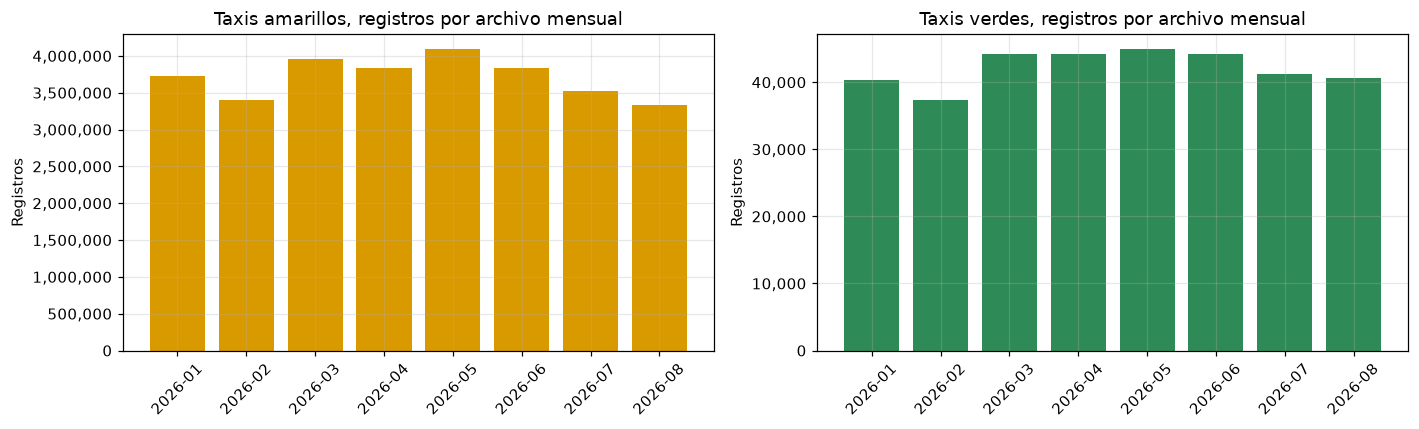

Figura 1. Registros por archivo mensual de 2026 para taxis amarillos y verdes


In [10]:
figura, ejes = plt.subplots(1, 2, figsize=(13, 4))
for eje, tipo in zip(ejes, ("yellow", "green")):
    datos = inventario[inventario["tipo_taxi"] == tipo]
    eje.bar(datos["periodo"], datos["registros"], color=COLORES_TIPO[tipo])
    eje.set_title(f"Taxis {NOMBRES_TIPO[tipo].lower()}, registros por archivo mensual")
    eje.set_ylabel("Registros")
    eje.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
    eje.tick_params(axis="x", rotation=45)
figura.tight_layout()
guardar_figura(figura, "Registros por archivo mensual de 2026 para taxis amarillos y verdes")

Los 16 archivos de 2026 corresponden a los ocho meses publicados, enero a agosto, para cada tipo de taxi. Los conteos leídos con read_parquet coinciden exactamente con los declarados en los metadatos, 30,040,469 registros, lo que confirma que la descarga está completa y que la lectura conjunta no pierde ni duplica filas. El inventario se resolvió en 0.06 s porque solo leyó el pie de cada archivo, frente a 0.15 s del conteo que recorre los datos.

La diferencia de escala entre los dos servicios es la primera característica del conjunto. Los taxis amarillos aportan 29,703,355 registros, el 98.9 % del total, con archivos de 3.3 a 4.1 millones de filas, de 59 a 70 MB y cuatro grupos de filas cada uno. Los verdes aportan 337,114 registros, con archivos de 37 a 45 mil filas, alrededor de 1 MB y un solo grupo de filas. Mayo es el mes con más registros de taxis amarillos, 4,090,836, y agosto el de menos, 3,336,716. Cualquier agregado que no separe por tipo de taxi describe en la práctica a los taxis amarillos.

### 3.2 – Columnas y tipos de datos

DESCRIBE muestra el esquema que DuckDB infiere al leer en conjunto todos los archivos de cada tipo. Como los archivos se publican por separado, la consulta de variaciones revisa el esquema interno de cada archivo para detectar columnas cuyo nombre exacto o tipo cambia entre meses o que no aparecen en todos los archivos.

In [11]:
esquema_amarillos = bitacora.ejecutar("e3_esquema_amarillos", parametros_2026, fuentes_amarillos_2026, filas=40)
esquema_verdes = bitacora.ejecutar("e3_esquema_verdes", parametros_2026, fuentes_verdes_2026, filas=40)
columnas = (esquema_amarillos[["column_name", "column_type"]].assign(clave=lambda d: d["column_name"].str.lower())
            .merge(esquema_verdes[["column_name", "column_type"]].assign(clave=lambda d: d["column_name"].str.lower()),
                   on="clave", how="outer", suffixes=("_amarillos", "_verdes")))
display(columnas.drop(columns="clave"))
variaciones = bitacora.ejecutar("e3_variaciones_esquema", parametros_2026, fuentes_2026, display)

Consulta e3_esquema_amarillos
  Objetivo: Listar las columnas y los tipos de datos que DuckDB infiere al leer en conjunto los archivos de taxis amarillos.
  Fuentes : data/raw/yellow/2026/*.parquet
  Resultado: 21 filas en 0.05 s
Consulta e3_esquema_verdes
  Objetivo: Listar las columnas y los tipos de datos de los archivos de taxis verdes.
  Fuentes : data/raw/green/2026/*.parquet
  Resultado: 22 filas en 0.05 s


,column_name_amarillos,column_type_amarillos,column_name_verdes,column_type_verdes
0,Airport_fee,DOUBLE,NaN,NaN
1,cbd_congestion_fee,DOUBLE,cbd_congestion_fee,DOUBLE
2,congestion_surcharge,DOUBLE,congestion_surcharge,DOUBLE
3,DOLocationID,INTEGER,DOLocationID,INTEGER
4,NaN,NaN,ehail_fee,DOUBLE
5,extra,DOUBLE,extra,DOUBLE
6,fare_amount,DOUBLE,fare_amount,DOUBLE
7,improvement_surcharge,DOUBLE,improvement_surcharge,DOUBLE
8,NaN,NaN,lpep_dropoff_datetime,TIMESTAMP
9,NaN,NaN,lpep_pickup_datetime,TIMESTAMP


Consulta e3_variaciones_esquema
  Objetivo: Detectar columnas cuyo nombre exacto o tipo físico cambia entre archivos, o que no aparecen en todos los archivos de un tipo.
  Fuentes : data/raw/yellow/2026/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 2 filas en 0.12 s


,tipo_taxi,columna,nombres_exactos,tipos,archivos_con_columna,total_archivos
0,yellow,request_source,request_source,VARCHAR,3,8
1,green,request_source,request_source,VARCHAR,3,8


DuckDB infiere 21 columnas para los taxis amarillos y 22 para los verdes. Comparten 18 columnas con el mismo nombre y tipo; las diferencias son las fechas, que usan el prefijo tpep en los amarillos y lpep en los verdes, Airport_fee, que solo existe en los amarillos, y ehail_fee y trip_type, que solo existen en los verdes. Los nombres no siguen una convención única, por ejemplo VendorID, RatecodeID y Airport_fee frente a trip_distance, por lo que la vista normalizada compara los nombres sin distinguir mayúsculas y los traduce a nombres comunes.

La variación más importante dentro de un mismo tipo es request_source, una columna VARCHAR que aparece solo en 3 de los 8 archivos de cada tipo. Sin union_by_name la lectura conjunta fallaría o tomaría el esquema del primer archivo; con esa opción DuckDB rellena con nulos la columna en los archivos que no la tienen. Este comportamiento es el que permite incorporar después años con columnas distintas, como cbd_congestion_fee, sin modificar las consultas.

### 3.3 – Muestra de registros

Se obtiene una muestra aleatoria con muestreo de reservorio y semilla fija, por lo que la muestra es la misma en cada ejecución.

In [12]:
muestra_amarillos = bitacora.ejecutar("e3_muestra_amarillos", parametros_2026, fuentes_amarillos_2026, display)
muestra_verdes = bitacora.ejecutar("e3_muestra_verdes", parametros_2026, fuentes_verdes_2026, display)

Consulta e3_muestra_amarillos
  Objetivo: Obtener una muestra aleatoria reproducible de registros de taxis amarillos.
  Fuentes : data/raw/yellow/2026/*.parquet
  Resultado: 8 filas en 0.30 s


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,request_source
0,2,2026-01-01 00:24:41,2026-01-01 00:36:23,1,4.800,1,N,87,162,2,21.200,1.000,0.500,0.000,0.000,1.000,26.950,2.500,0.000,0.750,None
1,1,2026-01-01 02:08:35,2026-01-01 02:21:22,2,2.300,1,N,90,229,1,14.200,4.250,0.500,1.400,0.000,1.000,21.350,2.500,0.000,0.750,None
2,2,2026-01-01 02:01:56,2026-01-01 02:17:20,1,5.690,1,N,80,95,2,26.100,1.000,0.500,0.000,0.000,1.000,28.600,0.000,0.000,0.000,None
3,2,2026-01-01 04:36:54,2026-01-01 04:48:35,1,2.560,1,N,68,79,1,14.200,1.000,0.500,3.990,0.000,1.000,23.940,2.500,0.000,0.750,None
4,1,2026-01-01 09:37:17,2026-01-01 09:42:10,1,0.800,1,N,239,142,1,6.500,2.500,0.500,2.100,0.000,1.000,12.600,2.500,0.000,0.000,None
5,2,2026-01-01 11:29:34,2026-01-01 11:36:19,1,0.740,1,N,161,163,1,7.900,0.000,0.500,3.160,0.000,1.000,15.810,2.500,0.000,0.750,None
6,2,2026-01-01 11:42:55,2026-01-01 11:49:37,1,1.030,1,N,163,186,2,7.900,0.000,0.500,0.000,0.000,1.000,12.650,2.500,0.000,0.750,None
7,2,2026-01-01 13:36:51,2026-01-01 13:45:33,1,0.800,1,N,186,48,2,8.600,0.000,0.500,0.000,0.000,1.000,13.350,2.500,0.000,0.750,None


Consulta e3_muestra_verdes
  Objetivo: Obtener una muestra aleatoria reproducible de registros de taxis verdes.
  Fuentes : data/raw/green/2026/*.parquet
  Resultado: 8 filas en 0.14 s


,VendorID,lpep_pickup_datetime,lpep_dropoff_datetime,store_and_fwd_flag,RatecodeID,PULocationID,DOLocationID,passenger_count,trip_distance,fare_amount,extra,mta_tax,tip_amount,tolls_amount,ehail_fee,improvement_surcharge,total_amount,payment_type,trip_type,congestion_surcharge,cbd_congestion_fee,request_source
0,2,2026-01-03 17:06:05,2026-01-03 17:11:27,N,1,74,41,1,1.150,7.200,0.000,0.500,4.000,0.000,NaN,1.000,12.700,1,1,0.000,0.000,None
1,2,2026-01-11 22:28:43,2026-01-11 22:32:53,N,1,74,42,2,0.000,5.800,1.000,0.500,1.660,0.000,NaN,1.000,9.960,1,1,0.000,0.000,None
2,2,2026-01-13 18:36:59,2026-01-13 18:41:12,N,1,43,238,1,1.080,7.200,2.500,0.500,3.490,0.000,NaN,1.000,17.440,1,1,2.750,0.000,None
3,2,2026-01-16 15:15:45,2026-01-16 15:43:34,N,1,244,233,1,9.390,38.000,0.000,0.500,0.000,0.000,NaN,1.000,43.000,2,1,2.750,0.750,None
4,2,2026-01-20 15:12:55,2026-01-20 15:24:05,N,1,82,82,1,1.400,11.400,0.000,0.500,0.000,0.000,NaN,1.000,12.900,2,1,0.000,0.000,None
5,2,2026-01-23 10:19:05,2026-01-23 10:37:24,N,1,74,238,1,3.020,18.400,0.000,0.500,4.530,0.000,NaN,1.000,27.180,1,1,2.750,0.000,None
6,2,2026-01-24 15:40:48,2026-01-24 15:52:07,N,1,65,40,1,1.050,10.700,0.000,0.500,1.590,0.000,NaN,1.000,13.790,1,1,0.000,0.000,None
7,2,2026-01-30 00:16:28,2026-01-30 00:23:47,N,1,75,238,1,1.360,9.300,1.000,0.500,1.770,0.000,NaN,1.000,13.570,1,1,0.000,0.000,None


### 3.4 – Resumen estadístico y problemas de calidad

SUMMARIZE calcula en una sola lectura el mínimo, máximo, promedio, cuartiles, valores distintos aproximados y porcentaje de nulos de cada columna. A partir de esos extremos se cuantifican por tipo de taxi los problemas de calidad, se revisa el rango de fechas de cada archivo y se revisan los códigos de pago.

In [13]:
resumen_estadistico = bitacora.ejecutar("e3_resumen_estadistico", parametros_2026, fuentes_amarillos_2026,
                                        display, filas=30)

Consulta e3_resumen_estadistico
  Objetivo: Obtener mínimos, máximos, promedios, cuartiles y porcentaje de nulos de cada columna de taxis amarillos con SUMMARIZE.
  Fuentes : data/raw/yellow/2026/*.parquet
  Resultado: 21 filas en 28.90 s


,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,VendorID,INTEGER,1,7,4,1.885739809526567,0.7155277514022292,2,2,2,29703355,0.000
1,tpep_pickup_datetime,TIMESTAMP,2001-01-01 09:23:58,2026-08-31 23:59:59,16867928,2026-04-30 15:29:29.519432,NaN,2026-03-03 03:21:46.663982,2026-05-01 07:46:38.347986,2026-06-26 01:43:36.126409,29703355,0.000
2,tpep_dropoff_datetime,TIMESTAMP,2001-01-01 16:09:38,2026-09-01 20:16:00,16587125,2026-04-30 15:47:08.186216,NaN,2026-03-04 17:01:35.685536,2026-04-30 17:23:56.815865,2026-06-26 05:28:49.476139,29703355,0.000
3,passenger_count,BIGINT,0,9,11,1.2494318488564,0.6529195072996784,1,1,1,29703355,25.980
4,trip_distance,DOUBLE,0.0,328522.2,7217,5.55294014969123,550.6497893231015,1.022197829437098,1.8566666190531322,3.812071419057042,29703355,0.000
5,RatecodeID,BIGINT,1,99,7,4.527471444398553,18.000926540066864,1,1,1,29703355,25.980
6,store_and_fwd_flag,VARCHAR,N,Y,2,NaN,NaN,NaN,NaN,NaN,29703355,25.980
7,PULocationID,INTEGER,1,265,290,161.57793013617484,66.74656703251749,117,161,233,29703355,0.000
8,DOLocationID,INTEGER,1,265,298,161.05139342003622,70.72548569211374,108,162,234,29703355,0.000
9,payment_type,BIGINT,0,5,6,0.8621735154160195,0.6463324345961866,0,1,1,29703355,0.000


Consulta e3_calidad
  Objetivo: Cuantificar por tipo de taxi los principales problemas de calidad observables directamente en los archivos.
  Fuentes : data/raw/yellow/2026/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 2 filas en 3.31 s


,tipo_taxi,registros,fecha_fuera_del_mes,destino_no_posterior,duracion_mayor_6h,distancia_cero,distancia_mayor_200,montos_negativos,pasajeros_nulos,pasajeros_cero,tarifa_desconocida,pago_sin_dato,zona_desconocida
0,yellow,29703355,146,371683,7313,952231,704,161970,7716688,91359,8486381,7716690,49676
1,green,337114,98,234,1102,12212,69,1025,48775,4527,48777,48775,1131


tipo_taxi,green,yellow
problema,,
Código de tarifa desconocido,14.469,28.570
Pago sin registro,14.468,25.979
Pasajeros nulos,14.468,25.979
Distancia cero,3.623,3.206
Destino no posterior a la recogida,0.069,1.251
Tarifa o total negativos,0.304,0.545
Pasajeros cero,1.343,0.308
Zona desconocida,0.335,0.167
Duración mayor a 6 horas,0.327,0.025


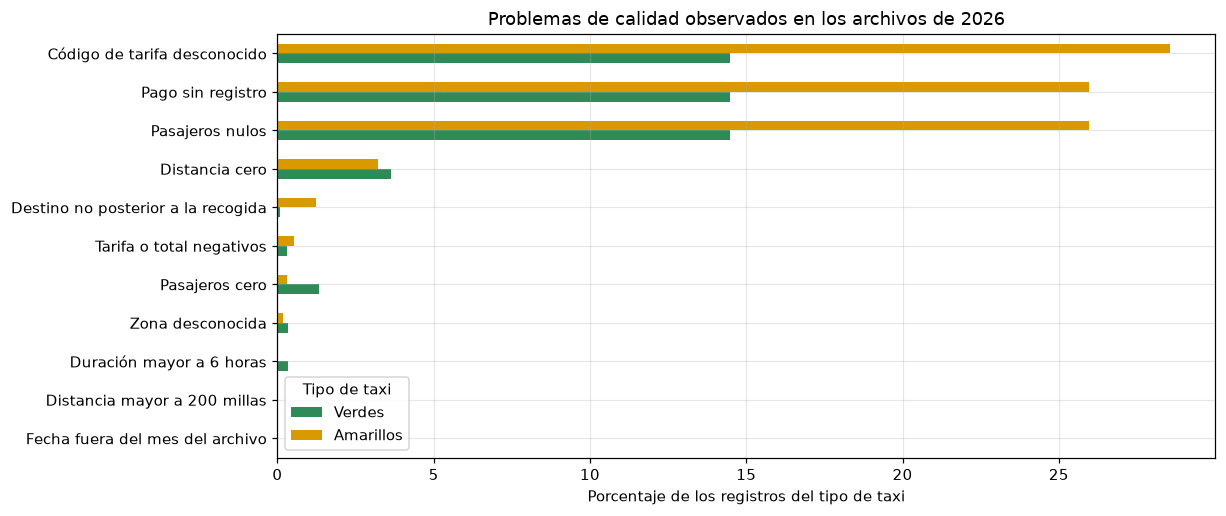

Figura 2. Porcentaje de registros de 2026 con cada problema de calidad por tipo de taxi


In [14]:
calidad_2026 = bitacora.ejecutar("e3_calidad", parametros_2026, fuentes_2026, display)
problemas = calidad_2026.melt(id_vars=["tipo_taxi", "registros"], var_name="problema", value_name="casos")
problemas["porcentaje"] = 100 * problemas["casos"] / problemas["registros"]
ETIQUETAS_PROBLEMAS = {"fecha_fuera_del_mes": "Fecha fuera del mes del archivo", "destino_no_posterior": "Destino no posterior a la recogida",
                       "duracion_mayor_6h": "Duración mayor a 6 horas", "distancia_cero": "Distancia cero",
                       "distancia_mayor_200": "Distancia mayor a 200 millas", "montos_negativos": "Tarifa o total negativos",
                       "pasajeros_nulos": "Pasajeros nulos", "pasajeros_cero": "Pasajeros cero",
                       "tarifa_desconocida": "Código de tarifa desconocido", "pago_sin_dato": "Pago sin registro",
                       "zona_desconocida": "Zona desconocida"}
problemas["problema"] = problemas["problema"].map(ETIQUETAS_PROBLEMAS)
tabla_problemas = problemas.pivot(index="problema", columns="tipo_taxi", values="porcentaje")
display(tabla_problemas.sort_values("yellow", ascending=False))

figura, eje = plt.subplots(figsize=(11, 5))
tabla_problemas.sort_values("yellow")[["green", "yellow"]].rename(columns=NOMBRES_TIPO).plot(
    kind="barh", ax=eje, color=[VERDE, AMARILLO])
eje.set_xlabel("Porcentaje de los registros del tipo de taxi")
eje.set_ylabel("")
eje.set_title("Problemas de calidad observados en los archivos de 2026")
guardar_figura(figura, "Porcentaje de registros de 2026 con cada problema de calidad por tipo de taxi")

In [15]:
rango_fechas = bitacora.ejecutar("e3_rango_fechas", parametros_2026, fuentes_2026, display, filas=30)
codigos_pago = bitacora.ejecutar("e3_codigos_pago", parametros_2026, fuentes_2026, display, filas=20)

Consulta e3_rango_fechas
  Objetivo: Revisar las fechas mínima y máxima de recogida de cada archivo para detectar registros que no pertenecen al mes publicado.
  Fuentes : data/raw/yellow/2026/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 16 filas en 1.63 s


,archivo,primera_recogida,ultima_recogida,fuera_del_mes
0,green_tripdata_2026-01.parquet,2025-12-27 16:49:41,2026-02-01 21:08:36,22
1,green_tripdata_2026-02.parquet,2026-01-26 23:38:06,2026-03-01 09:48:53,11
2,green_tripdata_2026-03.parquet,2009-01-01 01:35:31,2026-03-31 23:57:29,9
3,green_tripdata_2026-04.parquet,2026-03-31 23:28:50,2026-05-01 07:53:18,3
4,green_tripdata_2026-05.parquet,2008-12-31 23:05:50,2026-05-31 23:59:13,10
5,green_tripdata_2026-06.parquet,2026-05-26 19:47:06,2026-07-01 03:21:24,13
6,green_tripdata_2026-07.parquet,2008-12-31 17:35:31,2026-08-01 14:36:42,16
7,green_tripdata_2026-08.parquet,2008-12-31 23:06:23,2026-08-31 23:58:28,14
8,yellow_tripdata_2026-01.parquet,2025-12-31 23:57:29,2026-02-01 00:45:01,7
9,yellow_tripdata_2026-02.parquet,2026-01-31 23:31:23,2026-03-01 00:51:48,16


Consulta e3_codigos_pago
  Objetivo: Revisar los códigos de tipo de pago presentes en los archivos y su frecuencia.
  Fuentes : data/raw/yellow/2026/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 11 filas en 0.42 s


,tipo_taxi,codigo_pago,registros,porcentaje
0,yellow,0,7716688,25.980
1,yellow,1,18941008,63.770
2,yellow,2,2708031,9.120
3,yellow,3,98138,0.330
4,yellow,4,239488,0.810
5,yellow,5,2,0.000
6,green,1,219980,65.250
7,green,2,65921,19.550
8,green,3,1688,0.500
9,green,4,750,0.220


SUMMARIZE recorrió los 29.7 millones de registros de taxis amarillos en 28.9 s y dejó visibles tres grupos de problemas.

- Faltantes estructurales. passenger_count, RatecodeID, store_and_fwd_flag, congestion_surcharge y Airport_fee tienen exactamente el mismo porcentaje de nulos, 25.98 %, y el código de pago 0 aparece en 7,716,688 registros, el mismo número. Se trata del mismo grupo de viajes, que llega sin esos campos y sin método de pago; no son errores aislados sino registros que la fuente publica incompletos. En los taxis verdes ocurre lo mismo con 48,775 registros, 14.47 %, que tienen nulos el pago y los pasajeros. request_source es nula en el 90.23 % de los registros porque solo existe en tres archivos.
- Valores imposibles. La distancia máxima es 328,522.2 millas, la tarifa va de -2,555.2 a 7,045 dólares, hay propinas negativas de hasta -222 dólares y recogidas desde 2001. En la revisión por archivo aparecen fechas de 2001, 2008 y 2009 dentro de archivos de 2026, aunque los registros fuera del mes del archivo son pocos, 146 amarillos y 98 verdes.
- Problemas frecuentes. La Figura 2 muestra que el código de tarifa desconocido afecta al 28.57 % de los amarillos y al 14.47 % de los verdes, la distancia cero al 3.21 % y 3.62 %, el destino no posterior a la recogida al 1.25 % de los amarillos y los montos negativos al 0.55 % y 0.30 %.

La conclusión práctica es que no todos estos problemas invalidan un viaje. Un viaje sin método de pago o sin número de pasajeros sigue siendo un viaje real, mientras que una duración negativa o una distancia de miles de millas no lo es. Esa distinción define las reglas de 3.5.

### 3.5 – Reglas de calidad adoptadas

A partir de los problemas observados se definen reglas que no eliminan registros de los archivos, sino que asignan a cada viaje un motivo de exclusión en la vista viajes_calidad. El análisis posterior usa la vista viajes_validos, que contiene solo los viajes sin motivo de exclusión. Las reglas se evalúan en orden y cada viaje recibe el primer motivo que incumple.

| Regla | Criterio de exclusión | Justificación |
| --- | --- | --- |
| Fecha fuera del mes del archivo | La fecha de recogida no pertenece al año y mes del nombre del archivo | Registros con relojes desconfigurados o tardíos que distorsionan las series mensuales |
| Duración nula o negativa | El destino no es posterior a la recogida | Un viaje real tiene duración positiva |
| Duración mayor a 6 horas | Más de 360 minutos | Taxímetros que no se cerraron, ajenos al viaje real |
| Distancia cero | Distancia menor o igual a cero | Viajes cancelados o sin registro del taxímetro |
| Distancia mayor a 200 millas | Más de 200 millas | Imposible dentro de una jornada urbana, error del registro |
| Velocidad mayor a 80 mph | Distancia entre duración superior a 80 millas por hora | Combinaciones incoherentes de distancia y tiempo |
| Monto negativo o ajuste | Tarifa o total negativos o nulos | Reembolsos y anulaciones contables, no viajes |
| Total mayor a 1000 dólares | Total superior a 1000 | Montos implausibles para un viaje de taxi |

Otros problemas se conservan porque no invalidan el viaje: pasajeros nulos o cero, tarifa desconocida, pago sin registro y zona desconocida. Estos casos se etiquetan, por ejemplo como pago Sin registro o zona Desconocida, y se reportan en el análisis.

### 3.6 – Documentación de las consultas

La bitácora registra cada consulta ejecutada con su SQL final, objetivo, archivos fuente, tamaño del resultado, tiempo, una muestra del resultado y la decisión tomada. La documentación se exporta a docs/consultas.md y se actualiza al final de cada ejercicio. El texto fuente de las consultas permanece en la carpeta sql, encabezado por los mismos metadatos.

In [16]:
bitacora.exportar(ARCHIVO_CONSULTAS)
display(bitacora.tabla())
print(f"Documentacion exportada en {ARCHIVO_CONSULTAS.relative_to(RAIZ)}")

,id,ejercicio,archivo_sql,filas,segundos
0,e3_inventario_archivos,3,01_exploracion_parquet.sql,16,0.059
1,e3_resumen_archivos,3,01_exploracion_parquet.sql,2,0.058
2,e3_conteo_lectura,3,01_exploracion_parquet.sql,2,0.150
3,e3_esquema_amarillos,3,01_exploracion_parquet.sql,21,0.054
4,e3_esquema_verdes,3,01_exploracion_parquet.sql,22,0.050
5,e3_variaciones_esquema,3,01_exploracion_parquet.sql,2,0.124
6,e3_muestra_amarillos,3,01_exploracion_parquet.sql,8,0.301
7,e3_muestra_verdes,3,01_exploracion_parquet.sql,8,0.145
8,e3_resumen_estadistico,3,01_exploracion_parquet.sql,21,28.900
9,e3_calidad,3,01_exploracion_parquet.sql,2,3.308


Documentacion exportada en docs/consultas.md


### 3.7 – Consultar directamente un archivo Parquet

Consultar directamente un archivo Parquet significa que DuckDB ejecuta el SQL sobre el archivo en disco como si fuera una tabla, sin un paso previo de importación ni una copia de los datos en una base. Parquet es un formato columnar: guarda cada columna por separado, comprimida y dividida en grupos de filas, y al final del archivo incluye un pie con el esquema, el número de registros y estadísticas como mínimo y máximo de cada columna en cada grupo de filas.

DuckDB aprovecha esa estructura de tres maneras. Lee solo las columnas que la consulta necesita, por lo que un conteo por mes no toca las columnas de montos. Usa las estadísticas del pie para saltar grupos de filas que no pueden cumplir un filtro. Y responde algunas preguntas solo con metadatos, como el número de registros del inventario de 3.1. Además, lee varios archivos en paralelo con un mismo patrón glob y une esquemas distintos con union_by_name.

Cuando el volumen de datos es grande esta estrategia evita duplicar el almacenamiento, elimina el tiempo de carga y permite que los archivos nuevos queden disponibles en cuanto se descargan. El análisis puede empezar inmediatamente y la memoria necesaria depende del resultado de la consulta y no del tamaño del archivo, lo que permite trabajar con decenas de millones de registros en un equipo personal.

## Ejercicio 4 – Análisis exploratorio de los viajes de 2026

Se responden preguntas analíticas propias sobre los viajes de 2026, justificadas por las características observadas en el Ejercicio 3. Primero se construye la vista normalizada que une taxis amarillos y verdes con nombres de columna comunes, y sobre ella las capas de calidad y de viajes válidos. Las consultas están en sql/02_analisis_exploratorio.sql y se ejecutan sobre los Parquet a través de esas vistas. Las distribuciones se resumen con medianas y percentiles porque las distancias y los montos son asimétricos.

### 4.1 – Preguntas de análisis

1. Qué proporción de registros incumple alguna regla de calidad y por qué motivo. Justificación: el Ejercicio 3 mostró registros imposibles y es necesario saber cuánto pesan antes de interpretar cualquier promedio.
2. Cómo evoluciona mes a mes el número de viajes y el ingreso de cada tipo de taxi. Justificación: los datos se publican por mes y el comportamiento temporal es la primera dimensión del conjunto.
3. En qué horas y tipo de día se concentra la demanda y cómo cambia la velocidad. Justificación: las fechas de recogida y destino permiten estudiar patrones diarios y la congestión.
4. En qué se diferencian los viajes de taxis amarillos y verdes en distancia, duración, pasajeros y monto. Justificación: son servicios con reglas y zonas de operación distintas que comparten esquema.
5. Cómo se distribuyen las distancias de los viajes. Justificación: el resumen estadístico mostró una cola larga que el promedio no describe.
6. Cómo se reparten los métodos de pago y qué propina se registra en cada uno. Justificación: los códigos de pago incluyen valores sin registro y la propina solo se captura con tarjeta.
7. Desde qué zonas y distritos sale la mayor parte de los viajes. Justificación: los identificadores de zona permiten describir la geografía de cada servicio.
8. Cuánto pesan los viajes de aeropuerto y en qué se diferencian. Justificación: tienen tarifas y recargos propios que influyen en los promedios.
9. Qué viajes válidos tienen una tarifa por milla atípica. Justificación: un viaje puede cumplir las reglas de calidad y aun así tener una relación entre monto y distancia anómala.

### 4.2 – Vista normalizada y capas de calidad

La vista viajes se genera leyendo el esquema de cada tipo de taxi: renombra las columnas a nombres comunes en español, convierte los tipos que varían entre archivos a un tipo común, rellena con nulos las columnas que no existen en un tipo o periodo y agrega el año y mes del archivo junto con la duración. El SQL generado se guarda en sql/vista_viajes_generada.sql. Sobre esa vista se crean la tabla de zonas, la vista viajes_calidad con las reglas de 3.5 y la vista viajes_validos.

In [17]:
sql_vista = taxis.crear_vista_viajes(con, anios=ANIOS_INICIALES, guardar=ARCHIVO_VISTA)
print(ARCHIVO_VISTA.read_text(encoding="utf-8"))

-- Vista normalizada generada por scripts/taxis.py a partir de los esquemas de los archivos.
-- Las rutas son relativas a la raiz del repositorio. No se edita a mano.

CREATE OR REPLACE VIEW viajes AS
SELECT *,
    date_diff('second', fecha_recogida, fecha_destino) / 60.0 AS duracion_min
FROM (
SELECT
    'yellow' AS tipo_taxi,
    CAST("VendorID" AS INTEGER) AS proveedor,
    CAST("tpep_pickup_datetime" AS TIMESTAMP) AS fecha_recogida,
    CAST("tpep_dropoff_datetime" AS TIMESTAMP) AS fecha_destino,
    CAST("passenger_count" AS DOUBLE) AS pasajeros,
    CAST("trip_distance" AS DOUBLE) AS distancia_millas,
    CAST("RatecodeID" AS INTEGER) AS codigo_tarifa,
    CAST("store_and_fwd_flag" AS VARCHAR) AS almacenado_y_enviado,
    CAST("PULocationID" AS INTEGER) AS zona_origen,
    CAST("DOLocationID" AS INTEGER) AS zona_destino,
    CAST("payment_type" AS INTEGER) AS tipo_pago,
    CAST("fare_amount" AS DOUBLE) AS tarifa,
    CAST("extra" AS DOUBLE) AS extra,
    CAST("mta_tax" AS DOUBLE

In [18]:
parametros_zonas = {"ruta_zonas": taxis.ARCHIVO_ZONAS.as_posix()}
bitacora.ejecutar("crear_tabla_zonas", parametros_zonas, "data/raw/zonas/taxi_zone_lookup.csv")
bitacora.ejecutar("crear_vista_calidad", fuentes="vista viajes sobre " + fuentes_2026)
bitacora.ejecutar("crear_vista_validos", fuentes="vista viajes_calidad y tabla zonas")
print(SEPARADOR)
print(f"Zonas cargadas: {con.execute('SELECT count(*) FROM zonas').fetchone()[0]}")
display(con.execute("DESCRIBE viajes_validos").df()[["column_name", "column_type"]].T)

Consulta crear_tabla_zonas
  Objetivo: Cargar la tabla de zonas de taxi de la TLC para traducir los identificadores de zona a distrito y nombre.
  Fuentes : data/raw/zonas/taxi_zone_lookup.csv
  Resultado: 0 filas en 0.02 s


Consulta crear_vista_calidad
  Objetivo: Agregar a cada viaje etiquetas legibles, variables de calendario, velocidad y las reglas de calidad definidas en el Ejercicio 3.
  Fuentes : vista viajes sobre data/raw/yellow/2026/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 0 filas en 0.05 s
Consulta crear_vista_validos
  Objetivo: Definir la vista de viajes válidos con distrito y nombre de las zonas de origen y destino.
  Fuentes : vista viajes_calidad y tabla zonas
  Resultado: 0 filas en 0.05 s
------------------------------------------------------------
Zonas cargadas: 265


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,...,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40
column_name,tipo_taxi,proveedor,fecha_recogida,fecha_destino,pasajeros,distancia_millas,codigo_tarifa,almacenado_y_enviado,zona_origen,zona_destino,tipo_pago,tarifa,extra,impuesto_mta,propina,peajes,recargo_mejora,recargo_congestion,cargo_aeropuerto,cargo_cbd,...,total,tipo_viaje,anio_archivo,mes_archivo,archivo,duracion_min,fecha,hora,dia_semana,velocidad_mph,tipo_dia,franja_horaria,metodo_pago,tarifa_aplicada,distrito_origen,nombre_origen,distrito_destino,nombre_destino,aeropuerto,propina_pct
column_type,VARCHAR,INTEGER,TIMESTAMP,TIMESTAMP,DOUBLE,DOUBLE,INTEGER,VARCHAR,INTEGER,INTEGER,INTEGER,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,...,DOUBLE,INTEGER,INTEGER,INTEGER,VARCHAR,DOUBLE,DATE,BIGINT,BIGINT,DOUBLE,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,DOUBLE


Pregunta 1. Proporción de registros excluidos por cada regla de calidad.

In [19]:
exclusiones = bitacora.ejecutar("e4_calidad_exclusiones", fuentes="vista viajes_calidad, " + fuentes_2026, mostrar=display, filas=30)
validos = exclusiones[exclusiones["clasificacion"] == "Válido"].set_index("tipo_taxi")["porcentaje"]
print(SEPARADOR)
for tipo, porcentaje in validos.items():
    print(f"Viajes validos de taxis {NOMBRES_TIPO[tipo].lower():<10}: {porcentaje:.2f} %")

Consulta e4_calidad_exclusiones
  Objetivo: Pregunta 1. Qué proporción de registros incumple alguna regla de calidad y por qué motivo, en cada tipo de taxi.
  Fuentes : vista viajes_calidad, data/raw/yellow/2026/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 17 filas en 3.80 s


,tipo_taxi,clasificacion,registros,porcentaje
0,yellow,Válido,28229225,95.037
1,yellow,Distancia cero,940717,3.167
2,yellow,Duración nula o negativa,371682,1.251
3,yellow,Monto negativo o ajuste,146227,0.492
4,yellow,Velocidad mayor a 80 mph,7342,0.025
5,yellow,Duración mayor a 6 horas,7309,0.025
6,yellow,Distancia mayor a 200 millas,698,0.002
7,yellow,Fecha fuera del mes del archivo,146,0.000
8,yellow,Total mayor a 1000 dólares,9,0.000
9,green,Válido,322011,95.520


------------------------------------------------------------
Viajes validos de taxis amarillos : 95.04 %
Viajes validos de taxis verdes    : 95.52 %


Las reglas de calidad conservan el 95.04 % de los registros de taxis amarillos y el 95.52 % de los verdes, por lo que el análisis posterior trabaja con 28,229,225 y 322,011 viajes válidos. La exclusión más frecuente en ambos tipos es la distancia cero, 3.17 % y 3.55 %, que corresponde a viajes cancelados o sin registro del taxímetro. Le siguen, en los amarillos, la duración nula o negativa, 1.25 %, y los montos negativos o ajustes, 0.49 %; en los verdes, la duración mayor a 6 horas y la velocidad mayor a 80 mph, ambas cerca de 0.32 %. Las reglas extremas, distancia mayor a 200 millas, total mayor a 1000 dólares y fecha fuera del mes, afectan a menos de 0.03 % de los registros, pero son las que distorsionaban los máximos y promedios del resumen estadístico.

Como las reglas se evalúan en orden, cada registro aparece una sola vez y los porcentajes suman 100 %. El 25.98 % de amarillos sin método de pago no se excluye, se conserva con la etiqueta Sin registro.

### 4.3 – Comportamiento temporal de los viajes

Pregunta 2 y pregunta 3. Se calcula la serie mensual por tipo de taxi y el perfil por hora, separando días entre semana y fines de semana. El volumen se expresa en viajes promedio por día para que meses y tipos de día con distinto número de días sean comparables.

Consulta e4_viajes_mensuales
  Objetivo: Pregunta 2. Cómo evoluciona el número de viajes y el ingreso de cada mes por tipo de taxi.
  Fuentes : vista viajes_validos
  Resultado: 16 filas en 4.73 s


,tipo_taxi,anio,mes,viajes,viajes_por_dia,ingreso_millones,total_promedio
0,yellow,2026,1,3516139,"113,424.000",104.319,29.670
1,yellow,2026,2,3210025,"114,644.000",97.747,30.450
2,yellow,2026,3,3762447,"121,369.000",113.861,30.260
3,yellow,2026,4,3673823,"122,461.000",110.568,30.100
4,yellow,2026,5,3911803,"126,187.000",119.493,30.550
5,yellow,2026,6,3646098,"121,537.000",111.581,30.600
6,yellow,2026,7,3345768,"107,928.000",100.849,30.140
7,yellow,2026,8,3163122,"102,036.000",95.400,30.160
8,green,2026,1,38633,"1,246.000",0.935,24.210
9,green,2026,2,35650,"1,273.000",0.867,24.320


Consulta e4_patron_horario
  Objetivo: Pregunta 3. En qué horas y tipo de día se concentra la demanda y cómo cambia la velocidad del tráfico.
  Fuentes : vista viajes_validos
  Resultado: 48 filas en 6.30 s


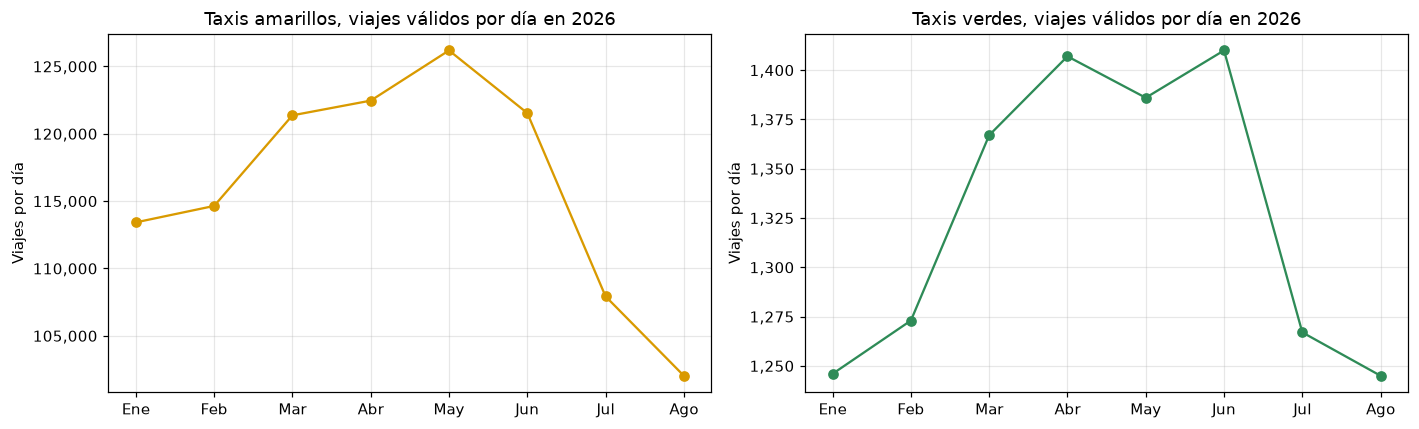

Figura 3. Viajes válidos promedio por día en cada mes de 2026 por tipo de taxi


In [20]:
mensual = bitacora.ejecutar("e4_viajes_mensuales", mostrar=display, filas=30)
horario = bitacora.ejecutar("e4_patron_horario", mostrar=None, filas=48)

figura, ejes = plt.subplots(1, 2, figsize=(13, 4))
for eje, tipo in zip(ejes, ("yellow", "green")):
    datos = mensual[mensual["tipo_taxi"] == tipo]
    eje.plot([MESES[m - 1] for m in datos["mes"]], datos["viajes_por_dia"], marker="o", color=COLORES_TIPO[tipo])
    eje.set_title(f"Taxis {NOMBRES_TIPO[tipo].lower()}, viajes válidos por día en 2026")
    eje.set_ylabel("Viajes por día")
    eje.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
figura.tight_layout()
guardar_figura(figura, "Viajes válidos promedio por día en cada mes de 2026 por tipo de taxi")

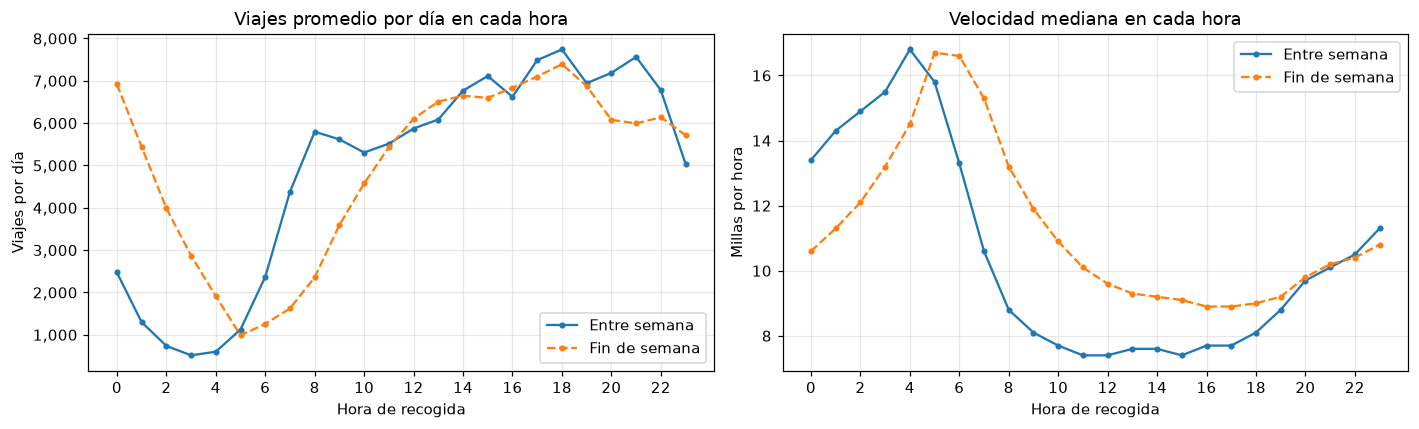

Figura 4. Perfil horario de la demanda y de la velocidad mediana en 2026, entre semana y fin de semana


,tipo_dia,hora,viajes_por_dia
18,Entre semana,18,"7,740.200"
42,Fin de semana,18,"7,392.700"


,tipo_dia,hora,velocidad_mediana_mph
11,Entre semana,11,7.400
40,Fin de semana,16,8.900


,tipo_taxi,mes,viajes_por_dia
13,green,6,"1,410.000"
4,yellow,5,"126,187.000"


In [21]:
figura, ejes = plt.subplots(1, 2, figsize=(13, 4))
for tipo_dia, estilo in (("Entre semana", "-"), ("Fin de semana", "--")):
    datos = horario[horario["tipo_dia"] == tipo_dia]
    ejes[0].plot(datos["hora"], datos["viajes_por_dia"], estilo, marker="o", ms=3, label=tipo_dia)
    ejes[1].plot(datos["hora"], datos["velocidad_mediana_mph"], estilo, marker="o", ms=3, label=tipo_dia)
ejes[0].set_title("Viajes promedio por día en cada hora")
ejes[0].set_ylabel("Viajes por día")
ejes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ejes[1].set_title("Velocidad mediana en cada hora")
ejes[1].set_ylabel("Millas por hora")
for eje in ejes:
    eje.set_xlabel("Hora de recogida")
    eje.set_xticks(range(0, 24, 2))
    eje.legend()
figura.tight_layout()
guardar_figura(figura, "Perfil horario de la demanda y de la velocidad mediana en 2026, entre semana y fin de semana")

pico = horario.loc[horario.groupby("tipo_dia")["viajes_por_dia"].idxmax(), ["tipo_dia", "hora", "viajes_por_dia"]]
lenta = horario.loc[horario.groupby("tipo_dia")["velocidad_mediana_mph"].idxmin(), ["tipo_dia", "hora", "velocidad_mediana_mph"]]
mes_maximo = mensual.loc[mensual.groupby("tipo_taxi")["viajes_por_dia"].idxmax(), ["tipo_taxi", "mes", "viajes_por_dia"]]
display(pico)
display(lenta)
display(mes_maximo)

La Figura 3 muestra una estacionalidad clara en los taxis amarillos. Los viajes válidos por día suben de 113,424 en enero a un máximo de 126,187 en mayo y caen en verano hasta 107,928 en julio y 102,036 en agosto, 19 % menos que en mayo. El ingreso mensual sigue la misma forma, con un máximo de 119.5 millones de dólares en mayo, mientras que el monto promedio por viaje se mantiene casi constante entre 29.67 y 30.60 dólares. Los taxis verdes se mueven en un rango estrecho, de 1,245 a 1,410 viajes por día con máximo en junio, pero su monto promedio crece todos los meses, de 24.21 dólares en enero a 26.36 en agosto.

El perfil horario de la Figura 4 diferencia con claridad los dos tipos de día. Entre semana hay un mínimo cerca de las 3 y 4 de la mañana, con unos 500 viajes por día, un primer pico a las 8, cercano a 5,800, y el máximo a las 18 horas con 7,740 viajes por día. En fin de semana no existe el pico de la mañana y la actividad nocturna es alta: a medianoche hay cerca de 6,900 viajes por día, el mínimo se desplaza a las 5 y el máximo también ocurre a las 18 horas, con 7,393.

La velocidad mediana es el reflejo inverso de la demanda. Entre semana alcanza cerca de 16.8 mph a las 4 de la mañana, cae bruscamente a partir de las 6 y se mantiene entre 7.4 y 7.7 mph desde las 11 hasta las 17 horas, con el mínimo de 7.4 mph a las 11. En fin de semana el tráfico es más fluido durante el día y el mínimo es de 8.9 mph a las 16 horas. La congestión del día laboral se extiende por casi toda la jornada y no solo por las horas pico de demanda.

### 4.4 – Características de los viajes y diferencias entre taxis amarillos y verdes

Pregunta 4, pregunta 5, pregunta 7 y pregunta 8. Se comparan las distribuciones de distancia, duración y monto, la distribución de distancias por intervalos de una milla, las zonas de origen principales y el peso de los viajes de aeropuerto.

Consulta e4_caracteristicas_tipo
  Objetivo: Pregunta 4. En qué se diferencian los viajes de taxis amarillos y verdes en distancia, duración, pasajeros y monto.
  Fuentes : vista viajes_validos
  Resultado: 2 filas en 14.30 s


,tipo_taxi,viajes,pasajeros_promedio,distancia_p25,distancia_mediana,distancia_p75,distancia_p99,duracion_mediana,duracion_p99,total_mediano,total_p99,pct_aeropuerto
0,yellow,28229225,1.250,1.100,1.930,3.950,19.520,14.100,71.300,23.580,104.990,8.160
1,green,322011,1.300,1.330,2.150,3.770,17.730,13.400,75.100,20.520,94.750,3.350


Consulta e4_distribucion_distancia
  Objetivo: Pregunta 5. Cómo se distribuyen las distancias de los viajes en intervalos de una milla por tipo de taxi.
  Fuentes : vista viajes_validos
  Resultado: 62 filas en 4.71 s


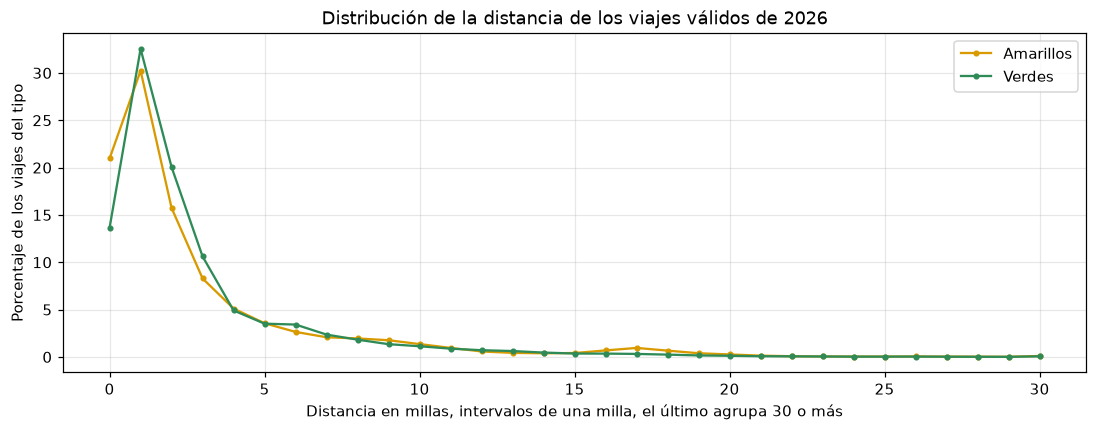

Figura 5. Distribución de la distancia de los viajes válidos de 2026 por tipo de taxi


In [22]:
caracteristicas = bitacora.ejecutar("e4_caracteristicas_tipo", mostrar=display)
distancias = bitacora.ejecutar("e4_distribucion_distancia", mostrar=None, filas=62)

figura, eje = plt.subplots(figsize=(12, 4))
for tipo in ("yellow", "green"):
    datos = distancias[distancias["tipo_taxi"] == tipo]
    eje.plot(datos["millas"], datos["porcentaje"], marker="o", ms=3, color=COLORES_TIPO[tipo], label=NOMBRES_TIPO[tipo])
eje.set_xlabel("Distancia en millas, intervalos de una milla, el último agrupa 30 o más")
eje.set_ylabel("Porcentaje de los viajes del tipo")
eje.set_title("Distribución de la distancia de los viajes válidos de 2026")
eje.legend()
guardar_figura(figura, "Distribución de la distancia de los viajes válidos de 2026 por tipo de taxi")

In [23]:
zonas_origen = bitacora.ejecutar("e4_zonas_origen", mostrar=display, filas=20)
aeropuertos = bitacora.ejecutar("e4_aeropuertos", mostrar=display)

Consulta e4_zonas_origen
  Objetivo: Pregunta 7. Desde qué zonas y distritos sale la mayor parte de los viajes de cada tipo de taxi.
  Fuentes : vista viajes_validos y tabla zonas
  Resultado: 20 filas en 6.31 s


,tipo_taxi,zona,distrito,viajes,porcentaje,posicion
0,yellow,Upper East Side South,Manhattan,1252825,4.440,1
1,yellow,Midtown Center,Manhattan,1171647,4.150,2
2,yellow,JFK Airport,Queens,1125139,3.990,3
3,yellow,Upper East Side North,Manhattan,1113246,3.940,4
4,yellow,Penn Station/Madison Sq West,Manhattan,868652,3.080,5
5,yellow,Midtown East,Manhattan,864634,3.060,6
6,yellow,Times Sq/Theatre District,Manhattan,817475,2.900,7
7,yellow,Lincoln Square East,Manhattan,811726,2.880,8
8,yellow,East Village,Manhattan,756371,2.680,9
9,yellow,Murray Hill,Manhattan,737674,2.610,10


Consulta e4_aeropuertos
  Objetivo: Pregunta 8. Cuánto pesan los viajes de aeropuerto y en qué se diferencian del resto.
  Fuentes : vista viajes_validos
  Resultado: 8 filas en 8.09 s


,tipo_taxi,aeropuerto,viajes,porcentaje,distancia_mediana,duracion_mediana,total_mediano
0,yellow,Sin aeropuerto,25924583,91.840,1.780,13.300,22.450
1,yellow,JFK,1313827,4.650,16.900,41.500,89.210
2,yellow,LaGuardia,942200,3.340,9.500,28.900,69.960
3,yellow,Newark,48615,0.170,17.310,37.200,131.680
4,green,Sin aeropuerto,311237,96.650,2.080,13.300,20.100
5,green,LaGuardia,8349,2.590,3.980,13.200,33.720
6,green,JFK,2263,0.700,14.250,38.000,73.200
7,green,Newark,162,0.050,21.870,44.000,145.790


Los dos servicios atienden viajes distintos aunque compartan esquema. El viaje típico de un taxi verde es algo más largo en distancia, con mediana de 2.15 millas frente a 1.93, pero más corto en duración, 13.4 frente a 14.1 minutos, y más barato, 20.52 dólares frente a 23.58. La distribución de la Figura 5 confirma que los verdes tienen menos viajes muy cortos, su percentil 25 es 1.33 millas frente a 1.10, mientras que los amarillos tienen una cola larga mayor, con percentil 99 de 19.52 millas frente a 17.73, explicada por los viajes al aeropuerto. Ambos promedian alrededor de 1.3 pasajeros por viaje.

La geografía explica la diferencia. Los diez orígenes principales de los taxis amarillos son zonas de Manhattan, salvo JFK Airport en tercer lugar, y la zona más frecuente concentra solo el 4.44 % de los viajes, de modo que la demanda está repartida en todo el centro de la ciudad. En los taxis verdes East Harlem North y East Harlem South concentran el 40 % de los viajes, 27.02 % y 13.00 %, y el resto de los principales orígenes están en el norte de Manhattan, Queens y Brooklyn, las zonas donde este servicio está autorizado a recoger pasajeros.

Los viajes de aeropuerto representan el 8.16 % de los viajes válidos de los taxis amarillos y el 3.35 % de los verdes. En los amarillos son viajes largos y caros: JFK pesa el 4.65 % con mediana de 16.9 millas, 41.5 minutos y 89.21 dólares, LaGuardia el 3.34 % con 69.96 dólares y Newark solo el 0.17 %, pero con la mediana más alta, 131.68 dólares, frente a 22.45 dólares de un viaje sin aeropuerto. En los verdes predomina LaGuardia, 2.59 %, con una mediana de apenas 3.98 millas y 33.72 dólares, lo que indica viajes cortos desde las zonas cercanas de Queens.

### 4.5 – Variables relacionadas con el pago

Pregunta 6. Se calcula la participación de cada método de pago, el monto promedio, la proporción de viajes con propina y la propina mediana como porcentaje de la tarifa.

Consulta e4_pago_propina
  Objetivo: Pregunta 6. Cómo se reparten los métodos de pago y qué porcentaje de propina se registra en cada uno.
  Fuentes : vista viajes_validos
  Resultado: 10 filas en 6.06 s


,tipo_taxi,metodo_pago,viajes,porcentaje_viajes,total_promedio,pct_con_propina,propina_mediana_pct
0,yellow,Tarjeta de crédito,18453112,65.370,30.020,91.130,26.380
1,yellow,Sin registro,7042056,24.950,32.440,8.260,0.000
2,yellow,Efectivo,2558820,9.060,26.020,0.010,0.000
3,yellow,Disputa,118822,0.420,28.650,0.030,0.000
4,yellow,Sin cargo,56415,0.200,24.240,0.020,0.000
5,green,Tarjeta de crédito,210959,65.510,25.580,91.490,23.550
6,green,Efectivo,62482,19.400,20.800,0.000,0.000
7,green,Sin registro,47617,14.790,30.670,15.460,0.000
8,green,Sin cargo,667,0.210,17.030,0.300,0.000
9,green,Disputa,286,0.090,17.920,0.000,0.000


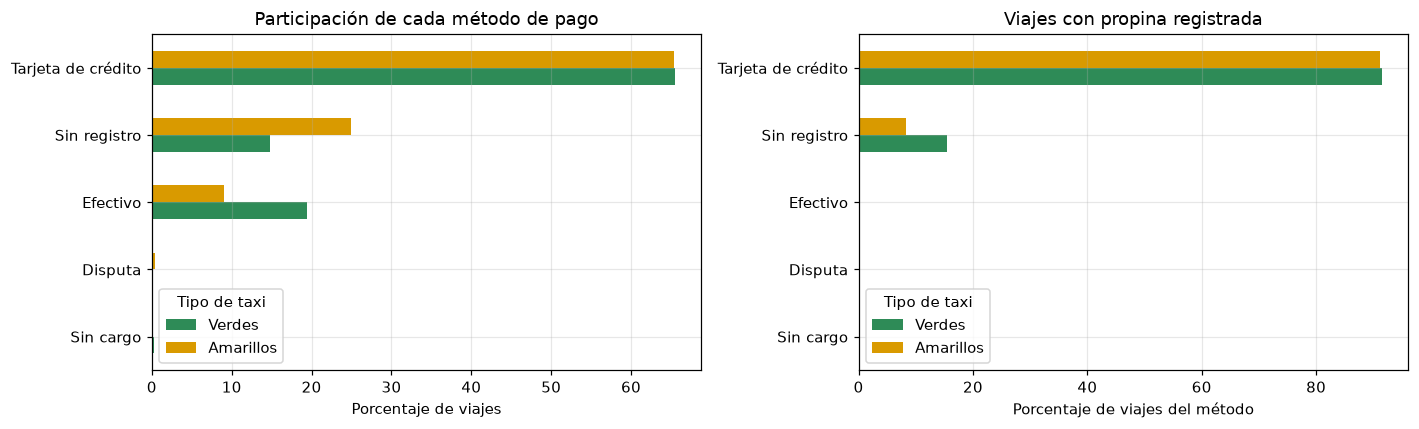

Figura 6. Métodos de pago y proporción de viajes con propina registrada en 2026 por tipo de taxi


In [24]:
pagos = bitacora.ejecutar("e4_pago_propina", mostrar=display, filas=20)

figura, ejes = plt.subplots(1, 2, figsize=(13, 4))
tabla_pagos = pagos.pivot(index="metodo_pago", columns="tipo_taxi", values="porcentaje_viajes").fillna(0)
tabla_pagos = tabla_pagos.sort_values("yellow")[["green", "yellow"]].rename(columns=NOMBRES_TIPO)
tabla_pagos.plot(kind="barh", ax=ejes[0], color=[VERDE, AMARILLO])
ejes[0].set_title("Participación de cada método de pago")
ejes[0].set_xlabel("Porcentaje de viajes")
ejes[0].set_ylabel("")
tabla_propina = pagos.pivot(index="metodo_pago", columns="tipo_taxi", values="pct_con_propina").fillna(0)
tabla_propina = tabla_propina.loc[tabla_pagos.index][["green", "yellow"]].rename(columns=NOMBRES_TIPO)
tabla_propina.plot(kind="barh", ax=ejes[1], color=[VERDE, AMARILLO])
ejes[1].set_title("Viajes con propina registrada")
ejes[1].set_xlabel("Porcentaje de viajes del método")
ejes[1].set_ylabel("")
figura.tight_layout()
guardar_figura(figura, "Métodos de pago y proporción de viajes con propina registrada en 2026 por tipo de taxi")

La tarjeta de crédito es el método principal en ambos servicios con una participación casi idéntica, 65.37 % en amarillos y 65.51 % en verdes. La diferencia está en el resto: en los amarillos el 24.95 % de los viajes válidos no tiene método de pago registrado y solo el 9.06 % se paga en efectivo, mientras que en los verdes el efectivo llega al 19.40 % y los viajes sin registro son el 14.79 %. Los pasajeros de los taxis verdes usan efectivo con el doble de frecuencia.

La propina solo es observable en los pagos con tarjeta. Con tarjeta el 91.1 % de los viajes registra propina en los amarillos y el 91.5 % en los verdes, con una mediana de 26.38 % y 23.55 % de la tarifa. En efectivo prácticamente ningún viaje registra propina, 0.01 % o menos, porque el taxímetro no la captura, por lo que un promedio de propina sobre todos los viajes subestimaría lo que reciben los conductores. Los viajes Sin registro tienen el monto promedio más alto, 32.44 dólares en amarillos, y el 8.26 % registra propina, lo que sugiere que una parte de ellos son pagos con tarjeta que llegaron sin código de pago.

### 4.6 – Valores atípicos e inconsistencias

Pregunta 9. Entre los viajes válidos se calcula la tarifa por milla y se marcan como atípicos los valores fuera de 1.5 veces el rango intercuartílico. Se excluyen los viajes de menos de 0.1 millas porque dividir entre distancias tan pequeñas produce valores extremos sin significado.

In [25]:
atipicos = bitacora.ejecutar("e4_atipicos_tarifa", mostrar=display)

Consulta e4_atipicos_tarifa
  Objetivo: Pregunta 9. Qué viajes válidos tienen una tarifa por milla atípica según el criterio de rango intercuartílico.
  Fuentes : vista viajes_validos
  Resultado: 2 filas en 10.40 s


,tipo_taxi,q1,q3,limite_superior,viajes,atipicos_altos,atipicos_bajos,pct_atipicos
0,yellow,5.710,9.870,16.110,28005034,1450189,0,5.180
1,green,5.330,8.130,12.340,319401,14419,28201,13.340


El criterio de rango intercuartílico se calculó por separado para cada tipo de taxi. En los amarillos la tarifa por milla tiene cuartiles de 5.71 y 9.87 dólares, con límite superior de 16.11 dólares por milla; 1,450,189 viajes válidos, el 5.18 %, lo superan, y no hay atípicos bajos porque el límite inferior resulta negativo. En los verdes los cuartiles son 5.33 y 8.13, el límite superior es 12.34 y hay atípicos en ambos extremos, 14,419 altos y 28,201 bajos, en total el 13.34 % de sus viajes válidos.

Estos viajes cumplen todas las reglas de calidad, por lo que no se excluyen, pero muestran que una relación coherente entre distancia y tiempo no garantiza una relación coherente entre distancia y monto. Los atípicos altos se concentran previsiblemente en viajes cortos y lentos, donde la bajada de bandera y el cobro por tiempo detenido pesan más que la distancia. Los atípicos bajos de los verdes, más numerosos que los altos, son compatibles con tarifas fijas o negociadas en las que el monto no depende de la distancia; confirmarlo requeriría cruzar con el código de tarifa. Para análisis de precio conviene reportar medianas o excluir estos viajes explícitamente.

### 4.7 – Hallazgos principales

La siguiente celda reúne las cifras que sustentan los hallazgos del análisis exploratorio.

In [26]:
resumen_hallazgos = caracteristicas.set_index("tipo_taxi")[["viajes", "distancia_mediana", "duracion_mediana", "total_mediano", "pct_aeropuerto"]]
resumen_hallazgos["pct_validos"] = validos
resumen_hallazgos["pct_viajes_del_total"] = 100 * resumen_hallazgos["viajes"] / resumen_hallazgos["viajes"].sum()
tarjeta = pagos[pagos["metodo_pago"] == "Tarjeta de crédito"].set_index("tipo_taxi")
resumen_hallazgos["pct_pago_tarjeta"] = tarjeta["porcentaje_viajes"]
resumen_hallazgos["propina_mediana_tarjeta_pct"] = tarjeta["propina_mediana_pct"]
resumen_hallazgos["pct_tarifa_por_milla_atipica"] = atipicos.set_index("tipo_taxi")["pct_atipicos"]
display(resumen_hallazgos.T)
bitacora.exportar(ARCHIVO_CONSULTAS)

tipo_taxi,yellow,green
viajes,"28,229,225.000","322,011.000"
distancia_mediana,1.930,2.150
duracion_mediana,14.100,13.400
total_mediano,23.580,20.520
pct_aeropuerto,8.160,3.350
pct_validos,95.037,95.520
pct_viajes_del_total,98.872,1.128
pct_pago_tarjeta,65.370,65.510
propina_mediana_tarjeta_pct,26.380,23.550
pct_tarifa_por_milla_atipica,5.180,13.340


PosixPath('/workspace/docs/consultas.md')

Los principales hallazgos del análisis exploratorio de 2026 son los siguientes.

1. El conjunto está dominado por los taxis amarillos, que aportan el 98.87 % de los viajes válidos. Cualquier indicador global describe a ese servicio, por lo que todas las comparaciones de este laboratorio se separan por tipo de taxi.
2. La calidad de los datos es aceptable pero no ignorable. Cerca del 5 % de los registros de cada tipo se excluye, sobre todo por distancia cero, y uno de cada cuatro registros de taxis amarillos llega sin método de pago ni número de pasajeros, un faltante estructural de la fuente y no un error aislado.
3. La demanda tiene una estacionalidad y un ciclo diario marcados. Los amarillos alcanzan su máximo en mayo, 126,187 viajes por día, y bajan 19 % en agosto; dentro del día el pico es a las 18 horas y entre semana la velocidad mediana se mantiene entre 7.4 y 7.7 mph de las 11 a las 17 horas.
4. Los dos servicios son complementarios. Los amarillos se concentran en Manhattan y en los aeropuertos, con viajes más caros, mediana de 23.58 dólares; los verdes dependen de East Harlem y de zonas de Queens y Brooklyn, con viajes algo más largos pero más baratos, mediana de 20.52 dólares.
5. Los aeropuertos son pocos viajes de alto valor. Representan el 8.16 % de los viajes amarillos, con medianas de 89.21 dólares a JFK y 131.68 a Newark, cuatro a seis veces un viaje urbano.
6. La propina solo puede analizarse con tarjeta. Con ese método el 91 % de los viajes registra propina y la mediana es de 26.38 % en amarillos y 23.55 % en verdes; en efectivo la propina no se registra.
7. Las reglas de calidad no detectan todas las anomalías. El 5.18 % de los viajes válidos amarillos y el 13.34 % de los verdes tienen una tarifa por milla atípica.

## Ejercicio 5 – Incorporación incremental de los datos de 2024

Se amplía el sistema para trabajar con 2024 y 2026. Los datos de 2024 se obtienen desde la fuente original con el mismo script, se verifica que los archivos de 2026 se conservan y no se descargan de nuevo, y se valida con DuckDB que la información de ambos años se puede consultar en conjunto. Las consultas de validación están en sql/03_incorporacion.sql.

### 5.1 – Ampliación del sistema de descarga

El script del Ejercicio 2 ya recibe los años como parámetro, por lo que incorporar 2024 no requiere modificar código: basta con indicar los años deseados. Se ejecuta con 2024 y 2026 para mostrar que los archivos de 2026 se omiten y solo se descargan los de 2024.

In [27]:
salida_2024 = ejecutar_script(SCRIPT_DESCARGA, "--anios", 2024, 2026)
print(SEPARADOR)
for concepto, cantidad in contar_descargas(salida_2024).items():
    print(f"{concepto:<24}{cantidad}")

Comando: python scripts/download_data.py --anios 2024 2026


ZONAS DE TAXI
------------------------------------------------------------
  zonas  ya existe, se omite -> data/raw/zonas/taxi_zone_lookup.csv

YELLOW 2024
------------------------------------------------------------


  2024-01  descargando...


  2024-01  listo (47.6 MiB) -> data/raw/yellow/2024/yellow_tripdata_2024-01.parquet


  2024-02  descargando...


...

  2026-12  aun no publicado por la TLC

GREEN 2026
------------------------------------------------------------
  2026-01  ya existe, se omite
  2026-02  ya existe, se omite
  2026-03  ya existe, se omite
  2026-04  ya existe, se omite
  2026-05  ya existe, se omite
  2026-06  ya existe, se omite
  2026-07  ya existe, se omite
  2026-08  ya existe, se omite


  2026-09  aun no publicado por la TLC


  2026-10  aun no publicado por la TLC


  2026-11  aun no publicado por la TLC


  2026-12  aun no publicado por la TLC

RESUMEN
------------------------------------------------------------
  anios          : 2024, 2026
  zonas          : omitido
  descargados    : 24
  ya existian    : 16
  no publicados  : 8
      yellow 2026-09, yellow 2026-10, yellow 2026-11, yellow 2026-12, green 2026-09, green 2026-10, green 2026-11, green 2026-12
  errores de red : 0
  fallidos       : 0
------------------------------------------------------------
Codigo de salida: 0
------------------------------------------------------------
omitidos por existir    17
descargados             24
no publicados           8
errores de red          0


### 5.2 – Verificación de los archivos incorporados

In [28]:
ejecutar_script(SCRIPT_DESCARGA, "--anios", 2024, 2026, "--verificar")
manifiesto_e5, resumen_e5 = resumen_manifiesto()
display(resumen_e5)

Comando: python scripts/download_data.py --anios 2024 2026 --verificar



VERIFICACION DE COMPLETITUD
------------------------------------------------------------
  completo                         40
  no publicado                     8
  registros en archivos locales    71,870,407
  manifiesto -> data/processed/manifiesto_descargas.csv
------------------------------------------------------------
Codigo de salida: 0


,anio,tipo,diagnostico,meses,registros,mb_locales
0,2024,green,completo,12,660218,15.920
1,2024,yellow,completo,12,41169720,693.002
2,2026,green,completo,8,337114,8.275
3,2026,green,no publicado,4,0,0.000
4,2026,yellow,completo,8,29703355,511.452
5,2026,yellow,no publicado,4,0,0.000


### 5.3 – Consulta conjunta de 2024 y 2026

Se vuelven a crear las capas con los dos años. La vista normalizada se genera de nuevo a partir de los esquemas de todos los archivos, por lo que absorbe las diferencias entre años. Las validaciones comprueban la cobertura por año, que la vista lee exactamente los registros declarados por los metadatos de cada archivo, qué columnas cambian entre años y que los meses comunes de ambos años producen series comparables.

In [29]:
ANIOS_E5 = [2024, 2026]
parametros_e5 = parametros_fuentes(ANIOS_E5)
fuentes_e5 = describir_fuentes(ANIOS_E5)
taxis.preparar_capas(con, ANIOS_E5, guardar=ARCHIVO_VISTA)
cobertura_e5 = bitacora.ejecutar("val_cobertura_anual", parametros_e5, "vista viajes sobre " + fuentes_e5, display)
conteo_e5 = bitacora.ejecutar("val_conteo_por_archivo", parametros_e5, fuentes_e5, display)
esquema_e5 = bitacora.ejecutar("val_esquema_por_anio", parametros_e5, fuentes_e5, display)

Consulta val_cobertura_anual
  Objetivo: Verificar por año y tipo de taxi cuántos archivos, meses y registros cubre la vista conjunta y su rango de fechas.
  Fuentes : vista viajes sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 4 filas en 2.07 s


,anio,tipo_taxi,archivos,meses,registros,primera_recogida,ultima_recogida
0,2024,yellow,12,12,41169720,2024-01-01 00:00:00,2024-12-31 23:59:58
1,2024,green,12,12,660218,2024-01-01 00:03:57,2024-12-31 23:58:02
2,2026,yellow,8,8,29703355,2026-01-01 00:00:00,2026-08-31 23:59:59
3,2026,green,8,8,337114,2026-01-01 00:03:27,2026-08-31 23:58:28


Consulta val_conteo_por_archivo
  Objetivo: Comparar archivo por archivo los registros que lee la vista conjunta con los registros declarados en los metadatos Parquet.
  Fuentes : data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 1 filas en 0.44 s


,archivos,registros_metadatos,registros_vista,archivos_con_diferencia
0,40,71870407,71870407,0


Consulta val_esquema_por_anio
  Objetivo: Identificar columnas que existen solo en algunos años o cuyo tipo físico cambia de un año a otro.
  Fuentes : data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 4 filas en 0.10 s


,tipo_taxi,columna,anios_presente,tipos_por_anio
0,yellow,cbd_congestion_fee,2026,2026 DOUBLE
1,yellow,request_source,2026,2026 VARCHAR
2,green,cbd_congestion_fee,2026,2026 DOUBLE
3,green,request_source,2026,2026 VARCHAR


Consulta val_meses_comparables
  Objetivo: Comparar los mismos meses entre años para validar que la consulta conjunta produce series comparables.
  Fuentes : vista viajes_validos sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 32 filas en 9.02 s


,tipo_taxi,mes,anio,viajes,cambio_pct_vs_primer_anio
0,yellow,1,2024,2867133,0.000
1,yellow,1,2026,3516139,22.640
2,yellow,2,2024,2899130,0.000
3,yellow,2,2026,3210025,10.720
4,yellow,3,2024,3437442,0.000
5,yellow,3,2026,3762447,9.450
6,yellow,4,2024,3411726,0.000
7,yellow,4,2026,3673823,7.680
8,yellow,5,2024,3615186,0.000
9,yellow,5,2026,3911803,8.200


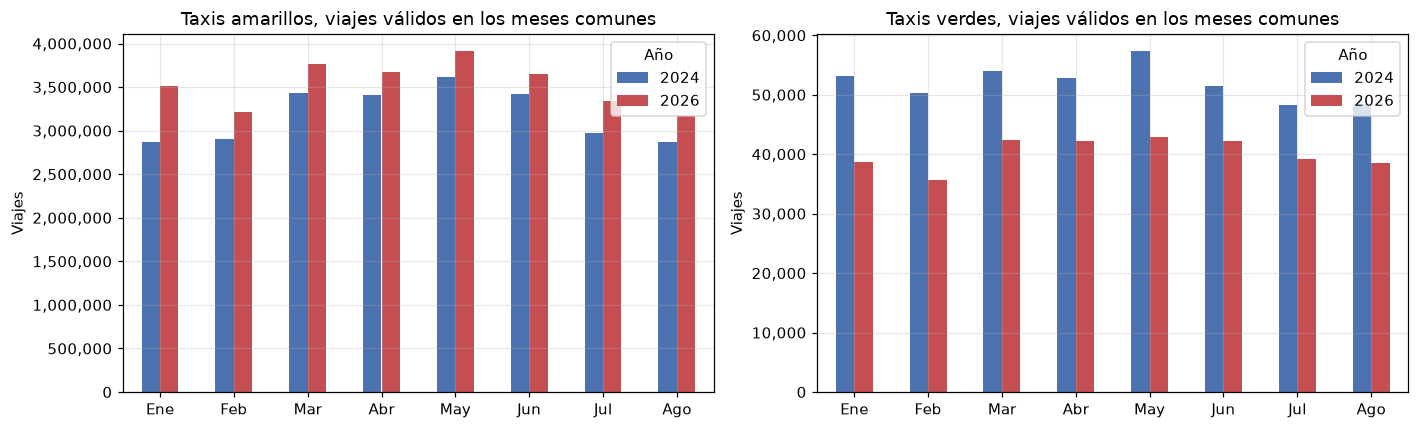

Figura 7. Viajes válidos por mes en los meses disponibles tanto en 2024 como en 2026


In [30]:
comparables_e5 = bitacora.ejecutar("val_meses_comparables", parametros_e5, "vista viajes_validos sobre " + fuentes_e5,
                                   display, filas=12)

figura, ejes = plt.subplots(1, 2, figsize=(13, 4))
for eje, tipo in zip(ejes, ("yellow", "green")):
    tabla = comparables_e5[comparables_e5["tipo_taxi"] == tipo].pivot(index="mes", columns="anio", values="viajes")
    tabla.index = [MESES[m - 1] for m in tabla.index]
    tabla.plot(kind="bar", ax=eje, color=["#4C72B0", "#C44E52"], rot=0)
    eje.set_title(f"Taxis {NOMBRES_TIPO[tipo].lower()}, viajes válidos en los meses comunes")
    eje.set_ylabel("Viajes")
    eje.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
figura.tight_layout()
guardar_figura(figura, "Viajes válidos por mes en los meses disponibles tanto en 2024 como en 2026")

Las validaciones confirman que la consulta conjunta funciona sin cambios. La vista cubre los 12 archivos de cada tipo en 2024 y los 8 de 2026, y en los 40 archivos el número de registros leídos coincide con el declarado en los metadatos, 71,870,407, sin ningún archivo con diferencias. La comparación de esquemas muestra que cbd_congestion_fee y request_source solo existen en 2026; en los archivos de 2024 la vista las rellena con nulos y las consultas que las usan siguen funcionando.

La comparación de los meses comunes produce series coherentes y muestra un cambio real entre años. Los taxis amarillos tienen más viajes válidos en todos los meses de 2026 que en los mismos meses de 2024, con un aumento de 22.64 % en enero que se reduce a 6.43 % en junio. Los verdes se mueven en sentido contrario: según la Figura 7, en 2026 tienen entre 18 % y 29 % menos viajes que en el mismo mes de 2024.

### 5.4 – Reutilización de las consultas anteriores

Las consultas del Ejercicio 4 se ejecutan sin ningún cambio sobre las capas que ahora cubren 2024 y 2026. La tabla resume cada consulta reutilizada con el número de filas obtenido y su tiempo.

In [31]:
CONSULTAS_E4 = [i for i in bitacora.catalogo if i.startswith("e4_")]
reutilizadas = []
for id_consulta in CONSULTAS_E4:
    resultado = bitacora.ejecutar(id_consulta, fuentes="vistas sobre " + fuentes_e5, ejercicio="5")
    reutilizadas.append({"consulta": id_consulta, "filas": len(resultado), "segundos": bitacora.registros[-1]["segundos"]})
display(pd.DataFrame(reutilizadas))

Consulta e4_calidad_exclusiones en el ejercicio 5
  Objetivo: Pregunta 1. Qué proporción de registros incumple alguna regla de calidad y por qué motivo, en cada tipo de taxi.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 17 filas en 7.85 s


Consulta e4_viajes_mensuales en el ejercicio 5
  Objetivo: Pregunta 2. Cómo evoluciona el número de viajes y el ingreso de cada mes por tipo de taxi.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 40 filas en 9.90 s


Consulta e4_patron_horario en el ejercicio 5
  Objetivo: Pregunta 3. En qué horas y tipo de día se concentra la demanda y cómo cambia la velocidad del tráfico.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 48 filas en 16.30 s


Consulta e4_caracteristicas_tipo en el ejercicio 5
  Objetivo: Pregunta 4. En qué se diferencian los viajes de taxis amarillos y verdes en distancia, duración, pasajeros y monto.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 2 filas en 35.62 s


Consulta e4_distribucion_distancia en el ejercicio 5
  Objetivo: Pregunta 5. Cómo se distribuyen las distancias de los viajes en intervalos de una milla por tipo de taxi.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 62 filas en 12.37 s


Consulta e4_pago_propina en el ejercicio 5
  Objetivo: Pregunta 6. Cómo se reparten los métodos de pago y qué porcentaje de propina se registra en cada uno.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 10 filas en 17.58 s


Consulta e4_zonas_origen en el ejercicio 5
  Objetivo: Pregunta 7. Desde qué zonas y distritos sale la mayor parte de los viajes de cada tipo de taxi.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 20 filas en 11.08 s


Consulta e4_aeropuertos en el ejercicio 5
  Objetivo: Pregunta 8. Cuánto pesan los viajes de aeropuerto y en qué se diferencian del resto.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 8 filas en 18.62 s


Consulta e4_atipicos_tarifa en el ejercicio 5
  Objetivo: Pregunta 9. Qué viajes válidos tienen una tarifa por milla atípica según el criterio de rango intercuartílico.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 2 filas en 22.57 s


,consulta,filas,segundos
0,e4_calidad_exclusiones,17,7.848
1,e4_viajes_mensuales,40,9.898
2,e4_patron_horario,48,16.303
3,e4_caracteristicas_tipo,2,35.621
4,e4_distribucion_distancia,62,12.369
5,e4_pago_propina,10,17.580
6,e4_zonas_origen,20,11.080
7,e4_aeropuertos,8,18.615
8,e4_atipicos_tarifa,2,22.574


Ninguna consulta tuvo que modificarse para trabajar con el nuevo conjunto de archivos. Las consultas no mencionan archivos ni años concretos: leen las vistas, y las vistas se generan a partir de los archivos que existen en las carpetas de cada año. Lo que sí cambia es el significado de las consultas que agregan sin separar por año, como la distribución de distancias o el reparto de métodos de pago, porque ahora mezclan dos periodos. Por eso las consultas de validación de este ejercicio y las de evolución del Ejercicio 8 agrupan por el año del archivo, y los indicadores del tablero incluyen el año en todas sus tablas.

### 5.5 – Diseño que permite incorporar archivos nuevos

Cuatro decisiones de diseño permiten incorporar archivos sin rehacer el flujo. El script de descarga recibe los años como parámetro, es incremental y verifica lo descargado, por lo que agregar un año es ejecutar un comando. Los archivos se organizan en carpetas por tipo y año, y las consultas usan patrones glob por carpeta, de modo que cualquier archivo nuevo de un año ya incluido se incorpora automáticamente. La vista normalizada se genera leyendo el esquema real de los archivos, renombra columnas, unifica tipos y rellena con nulos las columnas ausentes, lo que absorbe cambios de esquema como columnas nuevas o con otro tipo. Finalmente, el análisis se escribe contra vistas y no contra archivos, y el año y mes provienen del nombre del archivo, por lo que las consultas, el benchmark y el tablero se actualizan sin cambios.

In [32]:
bitacora.exportar(ARCHIVO_CONSULTAS)
print(f"Consultas documentadas: {len(bitacora.registros)}")

Consultas documentadas: 37


## Ejercicio 6 – Comparación entre consultas sobre Parquet y tablas materializadas en DuckDB

Se compara el tiempo de ejecución de las mismas consultas con dos estrategias: leer los archivos Parquet en cada ejecución a través de la vista normalizada, y leer una tabla DuckDB materializada a partir de esa misma vista. El benchmark usa los años disponibles en este punto, 2024 y 2026, con cuatro volúmenes crecientes de datos. Las consultas están en sql/04_benchmark.sql y representan los tipos de operación del análisis exploratorio.

### 6.1 – Diseño del benchmark

- Volúmenes: 1 mes, 3 meses, 12 meses y todos los meses descargados. Cada volumen es una lista de archivos, y la tabla de cada volumen se crea desde una vista sobre esos mismos archivos, por lo que ambas estrategias procesan exactamente los mismos registros.
- Consultas: conteo total, agregado mensual, filtro selectivo de aeropuertos, patrón horario con mediana, percentiles y unión con la tabla de zonas.
- Medición: cada consulta se ejecuta una vez de calentamiento y luego cinco repeticiones medidas, materializando el resultado completo. Se reporta la mediana, que es robusta a interrupciones del sistema operativo, y se conserva el tiempo de la primera ejecución.
- Aislamiento: el benchmark usa su propia base data/processed/benchmark.duckdb, con la misma configuración de memoria del notebook. Las tablas de los volúmenes intermedios se eliminan al terminar su medición y solo se conserva la del volumen completo, con el nombre viajes_materializada.
- Costo de materializar: se registra el tiempo de creación de cada tabla y el espacio que ocupa en la base, para compararlo con el ahorro que produce en las consultas.

Antes de medir se ejecuta cada consulta del benchmark una vez sobre la vista conjunta para documentarla y verificar que funciona.

In [33]:
volumenes = taxis.volumenes_benchmark(ANIOS_E5)
display(pd.DataFrame([{"volumen": nombre, "archivos": len(archivos),
                       "periodos": f"{archivos[0].stem[-7:]} a {max(a.stem[-7:] for a in archivos)}" if len(archivos) > 2 else archivos[0].stem[-7:],
                       "mb_parquet": sum(a.stat().st_size for a in archivos) / 1e6}
                      for nombre, archivos in volumenes.items()]))
CONSULTAS_BENCHMARK = [i for i in bitacora.catalogo if i.startswith("b")]
for id_consulta in CONSULTAS_BENCHMARK:
    bitacora.ejecutar(id_consulta, {"fuente": "viajes"}, "vista viajes sobre " + fuentes_e5)

,volumen,archivos,periodos,mb_parquet
0,1 mes,2,2026-01,65.157
1,3 meses,6,2026-01 a 2026-03,193.735
2,12 meses,24,2024-01 a 2024-12,708.922
3,Todos los meses,40,2024-01 a 2026-08,"1,228.649"


Consulta b1_conteo_total
  Objetivo: Contar todos los registros, la consulta más simple posible, que en Parquet puede resolverse con metadatos.
  Fuentes : vista viajes sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 1 filas en 0.29 s


Consulta b2_agregado_mensual
  Objetivo: Agregar viajes, ingreso y distancia por tipo de taxi, año y mes, como en el análisis temporal.
  Fuentes : vista viajes sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 54 filas en 4.29 s


Consulta b3_filtro_selectivo
  Objetivo: Filtrar los viajes que salen de los aeropuertos con más de 10 millas y resumirlos por aeropuerto.
  Fuentes : vista viajes sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 3 filas en 4.82 s


Consulta b4_patron_horario
  Objetivo: Calcular viajes y duración mediana por día de la semana y hora.
  Fuentes : vista viajes sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 168 filas en 4.57 s


Consulta b5_percentiles
  Objetivo: Calcular percentiles de distancia y total por tipo de taxi y método de pago.
  Fuentes : vista viajes sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 12 filas en 11.27 s


Consulta b6_union_zonas
  Objetivo: Unir los viajes con la tabla de zonas y resumir viajes e ingreso por distrito de origen y destino.
  Fuentes : vista viajes sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 64 filas en 3.09 s


### 6.2 – Ejecución del benchmark

La siguiente celda puede tardar varios minutos con los datos completos, porque materializa una tabla por volumen y repite cada consulta con ambas estrategias. El mismo procedimiento se puede reproducir fuera del notebook con python scripts/benchmark.py --anios 2024 2026.

In [34]:
inicio = time.perf_counter()
detalle_benchmark, cargas_benchmark = taxis.ejecutar_benchmark(volumenes, REPETICIONES_BENCHMARK)
resumen_benchmark, comparacion_benchmark = taxis.resumir_benchmark(detalle_benchmark)
detalle_benchmark.to_csv(DIR_BENCHMARK / "benchmark_detalle.csv", index=False)
resumen_benchmark.to_csv(DIR_BENCHMARK / "benchmark_resumen.csv", index=False)
comparacion_benchmark.to_csv(DIR_BENCHMARK / "benchmark_comparacion.csv", index=False)
cargas_benchmark.to_csv(DIR_BENCHMARK / "benchmark_cargas.csv", index=False)
print(SEPARADOR)
print(f"Benchmark completado en {time.perf_counter() - inicio:.1f} s, resultados en {DIR_BENCHMARK.relative_to(RAIZ)}")
display(cargas_benchmark)

1 mes: 2 archivos, 3,765,161 registros, tabla creada en 5.04 s


3 meses: 6 archivos, 11,199,059 registros, tabla creada en 10.51 s


12 meses: 24 archivos, 41,829,938 registros, tabla creada en 41.19 s


Todos los meses: 40 archivos, 71,870,407 registros, tabla creada en 93.11 s


------------------------------------------------------------
Benchmark completado en 745.6 s, resultados en docs/benchmark


,volumen,archivos,registros,mb_parquet,mb_tabla_duckdb,segundos_materializacion
0,1 mes,2,3765161,65.157,133.956,5.045
1,3 meses,6,11199059,193.735,401.342,10.510
2,12 meses,24,41829938,708.922,"1,496.056",41.190
3,Todos los meses,40,71870407,"1,228.649","2,583.953",93.112


### 6.3 – Resultados del benchmark

La tabla principal muestra la mediana de cada consulta con ambas estrategias y el cociente entre el tiempo sobre Parquet y el tiempo sobre la tabla. Un cociente mayor que uno indica que la tabla materializada fue más rápida.

In [35]:
tabla_benchmark = comparacion_benchmark.rename(columns={"Parquet directo": "parquet_s", "Tabla DuckDB": "tabla_s"})
display(tabla_benchmark)
cocientes = tabla_benchmark.pivot(index="consulta", columns="volumen", values="parquet_entre_tabla")[list(volumenes)]
display(cocientes)

# ejecuciones del conjunto de consultas necesarias para recuperar el tiempo invertido en materializar
ahorro = (tabla_benchmark.assign(diferencia=lambda d: d["parquet_s"] - d["tabla_s"])
          .groupby("volumen", sort=False)["diferencia"].sum())
amortizacion = cargas_benchmark.set_index("volumen")[["registros", "mb_parquet", "mb_tabla_duckdb", "segundos_materializacion"]]
amortizacion["ahorro_por_ejecucion_s"] = ahorro
amortizacion["ejecuciones_para_amortizar"] = amortizacion["segundos_materializacion"] / amortizacion["ahorro_por_ejecucion_s"]
display(amortizacion)

,volumen,registros,consulta,parquet_s,tabla_s,parquet_entre_tabla
0,1 mes,3765161,b1_conteo_total,0.024,0.001,16.712
1,1 mes,3765161,b2_agregado_mensual,0.221,0.087,2.552
2,1 mes,3765161,b3_filtro_selectivo,0.364,0.029,12.674
3,1 mes,3765161,b4_patron_horario,0.470,0.172,2.732
4,1 mes,3765161,b5_percentiles,0.565,0.431,1.311
5,1 mes,3765161,b6_union_zonas,0.196,0.065,2.998
6,3 meses,11199059,b1_conteo_total,0.057,0.003,22.717
7,3 meses,11199059,b2_agregado_mensual,0.563,0.187,3.017
8,3 meses,11199059,b3_filtro_selectivo,0.742,0.089,8.337
9,3 meses,11199059,b4_patron_horario,0.998,0.494,2.018


volumen,1 mes,3 meses,12 meses,Todos los meses
consulta,,,,
b1_conteo_total,16.712,22.717,35.108,29.064
b2_agregado_mensual,2.552,3.017,2.985,3.430
b3_filtro_selectivo,12.674,8.337,6.385,8.825
b4_patron_horario,2.732,2.018,1.298,2.406
b5_percentiles,1.311,1.028,1.231,1.396
b6_union_zonas,2.998,2.548,3.186,2.758


,registros,mb_parquet,mb_tabla_duckdb,segundos_materializacion,ahorro_por_ejecucion_s,ejecuciones_para_amortizar
volumen,,,,,,
1 mes,3765161,65.157,133.956,5.045,1.055,4.784
3 meses,11199059,193.735,401.342,10.510,2.025,5.191
12 meses,41829938,708.922,"1,496.056",41.190,8.043,5.121
Todos los meses,71870407,"1,228.649","2,583.953",93.112,22.685,4.105


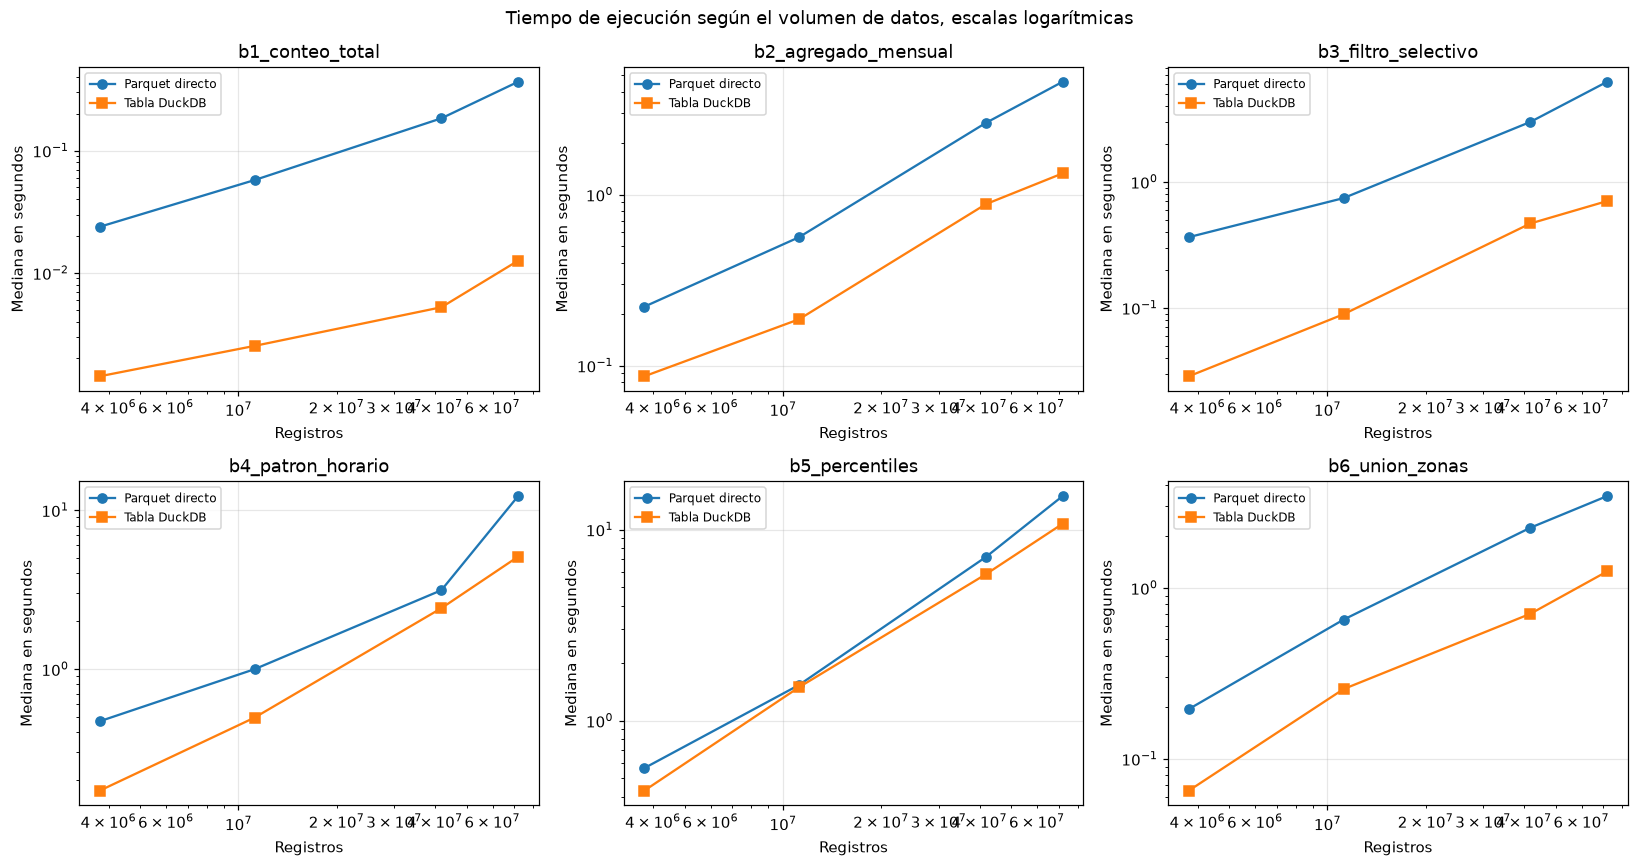

Figura 8. Mediana del tiempo de cada consulta del benchmark según el volumen, Parquet directo frente a tabla DuckDB


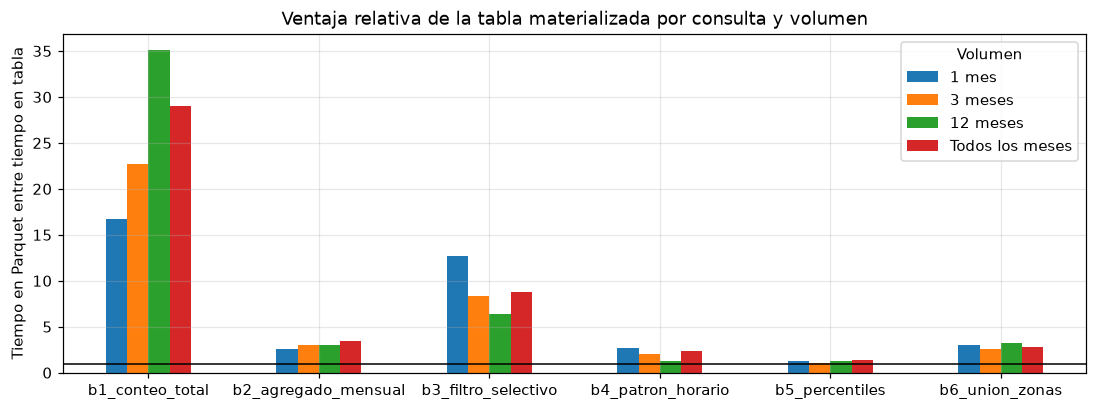

Figura 9. Cociente entre el tiempo sobre Parquet y el tiempo sobre la tabla DuckDB por consulta y volumen


In [36]:
consultas_b = list(dict.fromkeys(tabla_benchmark["consulta"]))
figura, ejes = plt.subplots(2, 3, figsize=(15, 8))
for eje, consulta in zip(ejes.flat, consultas_b):
    datos = tabla_benchmark[tabla_benchmark["consulta"] == consulta]
    eje.plot(datos["registros"], datos["parquet_s"], marker="o", label="Parquet directo")
    eje.plot(datos["registros"], datos["tabla_s"], marker="s", label="Tabla DuckDB")
    eje.set_xscale("log")
    eje.set_yscale("log")
    eje.set_title(consulta)
    eje.set_xlabel("Registros")
    eje.set_ylabel("Mediana en segundos")
    eje.legend(fontsize=8)
figura.suptitle("Tiempo de ejecución según el volumen de datos, escalas logarítmicas")
figura.tight_layout()
guardar_figura(figura, "Mediana del tiempo de cada consulta del benchmark según el volumen, Parquet directo frente a tabla DuckDB")

figura, eje = plt.subplots(figsize=(12, 4))
cocientes.plot(kind="bar", ax=eje, rot=0)
eje.axhline(1, color="black", linewidth=1)
eje.set_ylabel("Tiempo en Parquet entre tiempo en tabla")
eje.set_xlabel("")
eje.set_title("Ventaja relativa de la tabla materializada por consulta y volumen")
guardar_figura(figura, "Cociente entre el tiempo sobre Parquet y el tiempo sobre la tabla DuckDB por consulta y volumen")

### 6.4 – Análisis de los resultados

La tabla materializada fue más rápida en todas las consultas y en todos los volúmenes, pero la ventaja depende mucho del tipo de consulta. Con todos los meses, 71.9 millones de registros, las seis consultas tardaron en conjunto 41.8 s sobre Parquet y 19.1 s sobre la tabla, un ahorro de 22.7 s por cada ejecución del conjunto.

- Las consultas que leen pocas columnas y hacen agregaciones simples son las que más ganan. El agregado mensual fue entre 2.6 y 3.4 veces más rápido sobre la tabla y la unión con zonas entre 2.5 y 3.2 veces. El filtro selectivo de aeropuertos ganó entre 6.4 y 12.7 veces: sobre la tabla DuckDB filtra columnas ya convertidas y almacenadas con sus propias estadísticas, mientras que sobre Parquet debe leer y convertir los archivos a través de la vista antes de descartar la mayoría de las filas.
- El conteo total muestra cocientes de 17 a 35, pero en tiempos absolutos ambas estrategias son casi instantáneas, 0.37 s frente a 0.013 s con todos los meses, por lo que no es una diferencia relevante en la práctica.
- Los percentiles casi no se benefician, con cocientes de 1.0 a 1.4. Su costo está dominado por ordenar y calcular cuantiles exactos, no por leer los datos, y ese trabajo es el mismo con ambas fuentes. El patrón horario, que calcula medianas, queda en un punto intermedio, de 1.3 a 2.7.

La Figura 8 muestra que con ambas estrategias el tiempo crece de forma aproximadamente proporcional al número de registros. De 1 mes a todos los meses los registros se multiplican por 19 y el agregado mensual sobre Parquet pasa de 0.22 s a 4.56 s, unas 21 veces más. Por eso la Figura 9 no muestra una tendencia clara del cociente con el volumen: la ventaja de la tabla es un factor más o menos constante por tipo de consulta y no algo que aparezca solo con datos grandes.

El costo de materializar es alto. Con todos los meses la tabla tardó 93.1 s en crearse y ocupa 2,584 MB, 2.1 veces los 1,229 MB de los Parquet, porque el formato interno de DuckDB comprime menos que Parquet y la tabla guarda también las columnas que agrega la vista. Con el ahorro medido, la creación se recupera después de cuatro a cinco ejecuciones del conjunto de consultas en todos los volúmenes. Para una consulta aislada conviene Parquet; para un uso repetido, como un tablero o un análisis iterativo, la tabla se paga sola en pocas ejecuciones.

### 6.5 – Escenarios para cada estrategia

Consultar directamente los archivos Parquet es apropiado en la exploración inicial, cuando todavía no se sabe qué columnas o periodos interesan; cuando los datos llegan continuamente y deben estar disponibles en cuanto se descargan; cuando una consulta se ejecuta pocas veces o lee pocas columnas con filtros selectivos que aprovechan las estadísticas del archivo; y cuando duplicar el almacenamiento no es aceptable o los archivos son compartidos por otras herramientas.

Materializar una tabla en DuckDB conviene cuando un mismo conjunto se consulta muchas veces, como un tablero que se refresca o un análisis iterativo, porque el costo de creación se recupera después de algunas ejecuciones; cuando las consultas requieren transformaciones costosas que conviene calcular una sola vez, como la normalización de esquemas o la unión con otras tablas; y cuando otra herramienta necesita un archivo estable con un esquema fijo, como Metabase en este laboratorio. Una solución intermedia, la usada en el Ejercicio 7, es materializar solo los agregados que se consultan repetidamente y mantener el detalle en Parquet.

## Ejercicio 7 – Indicadores y tablero de análisis en Metabase

Se definen preguntas de análisis, se diseña un indicador para cada una y se construye el tablero en Metabase. Cada indicador está respaldado por una consulta de sql/05_indicadores.sql que se ejecuta con DuckDB sobre la vista de viajes válidos y se guarda como tabla en data/processed/tablero.duckdb. Metabase se conecta a esa base en modo de solo lectura. En este ejercicio el tablero cubre 2024 y 2026; en el Ejercicio 8 se reconstruye con los tres años sin cambiar ninguna consulta.

### 7.1 – Preguntas e indicadores

Se definieron trece preguntas y trece indicadores. La tabla se genera desde los metadatos del catálogo SQL, de modo que la pregunta, el indicador y su justificación están en el mismo bloque que la consulta que lo calcula. Los indicadores cubren volumen, tendencia, perfil horario, congestión, día de la semana, pago, propina, geografía, aeropuertos, participación por tipo de taxi, calidad de datos y recargos, las dimensiones que el Ejercicio 4 mostró como relevantes para entender el servicio.

In [37]:
indicadores_catalogo = pd.DataFrame([{"tabla": i, "indicador": info["indicador"], "pregunta": info["pregunta"],
                                      "justificacion": info["justificacion"]}
                                     for i, info in bitacora.catalogo.items() if i.startswith("ind_")])
with pd.option_context("display.max_colwidth", None):
    display(indicadores_catalogo)

,tabla,indicador,pregunta,justificacion
0,ind_01_resumen_anual,"Volumen, ingreso y ticket promedio por año",P1. ¿Cuántos viajes válidos e ingresos genera el servicio de taxis cada año y cuál es el monto promedio por viaje?,"Es el punto de partida del tablero, da la escala del servicio y permite comparar años con viajes e ingreso por día aunque 2026 esté incompleto."
1,ind_02_tendencia_mensual,Viajes por día en cada mes y tipo de taxi,P2. ¿Cómo evoluciona mes a mes la demanda de taxis amarillos y verdes?,La serie temporal muestra estacionalidad y tendencia; se usa viajes por día para que los meses de distinta duración sean comparables.
2,ind_03_demanda_horaria,Viajes promedio por hora y tipo de día,P3. ¿En qué horas del día se concentra la demanda y cómo cambia entre semana y fin de semana?,"Identifica horas pico, útil para asignar flota; el promedio por día evita que entre semana domine solo por tener más días."
3,ind_04_velocidad_horaria,Velocidad y duración mediana por hora,P4. ¿En qué horas el tráfico hace más lentos los viajes?,La velocidad es un indicador indirecto de congestión; se usa la mediana por ser robusta a registros extremos.
4,ind_05_dia_semana,Viajes promedio y ticket por día de la semana,P5. ¿Qué días de la semana tienen más viajes y viajes más caros?,Complementa el perfil horario y muestra si el fin de semana cambia el tipo de viaje además del volumen.
5,ind_06_metodo_pago,Participación de métodos de pago,P6. ¿Cómo pagan los pasajeros y cómo cambia la participación de cada método entre años?,El método de pago condiciona la propina registrada y refleja la adopción de pagos electrónicos.
6,ind_07_propina,Porcentaje de propina con tarjeta por franja horaria,P7. ¿Qué porcentaje de propina dejan los pasajeros que pagan con tarjeta y cómo varía por franja horaria y tipo de taxi?,"La propina es parte relevante del ingreso del conductor y solo es observable en pagos con tarjeta, lo que se respeta en el cálculo."
7,ind_08_zonas_origen,Zonas de origen con más viajes,P8. ¿Desde qué zonas sale la mayor cantidad de viajes de cada tipo de taxi?,Muestra la concentración geográfica de la demanda y la diferencia de cobertura entre taxis amarillos y verdes.
8,ind_09_distritos,Viajes e ingreso por distrito de origen,P9. ¿Cómo se reparten los viajes y el ingreso entre los distritos de la ciudad?,Resume la geografía a un nivel legible y evidencia la especialización de los taxis verdes fuera del centro de Manhattan.
9,ind_10_aeropuertos,Viajes de aeropuerto,P10. ¿Qué peso tienen los viajes hacia o desde aeropuertos y cuánto más cuestan que un viaje urbano?,"Los aeropuertos son pocos viajes pero de alto valor, por lo que explican parte importante del ingreso."


### 7.2 – Construcción de la base de indicadores

La base del tablero se escribe primero en un archivo temporal y luego reemplaza a la anterior. Un archivo DuckDB admite un solo proceso con escritura, por lo que Metabase debe estar detenido durante la construcción. Desde una terminal del equipo anfitrión se ejecuta docker compose stop metabase antes de esta celda y docker compose start metabase después. El mismo paso se puede reproducir con python scripts/construir_tablero.py --anios 2024 2026.

In [38]:
try:
    construccion_e7 = taxis.construir_tablero(ANIOS_E5)
except PermissionError as error:
    construccion_e7 = None
    print(error)
if construccion_e7 is not None:
    construccion_e7.to_csv(DIR_TABLERO / "indicadores.csv", index=False)
    display(construccion_e7)
indicadores_e7 = graficos_tablero.leer_indicadores()
for fila in construccion_e7.itertuples() if construccion_e7 is not None else []:
    bitacora.documentar(fila.indicador, indicadores_e7[fila.indicador], fila.segundos, fuentes="vista viajes_validos sobre " + fuentes_e5)
display(indicadores_e7["ind_01_resumen_anual"])

ind_01_resumen_anual: 2 filas


ind_02_tendencia_mensual: 40 filas


ind_03_demanda_horaria: 96 filas


ind_04_velocidad_horaria: 48 filas


ind_05_dia_semana: 14 filas


...

ind_11_participacion_tipo: 4 filas


ind_12_calidad_datos: 34 filas


ind_13_cargos_mensuales: 20 filas


,indicador,pregunta,filas,segundos
0,ind_01_resumen_anual,P1. ¿Cuántos viajes válidos e ingresos genera el servicio de taxis cada año y cuál es el monto promedio por viaje?,2,17.677
1,ind_02_tendencia_mensual,P2. ¿Cómo evoluciona mes a mes la demanda de taxis amarillos y verdes?,40,12.074
2,ind_03_demanda_horaria,P3. ¿En qué horas del día se concentra la demanda y cómo cambia entre semana y fin de semana?,96,13.949
3,ind_04_velocidad_horaria,P4. ¿En qué horas el tráfico hace más lentos los viajes?,48,15.886
4,ind_05_dia_semana,P5. ¿Qué días de la semana tienen más viajes y viajes más caros?,14,15.156
5,ind_06_metodo_pago,P6. ¿Cómo pagan los pasajeros y cómo cambia la participación de cada método entre años?,20,14.315
6,ind_07_propina,P7. ¿Qué porcentaje de propina dejan los pasajeros que pagan con tarjeta y cómo varía por franja horaria y tipo de t...,20,11.910
7,ind_08_zonas_origen,P8. ¿Desde qué zonas sale la mayor cantidad de viajes de cada tipo de taxi?,60,12.315
8,ind_09_distritos,P9. ¿Cómo se reparten los viajes y el ingreso entre los distritos de la ciudad?,31,10.719
9,ind_10_aeropuertos,P10. ¿Qué peso tienen los viajes hacia o desde aeropuertos y cuánto más cuestan que un viaje urbano?,8,13.450


,anio,meses,viajes,viajes_por_dia,ingreso_total,ingreso_por_dia,ticket_promedio,distancia_mediana,duracion_mediana
0,2024,12,40297639,"110,103.000","1,150,848,913.080","3,144,395.940",28.560,1.800,13.070
1,2026,8,28551236,"117,495.000","861,990,773.930","3,547,287.140",30.190,1.930,14.100


### 7.3 – Visualización de los indicadores

Los mismos datos que consume Metabase se dibujan con Matplotlib como evidencia reproducible del tablero. Cada panel corresponde a una pregunta y su título indica el número de la pregunta.

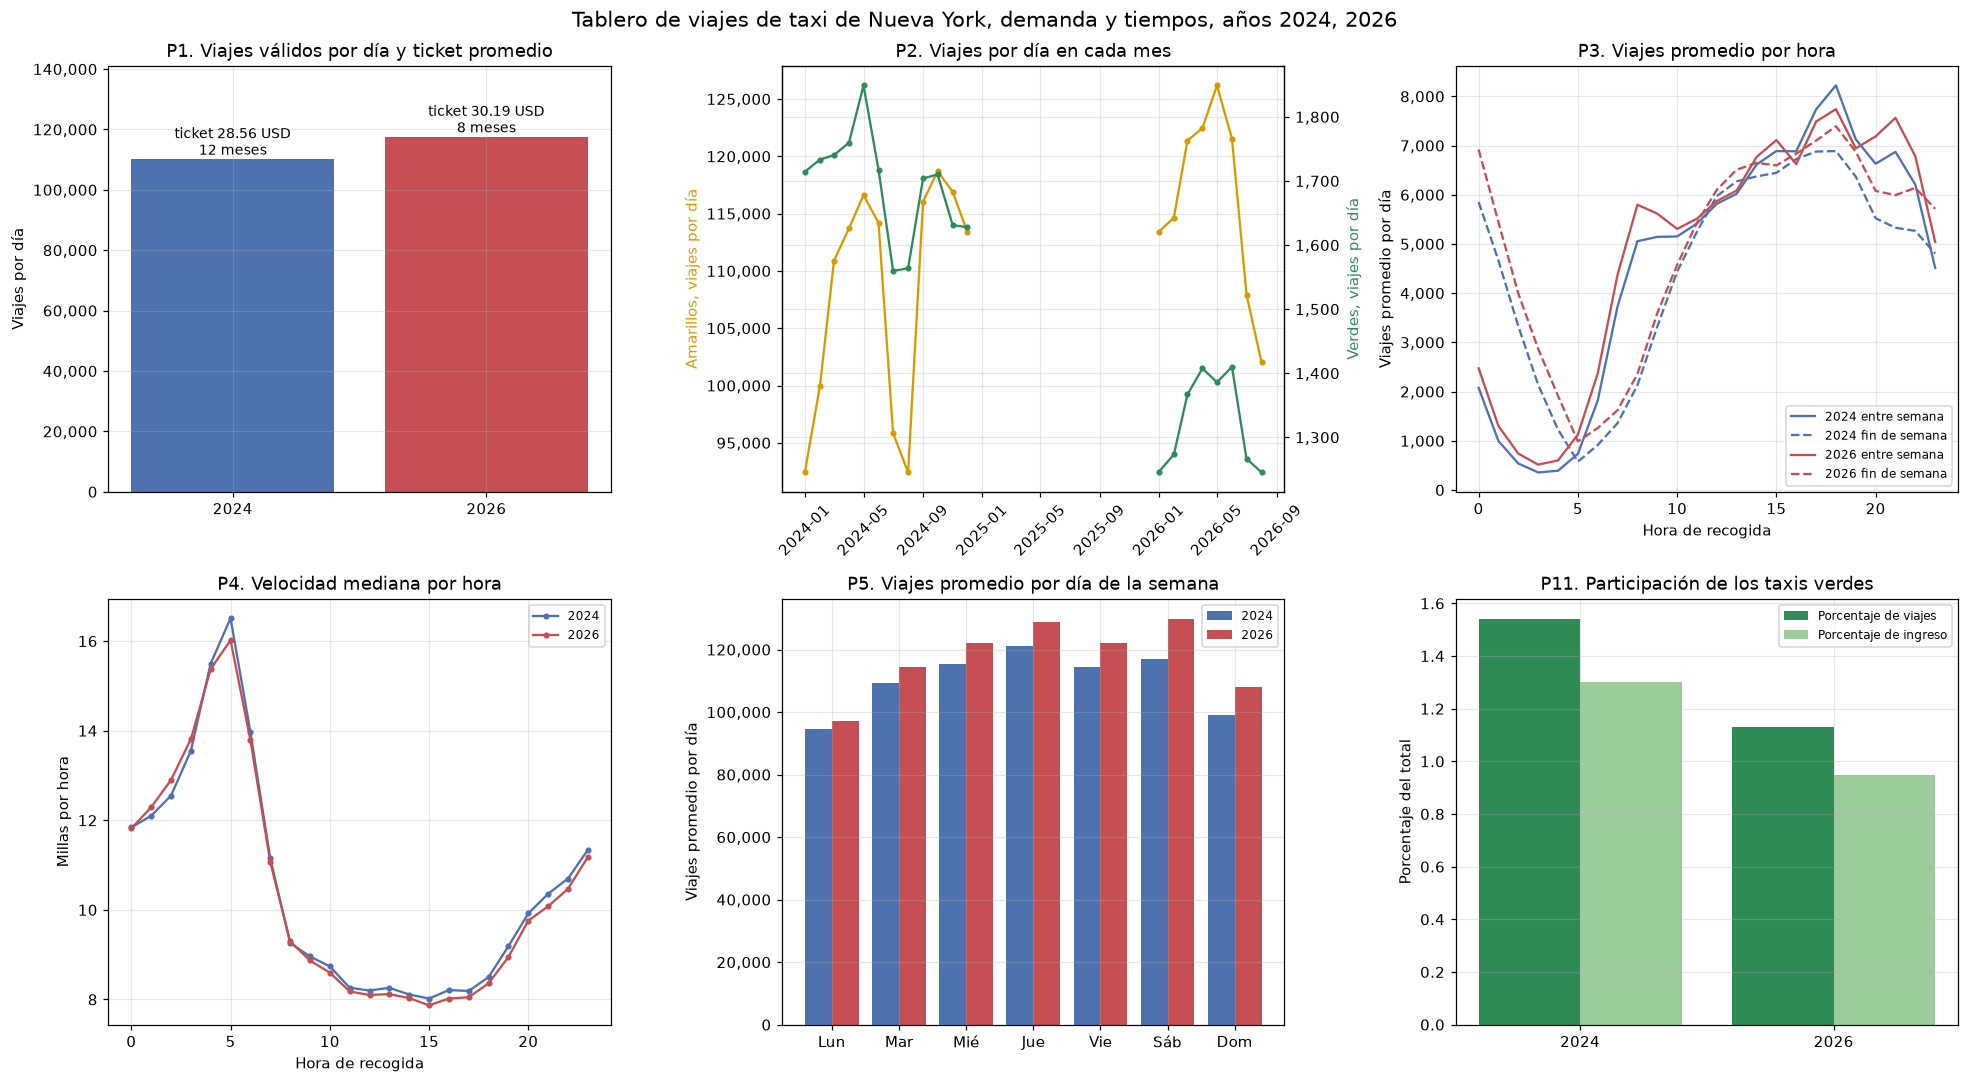

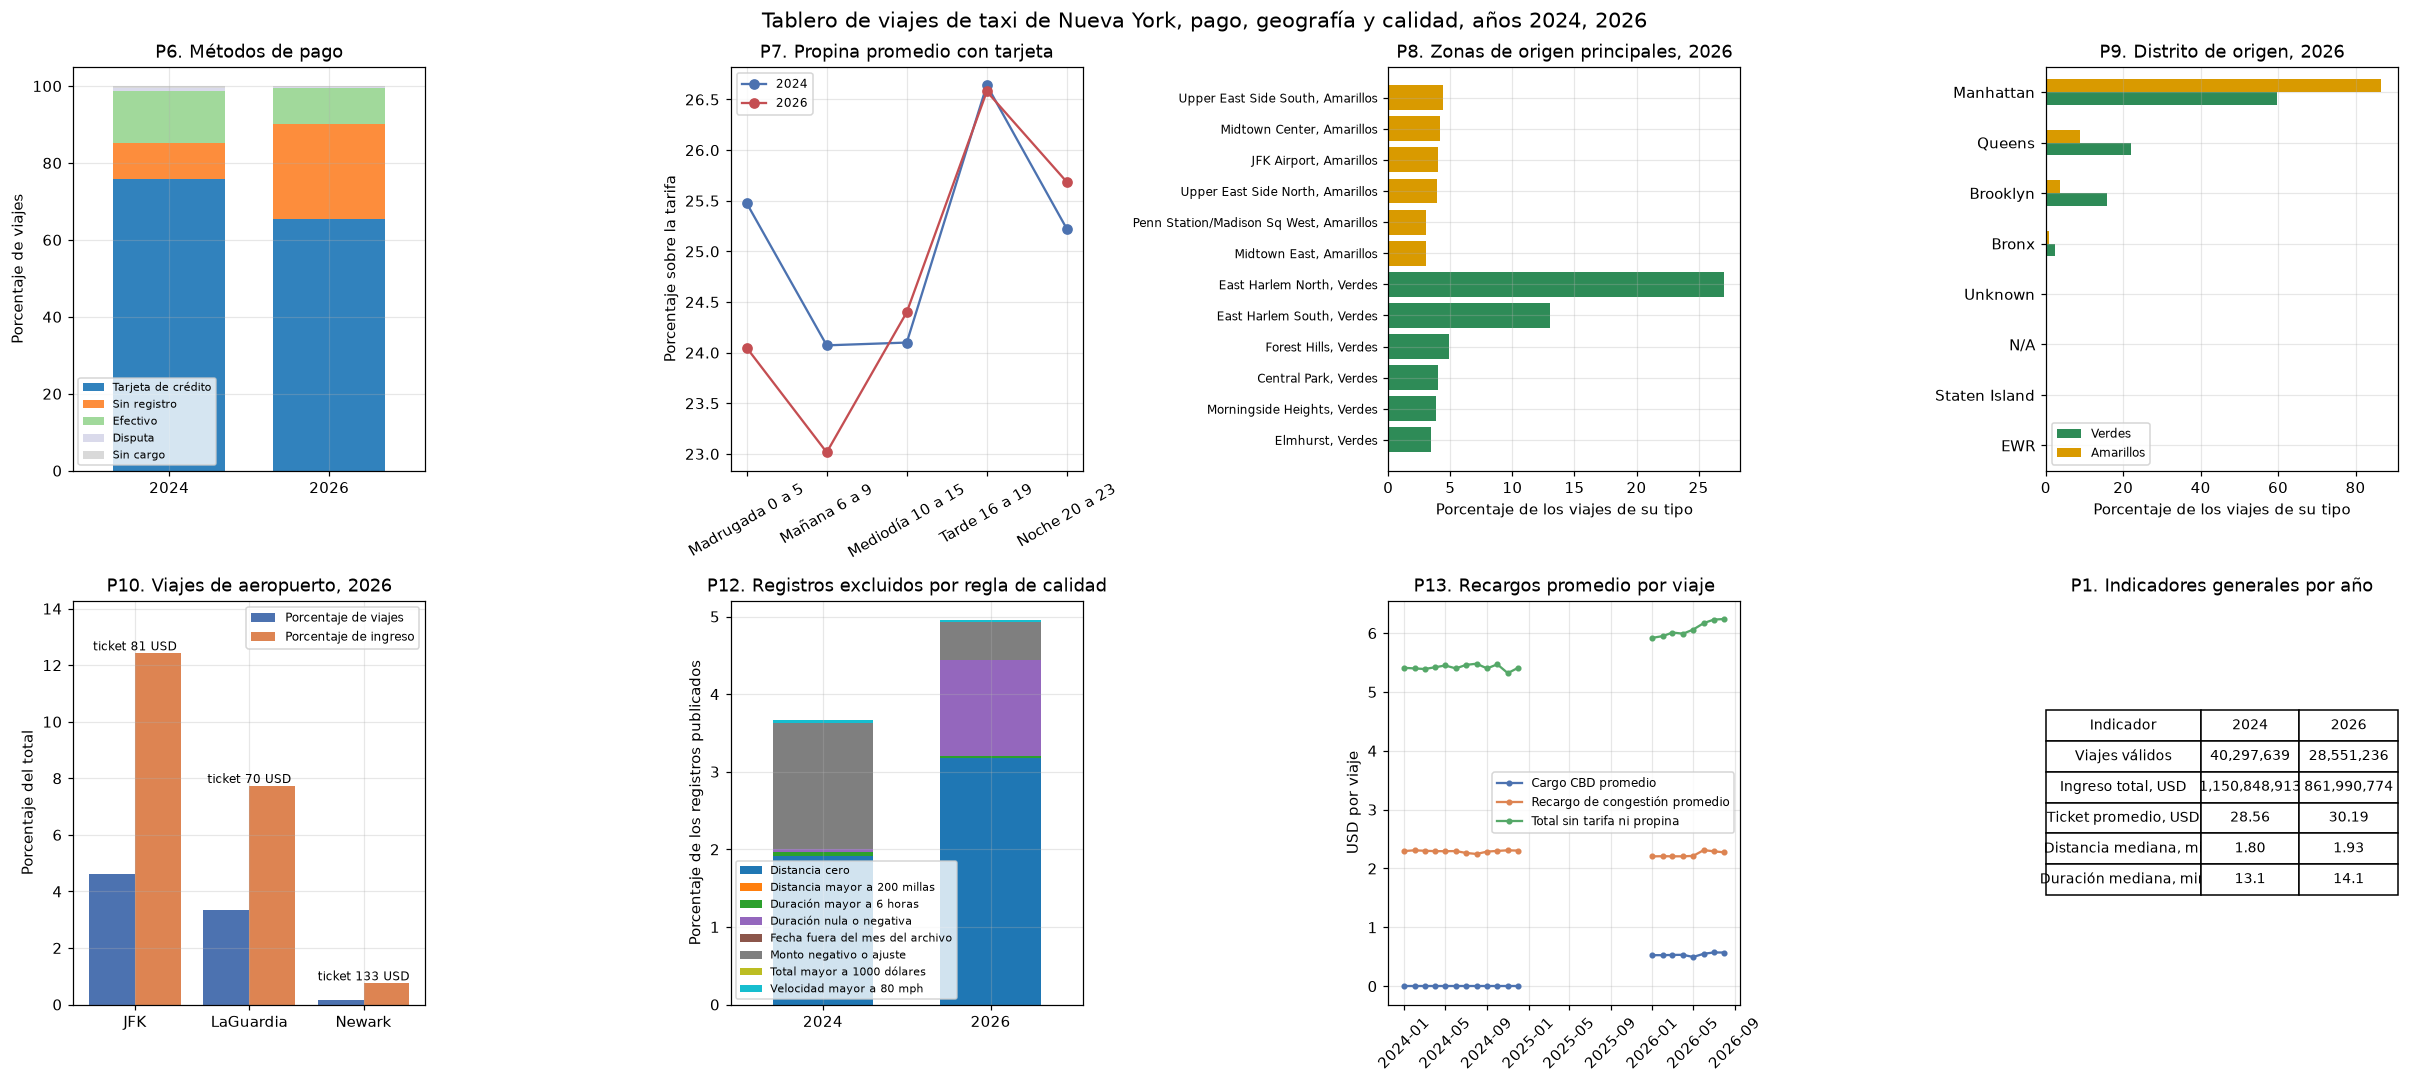

Figura 10. Tablero de indicadores, demanda, tiempos y participación por tipo de taxi, años 2024, 2026


Figura 11. Tablero de indicadores, pago, geografía, aeropuertos, calidad y recargos, años 2024, 2026


In [39]:
for figura, descripcion in graficos_tablero.dibujar_tablero(indicadores_e7):
    figura.savefig(DIR_TABLERO / f"tablero_estatico_e7_{len(indice_figuras) + 1}.png", dpi=130, bbox_inches="tight")
    guardar_figura(figura, descripcion)

### 7.4 – Tablero en Metabase

El tablero Viajes de Taxi de Nueva York se construyó en Metabase sobre la base data/processed/tablero.duckdb, conectada en modo de solo lectura con el nombre Taxis NY. Se organiza en tres secciones para analizar los indicadores en conjunto. La primera resume el servicio con los indicadores generales, los viajes por día, la participación de los taxis verdes y la serie mensual. La segunda reúne los patrones de tiempo: demanda por hora y tipo de día, velocidad por hora y viajes por día de la semana. La tercera reúne pago y geografía: métodos de pago, propina, zonas de origen de cada tipo de taxi, distritos, aeropuertos, calidad de datos y recargos. Un filtro de año conectado a la columna anio de todas las tablas permite comparar periodos.

La configuración de cada tarjeta, tipo de gráfico, ejes y filtros está en docs/tablero/guia_metabase.md. Como la exportación del tablero completo reduce la resolución de cada gráfico, se incluye además una captura de cada tarjeta en docs/tablero/e7.

In [40]:
# la documentacion de las consultas del Ejercicio 7 se exporta antes de incorporar 2025
bitacora.exportar(ARCHIVO_CONSULTAS)

PosixPath('/workspace/docs/consultas.md')

Capturas del tablero en Metabase con los datos de 2024 y 2026.

Tablero completo con 2024 y 2026.

![Tablero de Metabase con 2024 y 2026](../docs/tablero/tablero_metabase_2024_2026.png)

P1 Indicadores generales por año, 2024 y 2026.

![P1 Indicadores generales por año](../docs/tablero/e7/p01a_indicadores_generales.png)

P1 Viajes válidos por día, 2024 y 2026.

![P1 Viajes válidos por día](../docs/tablero/e7/p01b_viajes_por_dia.png)

P2 Tendencia mensual de viajes por día, 2024 y 2026.

![P2 Tendencia mensual de viajes por día](../docs/tablero/e7/p02_tendencia_mensual.png)

P3 Demanda por hora y tipo de día, 2024 y 2026.

![P3 Demanda por hora y tipo de día](../docs/tablero/e7/p03_demanda_hora.png)

P4 Velocidad mediana por hora, 2024 y 2026.

![P4 Velocidad mediana por hora](../docs/tablero/e7/p04_velocidad_hora.png)

P5 Viajes promedio por día de la semana, 2024 y 2026.

![P5 Viajes promedio por día de la semana](../docs/tablero/e7/p05_dia_semana.png)

P6 Participación de los métodos de pago, 2024 y 2026.

![P6 Participación de los métodos de pago](../docs/tablero/e7/p06_metodos_pago.png)

P7 Propina con tarjeta por franja horaria, 2024 y 2026.

![P7 Propina con tarjeta por franja horaria](../docs/tablero/e7/p07_propina.png)

P8a Zonas de origen de los taxis amarillos, 2024 y 2026.

![P8a Zonas de origen de los taxis amarillos](../docs/tablero/e7/p08a_zonas_amarillos.png)

P8b Zonas de origen de los taxis verdes, 2024 y 2026.

![P8b Zonas de origen de los taxis verdes](../docs/tablero/e7/p08b_zonas_verdes.png)

P9 Distritos de origen, 2024 y 2026.

![P9 Distritos de origen](../docs/tablero/e7/p09_distritos.png)

P10 Viajes e ingreso de aeropuerto, 2024 y 2026.

![P10 Viajes e ingreso de aeropuerto](../docs/tablero/e7/p10_aeropuertos.png)

P11 Participación por tipo de taxi, 2024 y 2026.

![P11 Participación por tipo de taxi](../docs/tablero/e7/p11_participacion_tipo.png)

P12 Registros excluidos por regla de calidad, 2024 y 2026.

![P12 Registros excluidos por regla de calidad](../docs/tablero/e7/p12_calidad_datos.png)

P13 Recargos promedio por mes, 2024 y 2026.

![P13 Recargos promedio por mes](../docs/tablero/e7/p13_recargos.png)

### 7.5 – Interpretación de los indicadores

El tablero con 2024 y 2026 permite leer los indicadores en conjunto.

- Volumen e ingreso, P1. En 2026 hay 117,495 viajes válidos por día frente a 110,103 en 2024, un 6.7 % más, y el ingreso por día crece 12.8 %, de 3.14 a 3.55 millones de dólares, porque el ticket promedio también sube, de 28.56 a 30.19 dólares. El viaje típico es un poco más largo, con mediana de 1.93 frente a 1.80 millas y de 14.1 frente a 13.1 minutos.
- Tendencia y estacionalidad, P2. Ambos años tienen la misma forma: meses bajos en enero y febrero y en julio y agosto, y un máximo en mayo. La diferencia entre años es mayor en los primeros meses.
- Tiempo, P3, P4 y P5. La demanda alcanza su máximo a las 18 horas y la velocidad mediana baja a cerca de 8 mph entre las 11 y las 17 horas en ambos años, con 2026 ligeramente más lento en esa franja. Jueves y sábado son los días con más viajes y lunes el de menos; 2026 supera a 2024 en todos los días de la semana.
- Pago y propina, P6 y P7. La tarjeta pasa del 75.9 % de los viajes en 2024 al 65.4 % en 2026 mientras los viajes sin registro de pago suben del 9.2 % al 24.8 % y el efectivo baja del 13.5 % al 9.2 %. La propina con tarjeta es estable: entre 23.5 % y 26.7 % en amarillos y entre 21 % y 24 % en verdes según la franja, con el máximo en la tarde de 16 a 19 horas.
- Geografía y aeropuertos, P8, P9 y P10. Cerca del 88 % de los viajes amarillos sale de Manhattan, frente a cerca del 60 % de los verdes, que tienen alrededor del 23 % en Queens y del 14 % en Brooklyn. Los aeropuertos suman cerca del 9 % de los viajes y cerca del 24 % del ingreso: JFK aporta alrededor del 5 % de los viajes y del 14 % del ingreso.
- Participación, calidad y recargos, P11, P12 y P13. Los taxis verdes bajan del 1.54 % al 1.13 % de los viajes. Los registros válidos pasan del 96.3 % al 95.0 %, con la distancia cero como principal exclusión en ambos años. El cargo de congestión CBD no existe en 2024 y en 2026 promedia cerca de 0.55 dólares por viaje, mientras el recargo de congestión general se mantiene cerca de 2.3 dólares.

En conjunto, el servicio de 2026 tiene más viajes, más caros y algo más largos que en 2024, con una participación decreciente de los taxis verdes y una proporción creciente de pagos sin registrar, que es una limitación de la fuente y no necesariamente un cambio en cómo pagan los pasajeros.

## Ejercicio 8 – Incorporación de 2025 y evolución de 2024 a 2026

Se incorpora 2025 con el mismo sistema, se comprueba que los archivos existentes no se descargan de nuevo y que todas las consultas siguen funcionando sobre los tres años, se reconstruyen los indicadores y se analiza su evolución. Las consultas de evolución están en sql/03_incorporacion.sql.

### 8.1 – Descarga de los datos de 2025

Los años por defecto del script son 2024, 2025 y 2026, por lo que basta con ejecutarlo sin parámetros. Solo deben descargarse los archivos de 2025 y los meses de 2026 que se hayan publicado desde la ejecución anterior.

In [41]:
salida_2025 = ejecutar_script(SCRIPT_DESCARGA)
print(SEPARADOR)
for concepto, cantidad in contar_descargas(salida_2025).items():
    print(f"{concepto:<24}{cantidad}")

Comando: python scripts/download_data.py


ZONAS DE TAXI
------------------------------------------------------------
  zonas  ya existe, se omite -> data/raw/zonas/taxi_zone_lookup.csv

YELLOW 2024
------------------------------------------------------------
  2024-01  ya existe, se omite
  2024-02  ya existe, se omite
  2024-03  ya existe, se omite
  2024-04  ya existe, se omite
  2024-05  ya existe, se omite
  2024-06  ya existe, se omite
  2024-07  ya existe, se omite
  2024-08  ya existe, se omite
  2024-09  ya existe, se omite
  2024-10  ya existe, se omite
  2024-11  ya existe, se omite
  2024-12  ya existe, se omite

GREEN 2024
------------------------------------------------------------
  2024-01  ya existe, se omite
  2024-02  ya existe, se omite
  2024-03  ya existe, se omite
  2024-04  ya existe, se omite
  2024-05  ya existe, se omite
  2024-06  ya existe, se omite
  2024-07  ya existe, se omite
  2024-08  ya existe, se omite
  2024-09  ya existe, se omite
  2024-10  ya existe, se omite
  2024-11  ya existe, se omi

  2025-01  descargando...


  2025-01  listo (56.4 MiB) -> data/raw/yellow/2025/yellow_tripdata_2025-01.parquet


  2025-02  descargando...


...

  2026-12  aun no publicado por la TLC

GREEN 2026
------------------------------------------------------------
  2026-01  ya existe, se omite
  2026-02  ya existe, se omite
  2026-03  ya existe, se omite
  2026-04  ya existe, se omite
  2026-05  ya existe, se omite
  2026-06  ya existe, se omite
  2026-07  ya existe, se omite
  2026-08  ya existe, se omite


  2026-09  aun no publicado por la TLC


  2026-10  aun no publicado por la TLC


  2026-11  aun no publicado por la TLC


  2026-12  aun no publicado por la TLC

RESUMEN
------------------------------------------------------------
  anios          : 2024, 2025, 2026
  zonas          : omitido
  descargados    : 24
  ya existian    : 40
  no publicados  : 8
      yellow 2026-09, yellow 2026-10, yellow 2026-11, yellow 2026-12, green 2026-09, green 2026-10, green 2026-11, green 2026-12
  errores de red : 0
  fallidos       : 0
------------------------------------------------------------
Codigo de salida: 0
------------------------------------------------------------
omitidos por existir    41
descargados             24
no publicados           8
errores de red          0


### 8.2 – Verificación de los archivos de los tres años

In [42]:
ejecutar_script(SCRIPT_DESCARGA, "--verificar")
manifiesto_e8, resumen_e8 = resumen_manifiesto()
display(resumen_e8)

Comando: python scripts/download_data.py --verificar



VERIFICACION DE COMPLETITUD
------------------------------------------------------------
  completo                         64
  no publicado                     8
  registros en archivos locales    121,184,384
  manifiesto -> data/processed/manifiesto_descargas.csv
------------------------------------------------------------
Codigo de salida: 0


,anio,tipo,diagnostico,meses,registros,mb_locales
0,2024,green,completo,12,660218,15.920
1,2024,yellow,completo,12,41169720,693.002
2,2025,green,completo,12,591375,14.460
3,2025,yellow,completo,12,48722602,829.973
4,2026,green,completo,8,337114,8.275
5,2026,green,no publicado,4,0,0.000
6,2026,yellow,completo,8,29703355,511.452
7,2026,yellow,no publicado,4,0,0.000


### 8.3 – Funcionamiento de las consultas sobre el conjunto ampliado

Se recrean las capas con todos los años descargados y se ejecutan de nuevo, sin cambios, las validaciones del Ejercicio 5 y las consultas del Ejercicio 4.

In [43]:
ANIOS_COMPLETOS = taxis.anios_disponibles()
parametros_e8 = parametros_fuentes(ANIOS_COMPLETOS)
fuentes_e8 = describir_fuentes(ANIOS_COMPLETOS)
taxis.preparar_capas(con, ANIOS_COMPLETOS, guardar=ARCHIVO_VISTA)
print(f"Años incorporados: {ANIOS_COMPLETOS}")
cobertura_e8 = bitacora.ejecutar("val_cobertura_anual", parametros_e8, "vista viajes sobre " + fuentes_e8, display, ejercicio="8")
conteo_e8 = bitacora.ejecutar("val_conteo_por_archivo", parametros_e8, fuentes_e8, display, ejercicio="8")
esquema_e8 = bitacora.ejecutar("val_esquema_por_anio", parametros_e8, fuentes_e8, display, ejercicio="8")

Años incorporados: [2024, 2025, 2026]


Consulta val_cobertura_anual en el ejercicio 8
  Objetivo: Verificar por año y tipo de taxi cuántos archivos, meses y registros cubre la vista conjunta y su rango de fechas.
  Fuentes : vista viajes sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2025/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2025/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 6 filas en 3.52 s


,anio,tipo_taxi,archivos,meses,registros,primera_recogida,ultima_recogida
0,2024,yellow,12,12,41169720,2024-01-01 00:00:00,2024-12-31 23:59:58
1,2024,green,12,12,660218,2024-01-01 00:03:57,2024-12-31 23:58:02
2,2025,yellow,12,12,48722602,2025-01-01 00:00:00,2025-12-31 23:59:59
3,2025,green,12,12,591375,2025-01-01 00:01:11,2025-12-31 23:59:09
4,2026,yellow,8,8,29703355,2026-01-01 00:00:00,2026-08-31 23:59:59
5,2026,green,8,8,337114,2026-01-01 00:03:27,2026-08-31 23:58:28


Consulta val_conteo_por_archivo en el ejercicio 8
  Objetivo: Comparar archivo por archivo los registros que lee la vista conjunta con los registros declarados en los metadatos Parquet.
  Fuentes : data/raw/yellow/2024/*.parquet, data/raw/yellow/2025/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2025/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 1 filas en 0.72 s


,archivos,registros_metadatos,registros_vista,archivos_con_diferencia
0,64,121184384,121184384,0


Consulta val_esquema_por_anio en el ejercicio 8
  Objetivo: Identificar columnas que existen solo en algunos años o cuyo tipo físico cambia de un año a otro.
  Fuentes : data/raw/yellow/2024/*.parquet, data/raw/yellow/2025/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2025/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 4 filas en 0.16 s


,tipo_taxi,columna,anios_presente,tipos_por_anio
0,yellow,cbd_congestion_fee,"2025, 2026","2025 DOUBLE, 2026 DOUBLE"
1,yellow,request_source,2026,2026 VARCHAR
2,green,cbd_congestion_fee,"2025, 2026","2025 DOUBLE, 2026 DOUBLE"
3,green,request_source,2026,2026 VARCHAR


In [44]:
funcionamiento = []
for id_consulta in CONSULTAS_E4:
    resultado = bitacora.ejecutar(id_consulta, fuentes="vistas sobre " + fuentes_e8, ejercicio="8")
    funcionamiento.append({"consulta": id_consulta, "filas": len(resultado), "segundos": bitacora.registros[-1]["segundos"]})
display(pd.DataFrame(funcionamiento))

Consulta e4_calidad_exclusiones en el ejercicio 8
  Objetivo: Pregunta 1. Qué proporción de registros incumple alguna regla de calidad y por qué motivo, en cada tipo de taxi.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2025/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2025/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 18 filas en 11.40 s


Consulta e4_viajes_mensuales en el ejercicio 8
  Objetivo: Pregunta 2. Cómo evoluciona el número de viajes y el ingreso de cada mes por tipo de taxi.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2025/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2025/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 64 filas en 17.34 s


Consulta e4_patron_horario en el ejercicio 8
  Objetivo: Pregunta 3. En qué horas y tipo de día se concentra la demanda y cómo cambia la velocidad del tráfico.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2025/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2025/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 48 filas en 22.27 s


Consulta e4_caracteristicas_tipo en el ejercicio 8
  Objetivo: Pregunta 4. En qué se diferencian los viajes de taxis amarillos y verdes en distancia, duración, pasajeros y monto.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2025/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2025/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 2 filas en 68.58 s


Consulta e4_distribucion_distancia en el ejercicio 8
  Objetivo: Pregunta 5. Cómo se distribuyen las distancias de los viajes en intervalos de una milla por tipo de taxi.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2025/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2025/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 62 filas en 20.06 s


Consulta e4_pago_propina en el ejercicio 8
  Objetivo: Pregunta 6. Cómo se reparten los métodos de pago y qué porcentaje de propina se registra en cada uno.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2025/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2025/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 10 filas en 23.77 s


Consulta e4_zonas_origen en el ejercicio 8
  Objetivo: Pregunta 7. Desde qué zonas y distritos sale la mayor parte de los viajes de cada tipo de taxi.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2025/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2025/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 20 filas en 18.11 s


Consulta e4_aeropuertos en el ejercicio 8
  Objetivo: Pregunta 8. Cuánto pesan los viajes de aeropuerto y en qué se diferencian del resto.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2025/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2025/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 8 filas en 30.31 s


Consulta e4_atipicos_tarifa en el ejercicio 8
  Objetivo: Pregunta 9. Qué viajes válidos tienen una tarifa por milla atípica según el criterio de rango intercuartílico.
  Fuentes : vistas sobre data/raw/yellow/2024/*.parquet, data/raw/yellow/2025/*.parquet, data/raw/yellow/2026/*.parquet, data/raw/green/2024/*.parquet, data/raw/green/2025/*.parquet, data/raw/green/2026/*.parquet
  Resultado: 2 filas en 38.56 s


,consulta,filas,segundos
0,e4_calidad_exclusiones,18,11.398
1,e4_viajes_mensuales,64,17.335
2,e4_patron_horario,48,22.270
3,e4_caracteristicas_tipo,2,68.581
4,e4_distribucion_distancia,62,20.062
5,e4_pago_propina,10,23.769
6,e4_zonas_origen,20,18.114
7,e4_aeropuertos,8,30.310
8,e4_atipicos_tarifa,2,38.562


### 8.4 – Actualización de los indicadores y del tablero

Se reconstruye la base del tablero con los tres años. Las consultas de los indicadores no cambian; Metabase muestra los nuevos datos al reiniciarse y sincronizar el esquema, porque las tablas conservan sus nombres y columnas. Las tarjetas del tablero no se modificaron: con el filtro de año vacío muestran los tres años y cada serie incorpora 2025 automáticamente. Las capturas del tablero actualizado se guardan en docs/tablero/e8.

ind_01_resumen_anual: 3 filas


ind_02_tendencia_mensual: 64 filas


ind_03_demanda_horaria: 144 filas


ind_04_velocidad_horaria: 72 filas


ind_05_dia_semana: 21 filas


...

ind_10_aeropuertos: 12 filas


ind_11_participacion_tipo: 6 filas


ind_12_calidad_datos: 52 filas


ind_13_cargos_mensuales: 32 filas


,indicador,pregunta,filas,segundos
0,ind_01_resumen_anual,P1. ¿Cuántos viajes válidos e ingresos genera el servicio de taxis cada año y cuál es el monto promedio por viaje?,3,25.412
1,ind_02_tendencia_mensual,P2. ¿Cómo evoluciona mes a mes la demanda de taxis amarillos y verdes?,64,20.333
2,ind_03_demanda_horaria,P3. ¿En qué horas del día se concentra la demanda y cómo cambia entre semana y fin de semana?,144,19.013
3,ind_04_velocidad_horaria,P4. ¿En qué horas el tráfico hace más lentos los viajes?,72,22.285
4,ind_05_dia_semana,P5. ¿Qué días de la semana tienen más viajes y viajes más caros?,21,25.560
5,ind_06_metodo_pago,P6. ¿Cómo pagan los pasajeros y cómo cambia la participación de cada método entre años?,30,19.387
6,ind_07_propina,P7. ¿Qué porcentaje de propina dejan los pasajeros que pagan con tarjeta y cómo varía por franja horaria y tipo de t...,30,17.409
7,ind_08_zonas_origen,P8. ¿Desde qué zonas sale la mayor cantidad de viajes de cada tipo de taxi?,90,19.708
8,ind_09_distritos,P9. ¿Cómo se reparten los viajes y el ingreso entre los distritos de la ciudad?,47,18.668
9,ind_10_aeropuertos,P10. ¿Qué peso tienen los viajes hacia o desde aeropuertos y cuánto más cuestan que un viaje urbano?,12,19.662


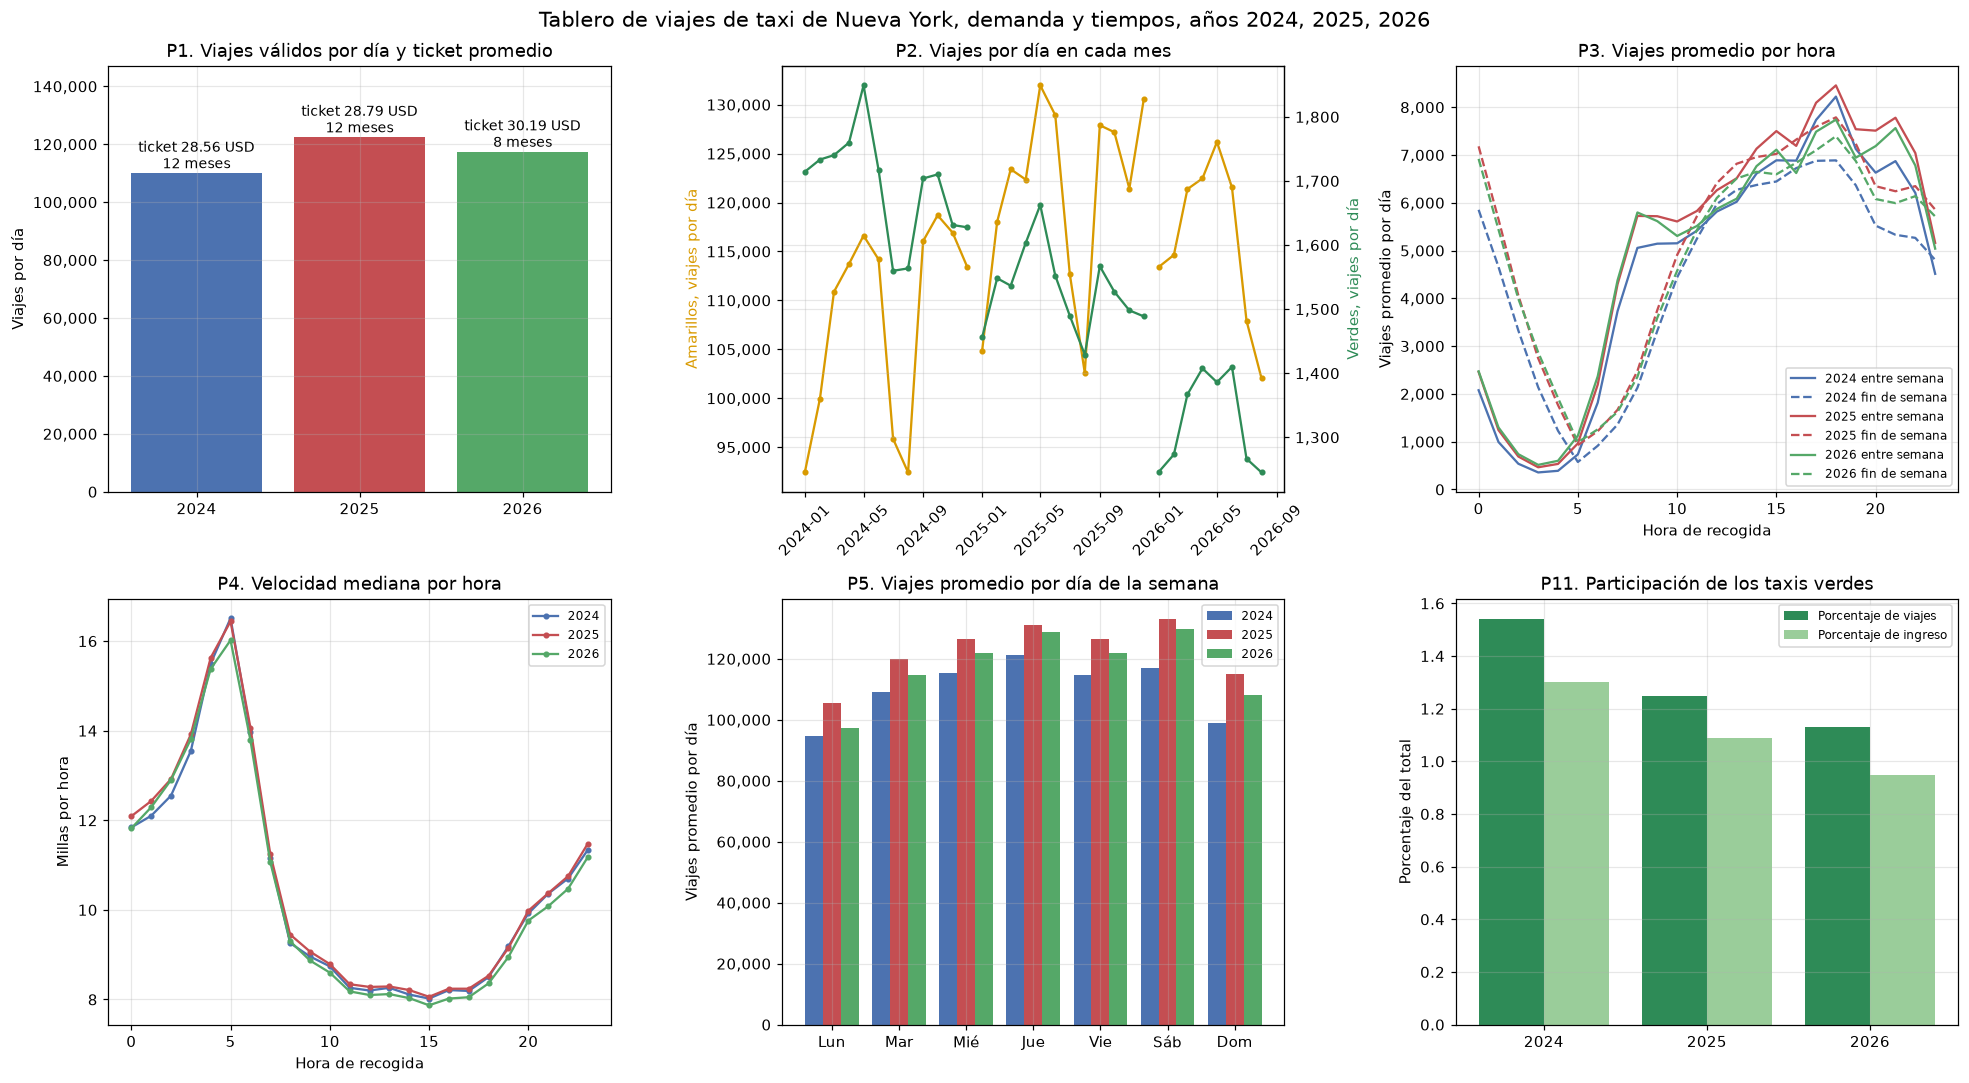

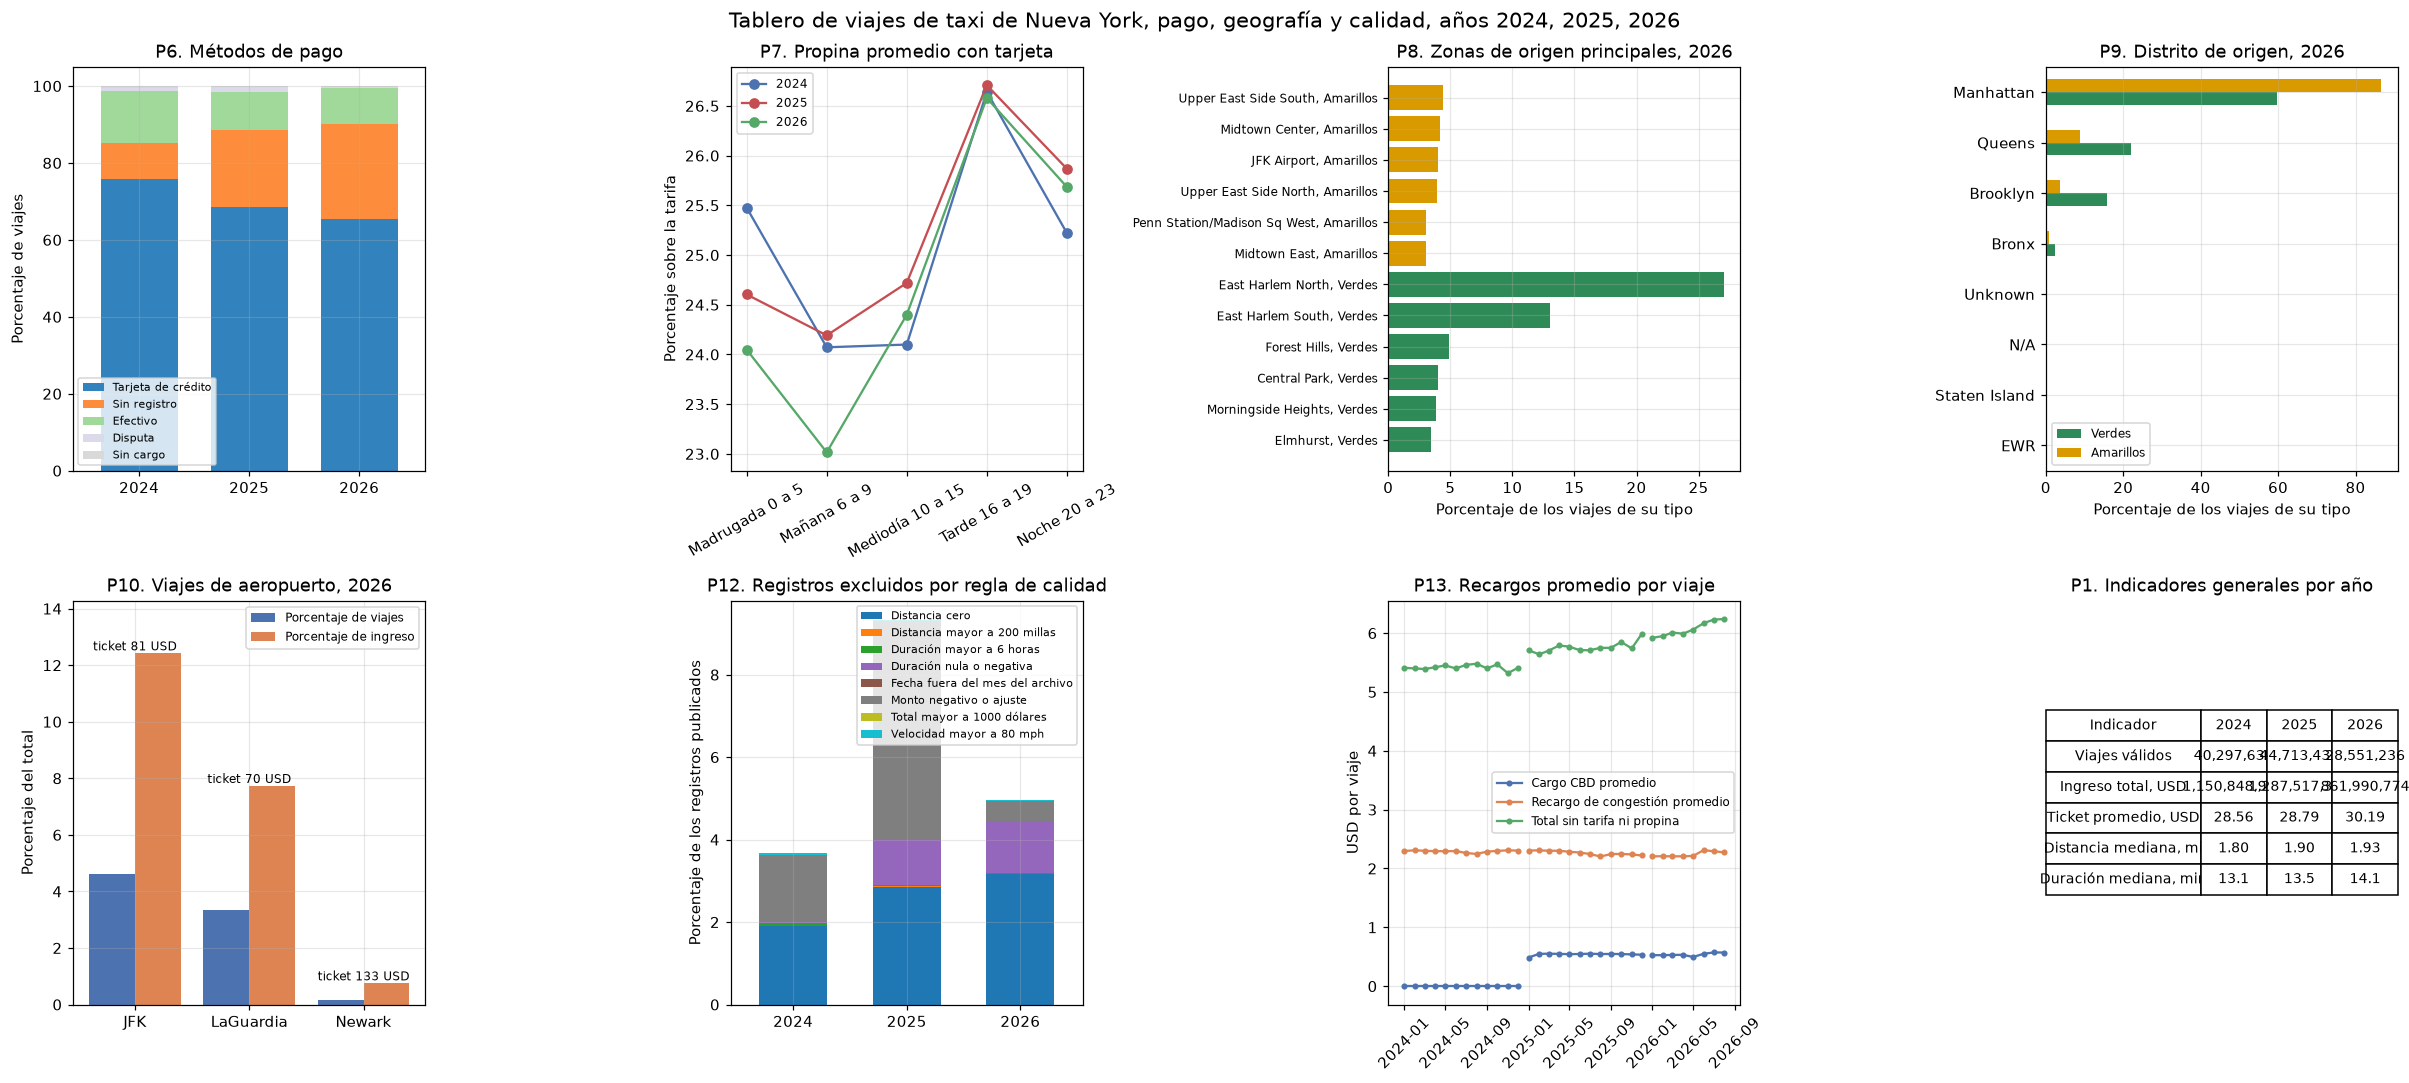

Figura 12. Tablero de indicadores, demanda, tiempos y participación por tipo de taxi, años 2024, 2025, 2026


Figura 13. Tablero de indicadores, pago, geografía, aeropuertos, calidad y recargos, años 2024, 2025, 2026


In [45]:
try:
    construccion_e8 = taxis.construir_tablero(ANIOS_COMPLETOS)
except PermissionError as error:
    construccion_e8 = None
    print(error)
if construccion_e8 is not None:
    construccion_e8.to_csv(DIR_TABLERO / "indicadores.csv", index=False)
    display(construccion_e8)
indicadores_e8 = graficos_tablero.leer_indicadores()
for fila in construccion_e8.itertuples() if construccion_e8 is not None else []:
    bitacora.documentar(fila.indicador, indicadores_e8[fila.indicador], fila.segundos, ejercicio="8",
                        fuentes="vista viajes_validos sobre " + fuentes_e8)
for figura, descripcion in graficos_tablero.dibujar_tablero(indicadores_e8):
    figura.savefig(DIR_TABLERO / f"tablero_estatico_e8_{len(indice_figuras) + 1}.png", dpi=130, bbox_inches="tight")
    guardar_figura(figura, descripcion)

Capturas del tablero en Metabase actualizado con los datos de 2024, 2025 y 2026.

Tablero completo con 2024, 2025 y 2026.

![Tablero de Metabase con 2024, 2025 y 2026](../docs/tablero/tablero_metabase_2024_2025_2026.png)

P1 Indicadores generales por año, 2024, 2025 y 2026.

![P1 Indicadores generales por año](../docs/tablero/e8/p01a_indicadores_generales.png)

P1 Viajes válidos por día, 2024, 2025 y 2026.

![P1 Viajes válidos por día](../docs/tablero/e8/p01b_viajes_por_dia.png)

P2 Tendencia mensual de viajes por día, 2024, 2025 y 2026.

![P2 Tendencia mensual de viajes por día](../docs/tablero/e8/p02_tendencia_mensual.png)

P3 Demanda por hora y tipo de día, 2024, 2025 y 2026.

![P3 Demanda por hora y tipo de día](../docs/tablero/e8/p03_demanda_hora.png)

P4 Velocidad mediana por hora, 2024, 2025 y 2026.

![P4 Velocidad mediana por hora](../docs/tablero/e8/p04_velocidad_hora.png)

P5 Viajes promedio por día de la semana, 2024, 2025 y 2026.

![P5 Viajes promedio por día de la semana](../docs/tablero/e8/p05_dia_semana.png)

P6 Participación de los métodos de pago, 2024, 2025 y 2026.

![P6 Participación de los métodos de pago](../docs/tablero/e8/p06_metodos_pago.png)

P7 Propina con tarjeta por franja horaria, 2024, 2025 y 2026.

![P7 Propina con tarjeta por franja horaria](../docs/tablero/e8/p07_propina.png)

P8a Zonas de origen de los taxis amarillos, 2024, 2025 y 2026.

![P8a Zonas de origen de los taxis amarillos](../docs/tablero/e8/p08a_zonas_amarillos.png)

P8b Zonas de origen de los taxis verdes, 2024, 2025 y 2026.

![P8b Zonas de origen de los taxis verdes](../docs/tablero/e8/p08b_zonas_verdes.png)

P9 Distritos de origen, 2024, 2025 y 2026.

![P9 Distritos de origen](../docs/tablero/e8/p09_distritos.png)

P10 Viajes e ingreso de aeropuerto, 2024, 2025 y 2026.

![P10 Viajes e ingreso de aeropuerto](../docs/tablero/e8/p10_aeropuertos.png)

P11 Participación por tipo de taxi, 2024, 2025 y 2026.

![P11 Participación por tipo de taxi](../docs/tablero/e8/p11_participacion_tipo.png)

P12 Registros excluidos por regla de calidad, 2024, 2025 y 2026.

![P12 Registros excluidos por regla de calidad](../docs/tablero/e8/p12_calidad_datos.png)

P13 Recargos promedio por mes, 2024, 2025 y 2026.

![P13 Recargos promedio por mes](../docs/tablero/e8/p13_recargos.png)

### 8.5 – Evolución de los indicadores

Se comparan los tres años en volumen, montos, tiempos, pago, recargos, calidad de los registros y perfil horario. Como 2026 no está completo, el volumen se compara en viajes por día y el resto en promedios, medianas o participaciones.

In [46]:
evolucion = bitacora.ejecutar("e8_evolucion_anual", mostrar=display)
variacion = evolucion.set_index("anio")[["viajes_por_dia", "ingreso_por_dia", "total_promedio", "distancia_mediana",
                                         "duracion_mediana", "velocidad_mediana", "propina_pct_tarjeta", "pct_verdes"]]
print("Variación porcentual respecto del año anterior")
display(100 * variacion.pct_change().dropna(how="all"))

Consulta e8_evolucion_anual
  Objetivo: Comparar entre años los indicadores principales de volumen, monto, distancia, duración, velocidad y propina.
  Fuentes : vista viajes_validos sobre 2024, 2025 y 2026
  Resultado: 3 filas en 30.66 s


,anio,meses,viajes,viajes_por_dia,ingreso_por_dia,total_promedio,tarifa_promedio,distancia_mediana,duracion_mediana,velocidad_mediana,propina_pct_tarjeta,pct_verdes
0,2024,12,40297639,"110,103.000","3,144,396.000",28.560,19.770,1.800,13.070,9.300,25.120,1.540
1,2025,12,44713431,"122,503.000","3,527,445.000",28.790,19.990,1.900,13.520,9.450,25.430,1.250
2,2026,8,28551236,"117,495.000","3,547,287.000",30.190,21.240,1.930,14.100,9.290,25.070,1.130


Variación porcentual respecto del año anterior


,viajes_por_dia,ingreso_por_dia,total_promedio,distancia_mediana,duracion_mediana,velocidad_mediana,propina_pct_tarjeta,pct_verdes
anio,,,,,,,,
2025,11.262,12.182,0.805,5.556,3.443,1.613,1.234,-18.831
2026,-4.088,0.563,4.863,1.579,4.290,-1.693,-1.416,-9.600


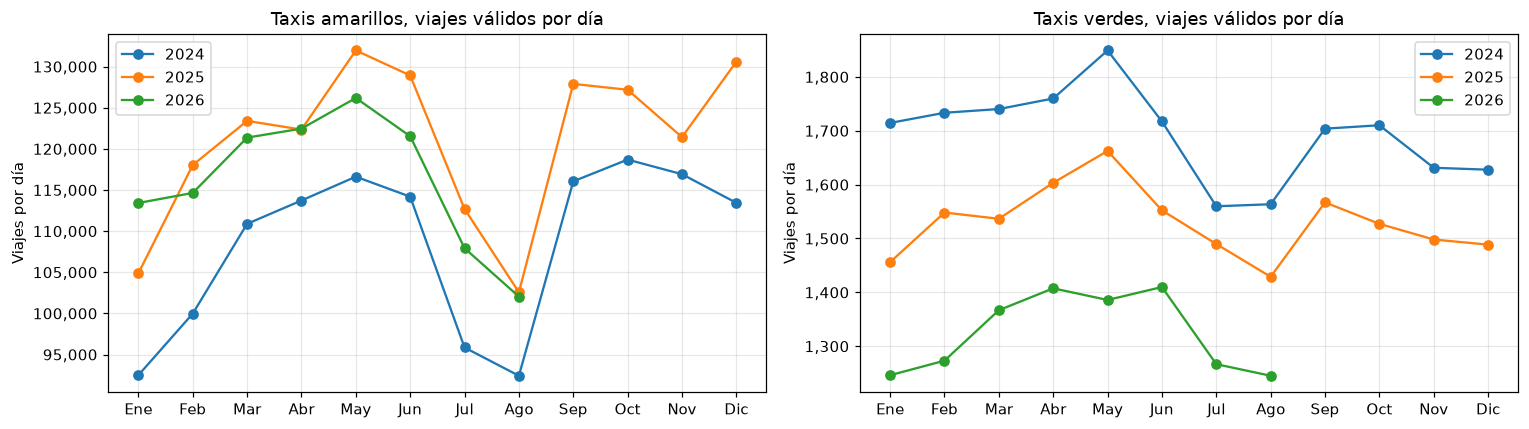

Figura 14. Viajes válidos por día en cada mes, comparación de 2024, 2025 y 2026 por tipo de taxi


In [47]:
serie = indicadores_e8["ind_02_tendencia_mensual"]
figura, ejes = plt.subplots(1, 2, figsize=(14, 4))
for eje, tipo in zip(ejes, ("yellow", "green")):
    datos = serie[serie["tipo_taxi"] == tipo]
    for anio in ANIOS_COMPLETOS:
        tramo = datos[datos["anio"] == anio]
        eje.plot(tramo["mes"], tramo["viajes_por_dia"], marker="o", label=str(anio))
    eje.set_xticks(range(1, 13), MESES)
    eje.set_title(f"Taxis {NOMBRES_TIPO[tipo].lower()}, viajes válidos por día")
    eje.set_ylabel("Viajes por día")
    eje.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
    eje.legend()
figura.tight_layout()
guardar_figura(figura, "Viajes válidos por día en cada mes, comparación de 2024, 2025 y 2026 por tipo de taxi")

Consulta e8_pago_por_anio
  Objetivo: Analizar cómo cambia la participación de cada método de pago entre años.
  Fuentes : vista viajes_validos sobre 2024, 2025 y 2026
  Resultado: 15 filas en 17.93 s


,anio,metodo_pago,viajes,porcentaje
0,2024,Tarjeta de crédito,30590725,75.910
1,2024,Efectivo,5445121,13.510
2,2024,Sin registro,3718387,9.230
3,2024,Disputa,386779,0.960
4,2024,Sin cargo,156627,0.390
5,2025,Tarjeta de crédito,30708717,68.680
6,2025,Sin registro,8890811,19.880
7,2025,Efectivo,4418801,9.880
8,2025,Disputa,533326,1.190
9,2025,Sin cargo,161776,0.360


Consulta e8_cargos_por_anio
  Objetivo: Medir la presencia y el monto promedio de cada recargo por año, incluido el cargo de congestión CBD.
  Fuentes : vista viajes_validos sobre 2024, 2025 y 2026
  Resultado: 6 filas en 17.90 s


,anio,tipo_taxi,pct_con_cargo_cbd,cargo_cbd_promedio,recargo_congestion_promedio,cargo_aeropuerto_promedio,cargos_no_tarifa_promedio,total_promedio
0,2024,yellow,0.000,NaN,2.317,0.154,5.450,28.630
1,2024,green,0.000,NaN,0.856,NaN,3.410,24.100
2,2025,yellow,73.030,0.548,2.285,0.154,5.780,28.840
3,2025,green,9.620,0.073,0.913,NaN,4.540,25.140
4,2026,yellow,72.390,0.543,2.256,0.168,6.070,30.250
5,2026,green,8.500,0.064,0.915,NaN,6.040,25.380


Consulta e8_calidad_por_anio
  Objetivo: Comparar entre años la proporción de registros excluidos por cada regla de calidad.
  Fuentes : vista viajes_calidad sobre 2024, 2025 y 2026
  Resultado: 27 filas en 12.40 s


,anio,clasificacion,registros,porcentaje
0,2024,Válido,40297639,96.337
1,2024,Distancia cero,798755,1.910
2,2024,Monto negativo o ajuste,678700,1.623
3,2024,Duración mayor a 6 horas,24621,0.059
4,2024,Duración nula o negativa,14170,0.034
5,2024,Velocidad mayor a 80 mph,14101,0.034
6,2024,Distancia mayor a 200 millas,1352,0.003
7,2024,Fecha fuera del mes del archivo,584,0.001
8,2024,Total mayor a 1000 dólares,16,0.000
9,2025,Válido,44713431,90.671


Consulta e8_hora_por_anio
  Objetivo: Comparar el perfil horario de la demanda y la velocidad entre años.
  Fuentes : vista viajes_validos sobre 2024, 2025 y 2026
  Resultado: 72 filas en 18.96 s


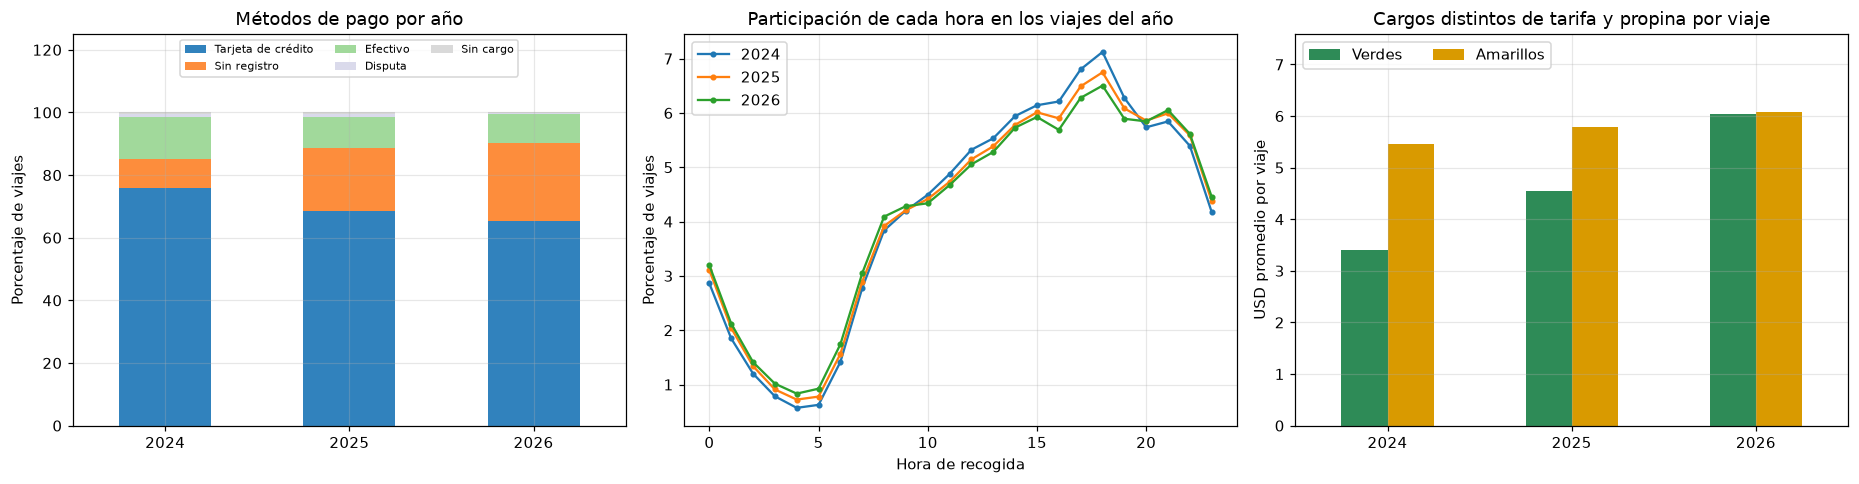

Figura 15. Evolución de métodos de pago, perfil horario y recargos por viaje entre 2024 y 2026
Consultas documentadas: 86


In [48]:
pago_anual = bitacora.ejecutar("e8_pago_por_anio", mostrar=display, filas=20)
cargos_anual = bitacora.ejecutar("e8_cargos_por_anio", mostrar=display)
calidad_anual = bitacora.ejecutar("e8_calidad_por_anio", mostrar=display, filas=30)
hora_anual = bitacora.ejecutar("e8_hora_por_anio", mostrar=None, filas=72)

figura, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
tabla = pago_anual.pivot(index="anio", columns="metodo_pago", values="porcentaje").fillna(0)
tabla.index = tabla.index.astype(str)
tabla[tabla.sum().sort_values(ascending=False).index].plot(kind="bar", stacked=True, ax=ejes[0], colormap="tab20c", rot=0)
ejes[0].set_title("Métodos de pago por año")
ejes[0].set_ylabel("Porcentaje de viajes")
ejes[0].set_ylim(0, 125)
ejes[0].legend(fontsize=7, loc="upper center", ncols=3)
for anio in ANIOS_COMPLETOS:
    datos = hora_anual[hora_anual["anio"] == anio]
    ejes[1].plot(datos["hora"], datos["pct_viajes"], marker="o", ms=3, label=str(anio))
ejes[1].set_title("Participación de cada hora en los viajes del año")
ejes[1].set_xlabel("Hora de recogida")
ejes[1].set_ylabel("Porcentaje de viajes")
ejes[1].legend()
tabla = cargos_anual.pivot(index="anio", columns="tipo_taxi", values="cargos_no_tarifa_promedio")[["green", "yellow"]]
tabla.index = tabla.index.astype(str)
tabla.rename(columns=NOMBRES_TIPO).plot(kind="bar", ax=ejes[2], color=[VERDE, AMARILLO], rot=0)
ejes[2].set_title("Cargos distintos de tarifa y propina por viaje")
ejes[2].margins(y=0.25)
ejes[2].legend(loc="upper left", ncols=2)
ejes[2].set_ylabel("USD promedio por viaje")
figura.tight_layout()
guardar_figura(figura, "Evolución de métodos de pago, perfil horario y recargos por viaje entre 2024 y 2026")
bitacora.exportar(ARCHIVO_CONSULTAS)
print(f"Consultas documentadas: {len(bitacora.registros)}")

### 8.6 – Cambios y patrones identificados

Con los tres años se identifican los siguientes cambios y patrones.

1. La demanda creció en 2025 y se estabilizó en 2026. Los viajes válidos por día pasaron de 110,103 en 2024 a 122,503 en 2025, un 11.3 % más, y a 117,495 en los ocho meses de 2026. La caída de 4.1 % de 2026 está sesgada porque faltan septiembre a diciembre, que en 2025 fueron meses altos; comparando mes a mes en la Figura 14, 2026 supera a 2025 en enero y queda ligeramente por debajo en la mayoría de los meses siguientes. La estacionalidad se repite en los tres años, con caídas en enero y en julio y agosto y máximos en mayo y en los últimos meses del año.
2. Cada viaje es más caro. El total promedio sube de 28.56 a 28.79 y a 30.19 dólares, y la tarifa promedio de 19.77 a 19.99 y a 21.24. Los cargos distintos de tarifa y propina también crecen, de 5.45 a 6.07 dólares por viaje en los amarillos y de 3.41 a 6.04 en los verdes. Desde 2025 aparece el cargo de congestión CBD, presente en el 73 % de los viajes amarillos con un promedio de 0.55 dólares y en menos del 10 % de los verdes, mientras el recargo de congestión general se mantiene cerca de 2.3 dólares en los amarillos.
3. Los viajes son más largos pero no más lentos. La duración mediana pasa de 13.07 a 14.10 minutos y la distancia mediana de 1.80 a 1.93 millas, ambas cerca de 8 % más, mientras la velocidad mediana se mantiene entre 9.29 y 9.45 mph. El perfil horario de la Figura 15 se aplana: la hora de las 18 pasa de concentrar el 7.1 % de los viajes del año en 2024 a cerca del 6.5 % en 2026 y ganan peso las horas de la madrugada.
4. El registro del pago se deteriora. La tarjeta baja del 75.9 % al 68.7 % y al 65.4 %, el efectivo del 13.5 % al 9.2 % y los viajes sin método de pago suben del 9.2 % al 19.9 % y al 24.8 %. Como la propina con tarjeta se mantiene estable, entre 25.07 % y 25.43 %, el cambio parece un problema creciente de captura en la fuente más que un cambio de comportamiento de los pasajeros.
5. Los taxis verdes pierden participación. Pasan del 1.54 % de los viajes válidos en 2024 al 1.25 % en 2025 y al 1.13 % en 2026, y la Figura 14 muestra menos viajes por día en cada mes de cada año, mientras los amarillos crecen.
6. La calidad varía de un año a otro. 2025 es el año con más exclusiones: solo el 90.67 % de los registros es válido, con 5.29 % de montos negativos o ajustes y 1.11 % de duraciones nulas o negativas, frente a 1.62 % y 0.03 % en 2024. En 2026 la proporción válida vuelve a 95.04 %, pero la distancia cero crece de 1.91 % a 2.86 % y a 3.17 %. Estos cambios hacen necesario recalcular las reglas de calidad cada vez que se incorporan datos y no asumir que la proporción excluida es constante.

## Ejercicio 9 – Discusión

Las respuestas se basan en el trabajo realizado en los ejercicios anteriores.

### 9.1 – Características de DuckDB más útiles

La característica más útil fue consultar Parquet directamente con read_parquet y patrones glob, porque permitió explorar millones de registros sin importarlos y que los archivos nuevos quedaran disponibles con solo descargarlos. La opción union_by_name resolvió las diferencias de esquema entre archivos y tipos de taxi, y las funciones parquet_file_metadata y parquet_schema permitieron contar registros y revisar esquemas leyendo solo los metadatos. SUMMARIZE dio un perfil completo de cada columna en una sola instrucción y DESCRIBE el esquema inferido. Del lado del SQL fueron muy útiles GROUP BY ALL, las agregaciones con FILTER, las medianas y percentiles exactos, el muestreo reproducible con USING SAMPLE y UNION ALL BY NAME. Finalmente, al ser un motor embebido, la misma biblioteca sirvió para el notebook, los scripts de benchmark y la base que lee Metabase, con un límite de memoria y desborde a disco que evitaron fallos por memoria.

### 9.2 – Ventajas y limitaciones de consultar directamente archivos Parquet

Las ventajas son que no hay paso de carga ni copia de los datos, que cada consulta lee solo las columnas que necesita y aprovecha las estadísticas del archivo, que los datos nuevos se incorporan con solo agregarlos a la carpeta y que los mismos archivos pueden ser usados por otras herramientas. En este laboratorio los 64 archivos ocupan 2,073 MB y se consultaron desde el primer momento, y preguntas como el número de registros se respondieron solo con metadatos en fracciones de segundo.

Las limitaciones son que cada consulta vuelve a leer, descomprimir y convertir los archivos, por lo que los análisis repetidos pagan ese costo una y otra vez: con todos los meses del benchmark las seis consultas tardaron 41.8 s sobre Parquet frente a 19.1 s sobre la tabla, y el filtro selectivo fue hasta 12.7 veces más lento. Además, el esquema puede variar entre archivos y hay que resolverlo en cada lectura, las transformaciones definidas en una vista se recalculan siempre y una herramienta externa como Metabase necesita una base estable con tablas y no un conjunto de archivos que cambia.

### 9.3 – Ventajas y limitaciones de las tablas materializadas en DuckDB

La tabla materializada guarda los datos ya normalizados en el formato interno de DuckDB, por lo que las consultas no repiten la lectura de Parquet ni las conversiones de la vista. En el benchmark fue más rápida en todas las consultas y volúmenes, con cocientes de 2.5 a 3.4 en agregaciones y uniones y de 6.4 a 12.7 en el filtro selectivo. También ofrece un esquema estable que herramientas externas pueden abrir, como la base de indicadores que lee Metabase.

Las limitaciones son el tiempo de creación, 93.1 s para los 71.9 millones de registros; el espacio adicional, 2,584 MB frente a 1,229 MB de los Parquet de origen; que la ventaja casi desaparece en consultas dominadas por cálculo, como los percentiles, con cocientes de 1.0 a 1.4; que la tabla queda desactualizada en cuanto llegan archivos nuevos y debe reconstruirse; y que un archivo DuckDB admite un solo proceso con escritura, lo que obligó a detener Metabase al reconstruir la base del tablero.

### 9.4 – Ventajas frente a cargar todos los datos con Pandas

Pandas necesita cargar en memoria todas las filas y columnas antes de calcular, y los tres años de viajes ocupan varias veces la memoria de un equipo personal una vez descomprimidos. Con DuckDB solo el resultado de cada consulta llega a Pandas, que en este laboratorio son tablas de decenas o cientos de filas, mientras que el cálculo se ejecuta en paralelo, con lectura selectiva de columnas y desborde a disco cuando una operación lo necesita. Además, las consultas quedan escritas en SQL versionado, se pueden reutilizar desde scripts, el notebook y el tablero, y se documentan con su objetivo y fuentes, lo que hace el análisis más reproducible que una cadena de transformaciones en memoria.

### 9.5 – Características que permiten incorporar nuevos datos con cambios mínimos

El script de descarga es incremental, recibe los años como parámetro y verifica la completitud. Los archivos se guardan en carpetas por tipo y año y las consultas usan patrones glob por carpeta. La vista normalizada se genera desde el esquema real de los archivos y absorbe columnas nuevas o con otro tipo. Todo el análisis consulta vistas y no archivos, y el periodo de cada registro sale del nombre del archivo. Los indicadores incluyen el año en todas sus tablas y la base del tablero se reconstruye con un comando. Gracias a esto, incorporar 2024 y 2025 consistió en ejecutar el script con otros años y volver a crear las capas, sin modificar ninguna consulta.

### 9.6 – Partes que deberían automatizarse en producción

En producción debería automatizarse la ejecución periódica de la descarga, por ejemplo mensual, con la verificación de completitud como condición para continuar y alertas cuando el código de salida indique errores o archivos con tamaño distinto. También la validación de esquema de cada archivo nuevo antes de incorporarlo, el cálculo de las reglas de calidad con umbrales de alerta si la proporción de registros excluidos cambia bruscamente, la reconstrucción de la base de indicadores con un intercambio atómico que no requiera detener el tablero, la exportación de la documentación de consultas y un registro de cada ejecución con los archivos procesados.

### 9.7 – Decisiones de diseño importantes para la reproducibilidad

Las decisiones clave fueron usar Docker Compose con versiones exactas de Python, paquetes, Metabase y su controlador; excluir los datos de Git y versionar en su lugar el script que los obtiene desde la fuente original; calcular las rutas desde la ubicación de cada script y definirlas una sola vez en el notebook; mantener el SQL en archivos versionados con metadatos que documentan objetivo, fuentes y decisión; aplicar las reglas de calidad como etiquetas en una vista en lugar de modificar los archivos; usar semillas fijas en los muestreos; separar las bases generadas, benchmark.duckdb y tablero.duckdb, que pueden borrarse y reconstruirse; y generar automáticamente la documentación, las figuras numeradas y los resultados del benchmark en cada ejecución.

### 9.8 – Aprendizajes que no serían evidentes con conjuntos de datos pequeños

Con datos pequeños casi cualquier herramienta responde al instante y la estrategia de acceso no importa. Con decenas de millones de registros la forma de almacenar y leer los datos determina si el análisis es posible: el formato columnar, la lectura selectiva de columnas y la decisión entre consultar archivos o materializar tablas cambian los tiempos de forma medible. También se hacen visibles problemas que en una muestra pequeña pasan desapercibidos, como registros con fechas de otros años, distancias imposibles o cambios de tipo de una columna entre archivos, y aunque sean una fracción pequeña del total, en números absolutos son miles de registros que alteran promedios y extremos. Finalmente, trabajar con datos que crecen obliga a pensar desde el inicio en procesos incrementales, verificables y documentados, en lugar de en análisis que se ejecutan una sola vez.

## Conclusiones

DuckDB permitió analizar 121,184,384 registros de tres años directamente sobre 64 archivos Parquet desde un equipo personal, sin servidor de base de datos y sin cargar los datos en memoria con Pandas. La lectura con patrones glob y union_by_name absorbió las columnas que aparecen en algunos años, como cbd_congestion_fee y request_source, y los conteos de la vista coincidieron con los metadatos en todos los archivos, lo que da confianza en que la lectura conjunta no pierde ni duplica registros.

El sistema de descarga incremental y la vista generada a partir del esquema real hicieron que incorporar 2024 y 2025 consistiera en ejecutar el script con otros años y recrear las capas. Ninguna consulta del análisis, del benchmark ni de los indicadores tuvo que modificarse, y el tablero de Metabase se actualizó al reconstruir la base de indicadores con las mismas tablas.

La calidad de los datos exige reglas explícitas. Entre el 90.7 % y el 96.3 % de los registros de cada año es válido, la distancia cero es la exclusión más frecuente en 2024 y 2026, y 2025 tiene una proporción alta de montos negativos o ajustes. Además, una cuarta parte de los registros de taxis amarillos de 2026 llega sin método de pago, lo que limita el análisis de pagos y obliga a calcular la propina solo con tarjeta.

El análisis muestra un servicio dominado por los taxis amarillos, concentrado en Manhattan y en los aeropuertos, con una estacionalidad estable y un pico diario a las 18 horas. Entre 2024 y 2026 aumentaron los viajes por día, el monto por viaje, de 28.56 a 30.19 dólares, y la duración de los viajes, mientras los taxis verdes perdieron participación y el cargo de congestión CBD se incorporó desde 2025 a casi tres de cada cuatro viajes amarillos.

El benchmark muestra que materializar una tabla en DuckDB acelera todas las consultas, con un ahorro de 22.7 s por ejecución del conjunto con todos los meses, a cambio de 93.1 s de creación y del doble de espacio en disco. La creación se recupera en cuatro a cinco ejecuciones, por lo que la estrategia adecuada depende del uso: consultar Parquet para explorar y para datos que cambian, y materializar los agregados que un tablero consulta repetidamente, como se hizo con la base de indicadores de Metabase.